# TCN-VQC vs. baselines — v4: baselines re-run under the MoET baseline protocol, 15 min → 4 h

**What changed relative to the previous notebook (v3).** Only the *baselines* (Persistence, SVR, RF, LSTM, GRU,
Transformer, plus the plain TCN and plain VQC baselines) changed; the proposed **TCN-VQC** (and its full-feature
classical-TCN ablation control) keeps its own recipe. Every model is now evaluated at five horizons.

| | Baselines — v3 (old) | Baselines — v4 (this notebook, = MoET baseline protocol) |
|---|---|---|
| Input features | 2: `Actual` + `Radiation GHI` | **12**: GHI, GII, wind speed, ambient temp, module temp, humidity, pressure, time-of-day sin/cos, day-of-year sin/cos, `pv_actual_norm` |
| Lookback | 96 steps (24 h) | **16 steps (4 h)** |
| Model size | LSTM/GRU: 2 layers, hidden 64; RF: 200 trees, depth 18; SVR: 6000-row subsample | **LSTM/GRU: 1 layer, hidden 48**; RF: 60 trees, depth 8, 8000-row subsample; SVR: 3000-row subsample; Transformer: d_model 32, 1 layer, ff 64 |
| Training budget | up to 50 epochs, patience 15, batch 64 | **up to 12 epochs, patience 3, batch 256** |
| Optimisation | LR scheduler + gradient clipping | **plain Adam (lr 1e-3), no scheduler, no clipping** (mini-batches shuffled, as in MoET's `train_simple`) |
| Horizons | 15 min only | **15 min, 30 min, 1 h, 2 h, 4 h** (1, 2, 4, 8, 16 steps) |
| Output clipping | predictions clipped at ≥ 0 | **no clipping for baselines** (`CFG.baseline_clip_output = False`) |

**Unchanged:** the proposed TCN-VQC / TCN-ablation recipe (full 10 raw covariates + TOD sin/cos, 24 h lookback, residual
formulation, hybrid MSE+MAPE loss, LR scheduler, gradient clipping, output clipped at ≥ 0), the chronological
70/15/15 split, and all evaluation metrics. Every model is scored on **exactly the same test targets** at each horizon
(asserted in the run loop).

**Layout.** Sections 13e–13f train everything for all horizons and store the results per horizon. `select_horizon()`
then activates one horizon (default `HEADLINE_HORIZON = "15 min"`) so that the results table, per-month breakdown,
plots and infographics in Sections 14–18 run unchanged on it. Re-run `select_horizon("4 h")` and Sections 14–18 to view
another horizon. A horizon-sweep table and plots are produced in Sections 14b / 16a.

**Runtime note.** The VQC head is simulated on CPU/GPU with PennyLane, so the TCN-VQC model is the slow one and it is
now trained five times. Set `RUN_HORIZONS = ["15 min"]` in Section 13e for a quick run.

In [3]:
%pip install -q torch pennylane numpy pandas scikit-learn matplotlib


Note: you may need to restart the kernel to use updated packages.


In [4]:
import sys, subprocess

def _pip_install(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

try:
    import pennylane as qml
except ImportError:
    print("PennyLane not found — installing...")
    _pip_install("pennylane")
    import pennylane as qml

print("PennyLane version:", qml.__version__)


PennyLane version: 0.42.3


## 1

In [5]:
import os
import re
import time
import json
import math
import random
import warnings
from dataclasses import dataclass, field

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils import weight_norm

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120
matplotlib.rcParams['savefig.dpi'] = 300
matplotlib.rcParams['font.size'] = 11

warnings.filterwarnings("ignore")

import pennylane as qml

print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


Torch version: 2.5.1+cu121
CUDA available: True


In [6]:
# Extra imports needed for the multi-horizon model-comparison suite
# (Persistence / SVR / RF / LSTM / GRU / Transformer / TCN / VQC / TCN-VQC).
from dataclasses import replace
import gc
from torch.utils.data import TensorDataset
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

## 2. Configuration

In [7]:
@dataclass
class Config:
    # --- Data location ---
    # Point this at the single merged CSV (blockwise SCADA + weather export). If left as-is,
    # the loader searches a handful of common locations for a plausibly-matching CSV.
    data_path: str = "C:\\Users\\VICTUS\\OneDrive\\Desktop\\TCN-VQC_Model\\Merged_Dataset_Blockwise_Weather_1-4-21_to_1-4-22.csv"
    extra_search_dirs: tuple = (".", "./data", "../data", "/mnt/user-data/uploads")

    # --- Column schema (canonical names; loader fuzzy-matches your file's headers to these) ---
    target_col: str = "Actual"
    # CHANGED (v3): raw physical columns (read from the CSV) kept separate from engineered
    # (computed) ones, so the loader's column-presence check only requires what's actually
    # in the file.
    raw_feature_cols: tuple = (
        "Ambient Temperature", "Module Temperature", "Humidity Relative", "Wind Speed",
        "Wind Direction", "Air Pressure", "Available Capacity",
        "Radiation GHI", "Radiation GII", "Actual",
    )
    # NEW (v3): explicit sin/cos time-of-day clock signal. The model previously had to infer
    # exactly where sunrise/sunset falls from irradiance/temperature alone; giving it the clock
    # directly sharpens predictions right where MAPE is worst (the low-power shoulders).
    engineered_cols: tuple = ("TOD_sin", "TOD_cos")
    time_step_minutes: int = 15  # native resolution of the data (96 blocks / day)

    # NEW (v4): the 12-column input set used by every BASELINE model (MoET baseline protocol).
    # Built in add_baseline_features() (Section 4). `pv_actual_norm` = Actual / plant capacity.
    baseline_feature_cols: tuple = (
        "ghi", "gii", "wind_speed", "ambient_temp", "module_temp", "rel_humidity", "air_pressure",
        "tod_sin", "tod_cos", "doy_sin", "doy_cos", "pv_actual_norm",
    )

    @property
    def feature_cols(self) -> tuple:
        # Full model input set = raw (from CSV) + engineered (computed). Kept as a property so
        # every other cell's `CFG.feature_cols` keeps working unchanged as a 12-element tuple.
        return self.raw_feature_cols + self.engineered_cols

    # --- Windowing ---
    lookback_hours: float = 24.0   # lookback of the PROPOSED model (TCN-VQC / TCN control) - unchanged
    horizon_steps: int = 1         # default single-horizon value; the run loop overrides it per horizon

    # NEW (v4): baselines use a shorter 16-step (4 h) lookback ...
    baseline_seq_len: int = 16
    # ... and every model is evaluated at all of these horizons: (steps @ 15 min, label)
    horizons: tuple = ((1, "15 min"), (2, "30 min"), (4, "1 h"), (8, "2 h"), (16, "4 h"))

    # --- Split (chronological, no shuffling — see Section 1 for reasoning) ---
    train_frac: float = 0.70
    val_frac: float = 0.15  
    # remaining ~0.15 is test

    # --- Training of the PROPOSED model (TCN-VQC + TCN ablation control) ---
    epochs: int = 50
    batch_size: int = 64
    lr: float = 1e-3
    weight_decay: float = 1e-5
    patience: int = 15          # the VQC head needs a few more epochs to find its footing
    grad_clip_norm: float = 1.0  # quantum-circuit gradients can spike; clip for stability
    lr_patience: int = 4         # epochs of no val-loss improvement before halving the LR
    lr_factor: float = 0.5       # LR reduction factor for the scheduler

    # NEW (v3): hybrid-loss knobs — see Section 12 (train_model / make_hybrid_loss).
    mape_loss_weight: float = 0.6   # relative weight of the MAPE-style term vs. MSE
    mape_eps_mw: float = 1.0        # same threshold as compute_metrics' MAPE mask (Actual > 1 MW)

    # --- NEW (v4): BASELINE training / model settings (MoET baseline protocol) ---
    # plain Adam, no LR scheduler, no gradient clipping, MSE loss on the absolute target.
    base_epochs: int = 12
    base_patience: int = 3
    base_batch_size: int = 256
    base_lr: float = 1e-3
    base_hidden: int = 48           # LSTM / GRU hidden size
    base_layers: int = 1            # LSTM / GRU layers
    tf_d_model: int = 32            # baseline Transformer
    tf_heads: int = 4
    tf_layers: int = 1
    tf_ff: int = 64
    tf_dropout: float = 0.1
    svr_max_train: int = 3000       # SVR fitted on a random subsample of the training windows
    svr_C: float = 10.0
    svr_epsilon: float = 0.01
    rf_n_estimators: int = 60
    rf_max_depth: int = 8
    rf_max_train: int = 8000        # RF fitted on a random subsample of the training windows
    baseline_clip_output: bool = False   # baselines are NOT clipped at >= 0 (the proposed model still is)

    # --- TCN architecture ---
    tcn_channels: tuple = (32, 32, 32, 32)
    tcn_kernel_size: int = 5
    tcn_dropout: float = 0.1

    # --- Quantum head ---
    n_qubits: int = 6   # a bit more room for the circuit to represent the residual
    q_layers: int = 4   # more entangling layers, paired with StronglyEntanglingLayers

    # --- Misc ---
    seed: int = 42
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    out_dir: str = "./outputs_power"

    @property
    def seq_len(self) -> int:
        steps_per_hour = 60 / self.time_step_minutes
        return int(round(self.lookback_hours * steps_per_hour))


CFG = Config()
os.makedirs(CFG.out_dir, exist_ok=True)
for sub in ["predictions", "metrics", "plots"]:
    os.makedirs(os.path.join(CFG.out_dir, sub), exist_ok=True)


def set_seed(seed: int = CFG.seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(CFG.seed)
DEVICE = torch.device(CFG.device)
print("Using device:", DEVICE)
print(f"proposed-model seq_len = {CFG.seq_len} steps  ({CFG.lookback_hours}h @ {CFG.time_step_minutes}-min resolution)")
print(f"baseline seq_len       = {CFG.baseline_seq_len} steps  ({CFG.baseline_seq_len * CFG.time_step_minutes / 60:.0f}h)")
print("horizons:", ", ".join(f"{lbl} ({s} step{'s' if s > 1 else ''})" for s, lbl in CFG.horizons))
print(f"Split: train={CFG.train_frac:.0%}  val={CFG.val_frac:.0%}  test={1 - CFG.train_frac - CFG.val_frac:.0%}")
print(f"Proposed-model feature columns ({len(CFG.feature_cols)}): {CFG.feature_cols}")
print(f"Baseline feature columns       ({len(CFG.baseline_feature_cols)}): {CFG.baseline_feature_cols}")
print(f"Baseline training: <= {CFG.base_epochs} epochs, patience {CFG.base_patience}, batch {CFG.base_batch_size}, "
      f"plain Adam lr={CFG.base_lr}, no scheduler, no grad clipping, output clipping={CFG.baseline_clip_output}")

Using device: cuda
proposed-model seq_len = 96 steps  (24.0h @ 15-min resolution)
baseline seq_len       = 16 steps  (4h)
horizons: 15 min (1 step), 30 min (2 steps), 1 h (4 steps), 2 h (8 steps), 4 h (16 steps)
Split: train=70%  val=15%  test=15%
Proposed-model feature columns (12): ('Ambient Temperature', 'Module Temperature', 'Humidity Relative', 'Wind Speed', 'Wind Direction', 'Air Pressure', 'Available Capacity', 'Radiation GHI', 'Radiation GII', 'Actual', 'TOD_sin', 'TOD_cos')
Baseline feature columns       (12): ('ghi', 'gii', 'wind_speed', 'ambient_temp', 'module_temp', 'rel_humidity', 'air_pressure', 'tod_sin', 'tod_cos', 'doy_sin', 'doy_cos', 'pv_actual_norm')
Baseline training: <= 12 epochs, patience 3, batch 256, plain Adam lr=0.001, no scheduler, no grad clipping, output clipping=False


## 3. Data Loading

The reference notebook loaded three yearly NSRDB CSVs and fuzzy-matched each file's headers to
a canonical schema. Here there is only **one** file — a full year (Apr-2021 → Apr-2022) of
15-minute blockwise SCADA + weather data for a solar plant — but its headers are messier
(typos such as `Humidty\nRelative`, `WInd \nDirection`, embedded newlines, inconsistent
capitalization), so the same tolerant fuzzy-matching approach is kept and is, if anything, more
useful here. The loader normalizes whitespace in every header and maps each raw column to a
canonical name regardless of exact wording, then searches a handful of common locations for the
CSV if the configured path isn't found directly.

In [8]:
# Canonical name -> lowercase keyword(s) used to recognize a column regardless of exact wording
_COLUMN_ALIASES = {
    "Date": ["date"],
    "Time": ["time"],
    "Available Capacity": ["available capacity"],
    "Actual": ["actual"],
    "Radiation GHI": ["radiation ghi"],
    "Radiation GII": ["radiation gii"],
    "Wind Speed": ["wind speed"],
    "Wind Direction": ["wind direction"],
    "Humidity Relative": ["humidty relative", "humidity relative", "relative humidity"],
    "Ambient Temperature": ["ambient temperature"],
    "Module Temperature": ["module temperature"],
    "Air Pressure": ["air pressure"],
}


def _normalize_header(raw) -> str:
    # collapse embedded newlines / repeated whitespace (e.g. "WInd \nDirection") to single spaces
    return re.sub(r"\s+", " ", str(raw)).strip().lower()


def _map_columns(raw_columns) -> dict:
    mapping = {}
    used_canonical = set()
    for raw in raw_columns:
        key = _normalize_header(raw)
        for canonical, aliases in _COLUMN_ALIASES.items():
            if canonical in used_canonical:
                continue
            if any(alias == key or alias in key for alias in aliases):
                mapping[raw] = canonical
                used_canonical.add(canonical)
                break
    return mapping


def _find_csv() -> str:
    if os.path.isfile(CFG.data_path):
        return CFG.data_path

    search_dirs = list(CFG.extra_search_dirs)
    name_hints = ("merged", "blockwise", "weather", "actual")

    exact_matches, hinted_matches, any_matches = [], [], []
    for base in search_dirs:
        if not os.path.isdir(base):
            continue
        for root, _dirs, files in os.walk(base):
            for fname in files:
                if not fname.lower().endswith(".csv"):
                    continue
                full_path = os.path.join(root, fname)
                fname_lower = fname.lower()
                if fname_lower == os.path.basename(CFG.data_path).lower():
                    exact_matches.append(full_path)
                elif any(h in fname_lower for h in name_hints):
                    hinted_matches.append(full_path)
                else:
                    any_matches.append(full_path)

    for candidates in (exact_matches, hinted_matches, any_matches):
        if candidates:
            return sorted(candidates, key=len)[0]

    raise FileNotFoundError(
        f"Could not locate the merged power+weather CSV under {search_dirs}. "
        f"Set CFG.data_path to its exact location."
    )


def load_power_csv() -> pd.DataFrame:
    path = _find_csv()
    df = pd.read_csv(path)
    df.columns = [str(c) for c in df.columns]

    col_map = _map_columns(df.columns)
    # CHANGED (v3): only the raw physical columns need to exist in the file — TOD_sin/TOD_cos
    # are computed later in sort_and_clean(), not read from the CSV.
    required = {"Date", "Time"} | set(CFG.raw_feature_cols) | {CFG.target_col}
    missing_canonical = required - set(col_map.values())
    if missing_canonical:
        raise ValueError(
            f"Could not identify these required columns in {path}: {sorted(missing_canonical)}. "
            f"Found raw columns: {list(df.columns)}"
        )

    df = df.rename(columns=col_map)
    # CHANGED (v3): keep only raw columns here; engineered columns get added in sort_and_clean()
    keep_cols = ["Date", "Time"] + list(dict.fromkeys(CFG.raw_feature_cols))
    df = df[keep_cols]
    print(f"Loaded {path}  ->  shape={df.shape}")
    return df


# Preview
_preview_df = load_power_csv()
_preview_df.head()


Loaded C:\Users\VICTUS\OneDrive\Desktop\TCN-VQC_Model\Merged_Dataset_Blockwise_Weather_1-4-21_to_1-4-22.csv  ->  shape=(35136, 12)


,Date,Time,Ambient Temperature,Module Temperature,Humidity Relative,Wind Speed,Wind Direction,Air Pressure,Available Capacity,Radiation GHI,Radiation GII,Actual
0,01-04-2021,0:00:00,28.242667,48.014667,39.852667,3.530667,38.700000,1001.926667,0.0,0.0,-3.0,0.0
1,01-04-2021,0:15:00,27.917333,47.460000,41.927333,3.732000,39.650000,1001.826667,0.0,0.0,-3.0,0.0
2,01-04-2021,0:30:00,27.602143,46.915000,43.854286,3.713571,39.446429,1001.721429,0.0,0.0,-3.0,0.0
3,01-04-2021,0:45:00,27.501333,46.750000,45.454667,2.276667,38.483333,1001.686667,0.0,0.0,-3.0,0.0
4,01-04-2021,1:00:00,27.276000,46.372000,46.680667,2.099333,39.616667,1001.580000,0.0,0.0,-3.0,0.0


## 4. Data Cleaning, Windowing & Chronological Split

The reference notebook's "combine years" step concatenated three yearly files into one
continuous chronological series. There is only one file here, so that step reduces to loading
plus the same sort/clean routine: parse timestamps, drop duplicate timestamps, and linearly
interpolate the small number of missing weather readings (132 of 35,136 blocks — about 0.4% —
have missing weather values; `Actual` itself has none missing). This year's data turns out to be
a perfectly regular 15-minute series with **zero real timestamp gaps**, but the gap-aware window
builder from the reference notebook is kept unchanged regardless — it only builds a window when
every step inside it is exactly 15 minutes apart from the next, which transparently guards
against any gap that might appear in the file (sensor downtime, missing rows) rather than
silently bridging across one.

Sequences are then split **chronologically** — train is the earliest 70% of the year, validation
the next 15%, and test the most recent 15% — exactly like the reference notebook's train → val →
test ordering, just with the different split fractions explained in Section 1. A small amount of
left-context is included right at each split boundary purely so that windows starting at the
boundary still have a full lookback of *past* data available; it is never allowed to pull in data
from *after* the boundary, so there is no leakage from validation into training or from test into
either.

In [9]:
def sort_and_clean(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["__timestamp"] = pd.to_datetime(df["Date"] + " " + df["Time"], dayfirst=True)
    df = df.sort_values("__timestamp").drop_duplicates(subset="__timestamp").reset_index(drop=True)

    # NEW (v3): cyclical time-of-day features. sin/cos of the fraction of the day elapsed gives
    # the model an explicit, noise-free clock signal — this pins down the exact sunrise/sunset
    # ramp boundary, which is where MAPE was worst (low absolute power, so any error there gets
    # amplified into a large relative error).
    seconds_of_day = (
        df["__timestamp"].dt.hour * 3600
        + df["__timestamp"].dt.minute * 60
        + df["__timestamp"].dt.second
    )
    frac_of_day = seconds_of_day / 86400.0
    df["TOD_sin"] = np.sin(2 * np.pi * frac_of_day)
    df["TOD_cos"] = np.cos(2 * np.pi * frac_of_day)

    needed = list(CFG.feature_cols)  # CHANGED (v3): now raw + engineered (12 columns)
    df[needed] = df[needed].apply(pd.to_numeric, errors="coerce")
    df[needed] = df[needed].interpolate(method="linear", limit_direction="both")
    df[needed] = df[needed].ffill().bfill()

    df["Month"] = df["__timestamp"].dt.month
    return df


def load_combined_dataset() -> pd.DataFrame:
    # Only one file here (vs. three yearly files in the reference notebook), so "combining"
    # reduces to loading plus the chronological sort/clean of that single continuous series.
    raw = load_power_csv()
    return sort_and_clean(raw)


RAW_DF = load_combined_dataset()
print("Combined dataset shape:", RAW_DF.shape)
print("Date range:", RAW_DF["__timestamp"].min(), "to", RAW_DF["__timestamp"].max())
RAW_DF[list(CFG.feature_cols)].describe().T


Loaded C:\Users\VICTUS\OneDrive\Desktop\TCN-VQC_Model\Merged_Dataset_Blockwise_Weather_1-4-21_to_1-4-22.csv  ->  shape=(35136, 12)
Combined dataset shape: (35041, 16)
Date range: 2021-04-01 00:00:00 to 2022-03-31 23:45:00


,count,mean,std,min,25%,50%,75%,max
Ambient Temperature,35041.0,24.971458,10.606621,0.000000,22.468667,2.766000e+01,31.269231,42.232143
Module Temperature,35041.0,31.405191,21.902909,0.000000,14.036667,3.150867e+01,50.108000,71.796429
Humidity Relative,35041.0,50.166875,29.590751,0.000000,26.533333,5.300267e+01,74.806667,100.482000
Wind Speed,35041.0,2.965470,3.696087,0.000000,1.786667,2.364667e+00,3.282667,44.250000
Wind Direction,35041.0,27.860949,8.746756,0.000000,22.844000,2.696800e+01,34.616667,165.058667
Air Pressure,35041.0,886.237275,323.476101,0.000000,999.066667,1.003380e+03,1008.366667,1019.873333
Available Capacity,35041.0,152.140350,142.399175,0.000000,0.000000,2.500000e+02,300.000000,300.000000
Radiation GHI,35041.0,215.541274,303.987680,0.000000,0.000000,0.000000e+00,414.000000,1102.133333
Radiation GII,35041.0,233.247453,321.326715,-14.466667,0.000000,9.800000e+00,456.000000,1092.266667
Actual,35041.0,57.476646,85.835367,0.000000,0.000000,7.200000e-02,92.088000,313.704000


In [10]:
# NEW (v4): build the 12-column BASELINE feature set (same columns as MoET's SIMPLE_FEATURE_COLS).
# `pv_actual_norm` = Actual / plant capacity, with capacity = max non-zero `Available Capacity` over the TRAIN rows
# only (no leakage). It is a pure rescaling of `Actual`, so the baselines' target is still exactly `Actual`
# (after MinMax scaling), identical to the target of the proposed model.
def add_baseline_features(df: pd.DataFrame, cfg: Config = CFG):
    df = df.copy()
    n_train_rows = int(len(df) * cfg.train_frac)
    cap = df.iloc[:n_train_rows]["Available Capacity"].replace(0, np.nan).max()
    if pd.isna(cap):
        cap = df["Available Capacity"].replace(0, np.nan).max()
    if pd.isna(cap) or cap <= 0:
        cap = df.iloc[:n_train_rows][cfg.target_col].max()
    df["ghi"] = df["Radiation GHI"].clip(lower=0)
    df["gii"] = df["Radiation GII"]
    df["wind_speed"] = df["Wind Speed"]
    df["ambient_temp"] = df["Ambient Temperature"]
    df["module_temp"] = df["Module Temperature"]
    df["rel_humidity"] = df["Humidity Relative"]
    df["air_pressure"] = df["Air Pressure"]
    df["tod_sin"], df["tod_cos"] = df["TOD_sin"], df["TOD_cos"]        # same formula as MoET's tod_sin/tod_cos
    doy = df["__timestamp"].dt.dayofyear
    df["doy_sin"] = np.sin(2 * np.pi * doy / 365)
    df["doy_cos"] = np.cos(2 * np.pi * doy / 365)
    df["pv_actual_norm"] = df[cfg.target_col] / cap
    return df, float(cap)


RAW_DF, PLANT_CAPACITY = add_baseline_features(RAW_DF, CFG)
print(f"Plant capacity used for pv_actual_norm: {PLANT_CAPACITY:.3f}")
RAW_DF[list(CFG.baseline_feature_cols)].describe().T

Plant capacity used for pv_actual_norm: 300.000


,count,mean,std,min,25%,50%,75%,max
ghi,35041.0,2.155413e+02,303.987680,0.000000,0.000000,0.000000e+00,414.000000,1102.133333
gii,35041.0,2.332475e+02,321.326715,-14.466667,0.000000,9.800000e+00,456.000000,1092.266667
wind_speed,35041.0,2.965470e+00,3.696087,0.000000,1.786667,2.364667e+00,3.282667,44.250000
ambient_temp,35041.0,2.497146e+01,10.606621,0.000000,22.468667,2.766000e+01,31.269231,42.232143
module_temp,35041.0,3.140519e+01,21.902909,0.000000,14.036667,3.150867e+01,50.108000,71.796429
rel_humidity,35041.0,5.016688e+01,29.590751,0.000000,26.533333,5.300267e+01,74.806667,100.482000
air_pressure,35041.0,8.862373e+02,323.476101,0.000000,999.066667,1.003380e+03,1008.366667,1019.873333
tod_sin,35041.0,-1.866474e-06,0.707107,-1.000000,-0.707107,0.000000e+00,0.707107,1.000000
tod_cos,35041.0,2.847690e-05,0.707127,-1.000000,-0.707107,6.123234e-17,0.707107,1.000000
doy_sin,35040.0,-2.595590e-17,0.707117,-0.999991,-0.705584,6.432491e-16,0.705584,0.999991


In [11]:
def create_sequences_gap_aware(features: np.ndarray, target: np.ndarray, timestamps: pd.Series,
                                seq_len: int, horizon: int, step_minutes: int) -> tuple:
    """Builds sliding windows, skipping any window whose span isn't perfectly regular
    (i.e. would silently bridge a real gap in the SCADA/weather record)."""
    n = len(features)
    expected_span = pd.Timedelta(minutes=step_minutes * (seq_len + horizon - 1))
    ts = timestamps.values

    X, y, idx_kept = [], [], []
    last_start = n - seq_len - horizon + 1
    for i in range(last_start):
        span = ts[i + seq_len + horizon - 1] - ts[i]
        if span != np.timedelta64(expected_span):
            continue  # a real gap exists inside this window; skip it rather than mis-align
        X.append(features[i: i + seq_len])
        y.append(target[i + seq_len + horizon - 1])
        idx_kept.append(i)

    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32), np.asarray(idx_kept)


def prepare_data(df: pd.DataFrame, cfg: Config = CFG, feature_cols=None, seq_len=None, horizon=None):
    """Chronological split + MinMax scaling (fit on TRAIN rows only) + gap-aware windowing.

    CHANGED (v4): takes explicit `feature_cols`, `seq_len` and `horizon` so the SAME routine builds
      * the proposed model's data  (cfg.feature_cols,          cfg.seq_len,          horizon = h)
      * the baselines' data        (cfg.baseline_feature_cols, cfg.baseline_seq_len, horizon = h)
    The target is always `Actual`, scaled by a MinMaxScaler fit on the train rows. Also returns
    `test_target_pos`: the row position of every test target, used to prove that all models are
    scored on identical test samples."""
    feature_cols = list(feature_cols) if feature_cols is not None else list(cfg.feature_cols)
    seq_len = int(seq_len) if seq_len is not None else cfg.seq_len
    horizon = int(horizon) if horizon is not None else cfg.horizon_steps

    feat_df = df[feature_cols]
    target_series = df[cfg.target_col].values.astype(np.float32)
    timestamps = df["__timestamp"]

    n = len(df)
    train_end = int(n * cfg.train_frac)
    val_end = int(n * (cfg.train_frac + cfg.val_frac))

    feature_scaler = MinMaxScaler()
    target_scaler = MinMaxScaler()
    feature_scaler.fit(feat_df.iloc[:train_end].values)
    target_scaler.fit(target_series[:train_end].reshape(-1, 1))

    features_scaled = feature_scaler.transform(feat_df.values)
    target_scaled = target_scaler.transform(target_series.reshape(-1, 1)).ravel()

    def window_slice(lo, hi):
        # include seq_len+horizon-1 steps of left-context so windows starting right at the
        # split boundary are still valid (context only - never crosses into label leakage)
        ctx_lo = max(0, lo - (seq_len + horizon - 1))
        feats = features_scaled[ctx_lo:hi]
        targ = target_scaled[ctx_lo:hi]
        ts = timestamps.iloc[ctx_lo:hi].reset_index(drop=True)
        X, y, kept_idx = create_sequences_gap_aware(feats, targ, ts, seq_len, horizon, cfg.time_step_minutes)
        target_pos = ctx_lo + kept_idx + seq_len + horizon - 1      # row position of each window's target
        return X, y, target_pos

    X_train, y_train, _ = window_slice(0, train_end)
    X_val, y_val, _ = window_slice(train_end, val_end)
    X_test, y_test, test_pos = window_slice(val_end, n)

    return {
        "X_train": X_train, "y_train": y_train,
        "X_val": X_val, "y_val": y_val,
        "X_test": X_test, "y_test": y_test,
        "test_target_pos": test_pos,
        "test_months": df["Month"].values[test_pos],
        "feature_scaler": feature_scaler,
        "target_scaler": target_scaler,
        "n_features": len(feature_cols),
        "feature_names": feature_cols,
        "seq_len": seq_len, "horizon": horizon,
    }


def assert_same_test_samples(data_a: dict, data_b: dict, label: str = ""):
    """Both models' test windows must end on the very same target rows with the very same targets (in MW)."""
    assert np.array_equal(data_a["test_target_pos"], data_b["test_target_pos"]), \
        f"[{label}] test target positions differ between proposed and baseline data"
    ya = data_a["target_scaler"].inverse_transform(data_a["y_test"].reshape(-1, 1)).ravel()
    yb = data_b["target_scaler"].inverse_transform(data_b["y_test"].reshape(-1, 1)).ravel()
    assert np.allclose(ya, yb, atol=1e-3), f"[{label}] test targets differ between proposed and baseline data"


def lite_data(data: dict) -> dict:
    """Keep only what the plots / permutation-importance need, so five horizons don't hold five copies
    of the (large) train/val window tensors in memory."""
    keep = ("X_test", "y_test", "y_train", "y_val", "test_target_pos", "test_months",
            "feature_scaler", "target_scaler", "n_features", "feature_names", "seq_len", "horizon")
    return {k: data[k] for k in keep}


# --- Sanity probe at the shortest horizon: window counts + identical-test-set check ---
_probe_prop = prepare_data(RAW_DF, CFG, horizon=1)
_probe_base = prepare_data(RAW_DF, CFG, feature_cols=CFG.baseline_feature_cols,
                           seq_len=CFG.baseline_seq_len, horizon=1)
assert_same_test_samples(_probe_prop, _probe_base, "probe 15 min")
print(f"[proposed | {_probe_prop['seq_len']:>2} steps x {_probe_prop['n_features']:>2} feat]  "
      f"train={len(_probe_prop['X_train'])}  val={len(_probe_prop['X_val'])}  test={len(_probe_prop['X_test'])}")
print(f"[baseline | {_probe_base['seq_len']:>2} steps x {_probe_base['n_features']:>2} feat]  "
      f"train={len(_probe_base['X_train'])}  val={len(_probe_base['X_val'])}  test={len(_probe_base['X_test'])}")
print(f"Test windows by month: { {int(m): int((_probe_prop['test_months']==m).sum()) for m in sorted(np.unique(_probe_prop['test_months']))} }")
del _probe_prop, _probe_base
gc.collect()

[proposed | 96 steps x 12 feat]  train=24432  val=5256  test=5256
[baseline | 16 steps x 12 feat]  train=24512  val=5256  test=5256
Test windows by month: {2: 2280, 3: 2976}


69

## 5. PyTorch Dataset & DataLoaders

In [12]:
class WindowDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).float().unsqueeze(-1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def make_loaders(data: dict, batch_size: int = CFG.batch_size):
    train_ds = WindowDataset(data["X_train"], data["y_train"])
    val_ds = WindowDataset(data["X_val"], data["y_val"])
    test_ds = WindowDataset(data["X_test"], data["y_test"])
    return (
        DataLoader(train_ds, batch_size=batch_size, shuffle=False),
        DataLoader(val_ds, batch_size=batch_size, shuffle=False),
        DataLoader(test_ds, batch_size=batch_size, shuffle=False),
    )

## 6. Metrics & Utilities

In [13]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    mse = mean_squared_error(y_true, y_pred)
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    # MAPE computed only over samples with meaningfully non-zero actual generation (avoids
    # division blow-up at night, when Actual power is ~0 by definition — roughly half of all
    # 15-minute blocks in this dataset are night-time zeros)
    mask = y_true > 1.0
    mape = (np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])).mean() * 100 if mask.any() else float("nan")
    return {"MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2, "MAPE_%": mape}


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def inverse_scale(scaler: MinMaxScaler, arr: np.ndarray) -> np.ndarray:
    return scaler.inverse_transform(arr.reshape(-1, 1)).ravel()


## 7. Model 1 — Persistence Baseline (no training)

Predicts `Actual(t+horizon) = Actual(t)` — power output 15 minutes from now equals power output
right now. Exactly like the GHI persistence baseline in the reference notebook, this is the
classic hard-to-beat benchmark for short-horizon forecasting: any learned model should be judged
against this, not just against other learned models.

In [14]:
def persistence_predict(data: dict, last_col: str = "pv_actual_norm", clip: bool = False) -> tuple:
    """Persistence: last known (scaled) power in each window, carried forward `horizon` steps.
    CHANGED (v4): evaluated on the baseline data (12-feature windows); `pv_actual_norm` is a pure rescaling of
    `Actual`, so this equals last-`Actual` persistence. Not clipped (baselines are unclipped in v4)."""
    idx = list(data["feature_names"]).index(last_col)
    y_pred_scaled = data["X_test"][:, -1, idx]
    y_pred = inverse_scale(data["target_scaler"], y_pred_scaled)
    y_true = inverse_scale(data["target_scaler"], data["y_test"])
    if clip:
        y_pred = np.clip(y_pred, 0.0, None)
    return y_true, y_pred

## 8. Temporal Convolutional Network (TCN) Backbone



In [15]:
class Chomp1d(nn.Module):

    def __init__(self, chomp_size: int):
        super().__init__()
        self.chomp_size = chomp_size

    def forward(self, x):
        return x[:, :, :-self.chomp_size].contiguous() if self.chomp_size > 0 else x


class TemporalBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, kernel_size: int, dilation: int, dropout: float):
        super().__init__()
        padding = (kernel_size - 1) * dilation

        self.conv1 = weight_norm(
            nn.Conv1d(in_ch, out_ch, kernel_size,
                      padding=padding, dilation=dilation)
        )
        self.chomp1 = Chomp1d(padding)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout)

        self.conv2 = weight_norm(
            nn.Conv1d(out_ch, out_ch, kernel_size,
                      padding=padding, dilation=dilation)
        )
        self.chomp2 = Chomp1d(padding)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout)

        self.net = nn.Sequential(
            self.conv1, self.chomp1, self.relu1, self.drop1,
            self.conv2, self.chomp2, self.relu2, self.drop2
        )

        self.downsample = (
            nn.Conv1d(in_ch, out_ch, 1)
            if in_ch != out_ch else None
        )

        self.relu_out = nn.ReLU()
        self._init_weights()

    def _init_weights(self):
        self.conv1.weight.data.normal_(0, 0.01)
        self.conv2.weight.data.normal_(0, 0.01)
        if self.downsample is not None:
            self.downsample.weight.data.normal_(0, 0.01)

    def forward(self, x):
        out = self.net(x)
        res = x if self.downsample is None else self.downsample(x)
        return self.relu_out(out + res)


class TemporalConvNet(nn.Module):
    def __init__(self, n_features: int, channels: tuple,
                 kernel_size: int, dropout: float):
        super().__init__()

        layers = []
        for i, out_ch in enumerate(channels):
            dilation = 2 ** i
            in_ch = n_features if i == 0 else channels[i - 1]

            layers.append(
                TemporalBlock(
                    in_ch=in_ch,
                    out_ch=out_ch,
                    kernel_size=kernel_size,
                    dilation=dilation,
                    dropout=dropout,
                )
            )

        self.network = nn.Sequential(*layers)

        # Effective receptive field
        self.receptive_field = (
            1 + 2 * (kernel_size - 1) * sum(2 ** i for i in range(len(channels)))
        )

    def forward(self, x):
        # x: (batch, seq_len, features)
        x = x.transpose(1, 2)
        out = self.network(x)
        return out.transpose(1, 2)


# ------------------------------------------------------------------
# Check whether the TCN receptive field covers the entire input window
# ------------------------------------------------------------------

_tcn_probe = TemporalConvNet(
    len(CFG.feature_cols),
    CFG.tcn_channels,
    CFG.tcn_kernel_size,
    CFG.tcn_dropout,
)

status = (
    "covers full window ✓"
    if _tcn_probe.receptive_field >= CFG.seq_len
    else "DOES NOT cover full window - add more channels/layers!"
)

print(
    f"TCN receptive field: {_tcn_probe.receptive_field} steps "
    f"({_tcn_probe.receptive_field * CFG.time_step_minutes / 60:.1f} h) "
    f"vs. seq_len={CFG.seq_len} steps "
    f"({CFG.lookback_hours} h) -> {status}"
)

del _tcn_probe

TCN receptive field: 121 steps (30.2 h) vs. seq_len=96 steps (24.0 h) -> covers full window ✓


## 9. Variational Quantum Circuit (VQC) Head

Applied **once**, to the TCN's final pooled feature vector — not per-timestep — so its cost
is independent of sequence length. Uses the standard "dressed quantum circuit" pattern: a
trainable classical layer maps features down to `n_qubits` rotation angles, the quantum
circuit processes them, and a trainable classical layer maps the `n_qubits` expectation
values back up before the output head.

**Update:** the circuit was widened from 4 qubits / 2 layers of `BasicEntanglerLayers` to
**6 qubits / 4 layers of `StronglyEntanglingLayers`**. `StronglyEntanglingLayers` applies a full
set of arbitrary single-qubit rotations (not just one axis) plus entangling gates per layer, so
it can represent a substantially richer function of its inputs than `BasicEntanglerLayers` at the
same qubit count — the original circuit was likely too constrained to fit anything beyond a
coarse approximation of the target, which is consistent with the systematic amplitude-compression
seen at the solar peaks in the first run.

In [16]:
N_QUBITS = CFG.n_qubits
Q_LAYERS = CFG.q_layers


def make_vqc_torch_layer(n_qubits: int = N_QUBITS, q_layers: int = Q_LAYERS):
    dev = qml.device("default.qubit", wires=n_qubits)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="Y")
        # CHANGED: StronglyEntanglingLayers (3 rotation angles/wire/layer + entangling gates)
        # instead of BasicEntanglerLayers (1 rotation angle/wire/layer) — a richer, less
        # constrained circuit at the same qubit count.
        qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

    # StronglyEntanglingLayers weight shape is (layers, wires, 3) vs. BasicEntanglerLayers' (layers, wires)
    weight_shapes = {"weights": (q_layers, n_qubits, 3)}
    return qml.qnn.TorchLayer(circuit, weight_shapes)


## 10. Model 2 — TCN (classical, no quantum head) — ablation control

**Update:** both this model and the TCN-VQC hybrid below now predict a **residual (delta) on
top of persistence** — `prediction = last_known_Actual + model_output` — instead of the absolute
power value directly. At a 15-minute horizon, `Actual` barely moves except at sunrise/sunset, so
asking the network to reconstruct the entire 0–300 MW curve from scratch wastes most of its
capacity on the "trivial" 95% that persistence already gets right. Learning only the correction
lets both models focus their capacity on the genuinely hard part (ramps, cloud transients), and
keeps the classical-vs-quantum comparison apples-to-apples since the same reformulation is
applied to both.

In [17]:
class TCNModel(nn.Module):
    """Classical control: identical backbone to TCN-VQC, but the quantum head is replaced
    by a classical linear layer of matching width. Used to isolate whether the VQC head
    contributes anything beyond what an equivalently-sized classical layer would."""

    def __init__(self, n_features: int, cfg: Config = CFG):
        super().__init__()
        self.actual_idx = cfg.feature_cols.index("Actual")  # NEW: for the residual/persistence term
        self.tcn = TemporalConvNet(n_features, cfg.tcn_channels, cfg.tcn_kernel_size, cfg.tcn_dropout)
        feat_dim = cfg.tcn_channels[-1]

        # Pre-net matches TCN-VQC's pre_net exactly (same width, same hidden layer) so the two
        # models differ only in what happens to the n_qubits-wide bottleneck representation.
        self.pre_net = nn.Sequential(
            nn.Linear(feat_dim, 16),
            nn.ReLU(),
            nn.Linear(16, cfg.n_qubits),
        )
        # Classical stand-in for the quantum circuit: same bottleneck width, one nonlinear mix,
        # analogous to what the entangling layers do to the rotation angles.
        self.classical_head = nn.Sequential(
            nn.Linear(cfg.n_qubits, cfg.n_qubits),
            nn.ReLU(),
        )
        self.post_net = nn.Linear(cfg.n_qubits, 1)
        nn.init.zeros_(self.post_net.bias)  # start near "predict zero correction" (i.e. persistence)

    def forward(self, x):
        last_val = x[:, -1, self.actual_idx].unsqueeze(-1)  # NEW: last known (scaled) Actual value
        tcn_out = self.tcn(x)          # (batch, seq_len, channels[-1])
        pooled = tcn_out[:, -1, :]     # last timestep already integrates the full causal receptive field
        angles = torch.tanh(self.pre_net(pooled)) * math.pi  # same bounding as the VQC path, for fairness
        h = self.classical_head(angles)
        delta = self.post_net(h)
        return last_val + delta        # NEW: residual/delta formulation

    def predict(self, x):
        self.eval()
        with torch.no_grad():
            return self.forward(x)


## 11. Model 3 — TCN + VQC Hybrid (main architecture)

Same residual/delta formulation as the classical control above: the quantum head now only has
to learn the *correction* on top of the last known power value, not the absolute curve. The
pre-net was also given a small hidden layer (`feat_dim -> 16 -> n_qubits`) instead of a single
linear projection, giving the network a bit more room to compress the TCN's 32-channel
representation down to the 6 rotation angles the circuit consumes.

In [18]:
class TCN_VQC_Model(nn.Module):
    def __init__(self, n_features: int, cfg: Config = CFG):
        super().__init__()
        self.actual_idx = cfg.feature_cols.index("Actual")  # NEW: for the residual/persistence term
        self.tcn = TemporalConvNet(n_features, cfg.tcn_channels, cfg.tcn_kernel_size, cfg.tcn_dropout)
        feat_dim = cfg.tcn_channels[-1]

        # CHANGED: added a hidden layer (was a single Linear) — more room to compress the TCN's
        # representation down to the n_qubits rotation angles.
        self.pre_net = nn.Sequential(
            nn.Linear(feat_dim, 16),
            nn.ReLU(),
            nn.Linear(16, cfg.n_qubits),
        )
        self.qlayer = make_vqc_torch_layer(cfg.n_qubits, cfg.q_layers)
        self.post_net = nn.Linear(cfg.n_qubits, 1)
        nn.init.zeros_(self.post_net.bias)  # start near "predict zero correction" (i.e. persistence)

    def forward(self, x):
        last_val = x[:, -1, self.actual_idx].unsqueeze(-1)  # NEW: last known (scaled) Actual value
        tcn_out = self.tcn(x)          # (batch, seq_len, channels[-1])
        pooled = tcn_out[:, -1, :]     # single feature vector per sample -> ONE quantum call per forward pass
        angles = torch.tanh(self.pre_net(pooled)) * math.pi  # bound rotation angles to [-pi, pi]
        q_out = self.qlayer(angles)
        delta = self.post_net(q_out)
        return last_val + delta        # NEW: residual/delta formulation

    def predict(self, x):
        self.eval()
        with torch.no_grad():
            return self.forward(x)


## 12. Training & Evaluation Routines
Adam, lr=1e-3, MSE loss, batch size 64, up to 50 epochs, early stopping with patience 15 on
validation loss (increased from 10 — the VQC head takes a little longer to settle).

**Update:** two stability additions, applied identically to every trained model so the
comparison stays fair:
- **Gradient clipping** (`max_norm=1.0`) — quantum-circuit gradients can spike, and clipping
  keeps a single bad batch from throwing off the optimizer.
- **`ReduceLROnPlateau` LR scheduler** — halves the learning rate after `lr_patience` epochs
  without validation-loss improvement, so training can keep making progress with smaller steps
  once it's in the neighborhood of a good solution, rather than stalling at a fixed LR.

**v4 note.** `train_model` / `evaluate_model` below are the routines of the **proposed** TCN-VQC (and the TCN ablation
control) and are unchanged. The **baselines** are trained with the separate, plainer `train_simple` routine in Section
13d (plain Adam, no scheduler, no gradient clipping, 12 epochs, patience 3, batch 256), as specified by the MoET
baseline protocol. `evaluate_model` gained a `clip` argument so the proposed model keeps its ≥ 0 output clipping.

In [19]:
def make_hybrid_loss(mape_weight: float, thresh_scaled: float):
    """NEW (v3): MSE (keeps training stable and gets the overall curve shape right) plus a
    relative-error term computed the same way compute_metrics() computes MAPE_% (masked to
    samples where the scaled target exceeds `thresh_scaled`, matching the `Actual > 1 MW` mask
    used at eval time). Training now directly optimizes the metric you're being judged on,
    instead of only MSE."""
    mse_fn = nn.MSELoss()

    def loss_fn(pred, true):
        mse = mse_fn(pred, true)
        mask = (true.abs() > thresh_scaled).float()
        denom = true.abs().clamp_min(thresh_scaled)
        rel_err = torch.abs(pred - true) / denom
        n_active = mask.sum()
        mape_term = (rel_err * mask).sum() / n_active if n_active > 0 else torch.zeros((), device=pred.device)
        return mse + mape_weight * mape_term

    return loss_fn


def train_model(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader,
                 cfg: Config = CFG, verbose: bool = False, criterion=None):
    model = model.to(cfg.device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    criterion = criterion if criterion is not None else nn.MSELoss()  # CHANGED (v3): pluggable loss
    # halve the LR after `lr_patience` stagnant epochs, so training can keep refining
    # once it plateaus instead of stalling at a fixed step size.
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=cfg.lr_factor, patience=cfg.lr_patience
    )

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0
    history = {"train_loss": [], "val_loss": []}

    start_time = time.time()
    for epoch in range(cfg.epochs):
        model.train()
        running_loss, n_samples = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(cfg.device), yb.to(cfg.device)
            optimizer.zero_grad()
            preds = model(xb)
            loss = criterion(preds, yb)
            loss.backward()
            # clip gradient norm before stepping — guards against quantum-circuit gradient spikes.
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=cfg.grad_clip_norm)
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            n_samples += xb.size(0)
        train_loss = running_loss / max(n_samples, 1)

        model.eval()
        val_running, val_n = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(cfg.device), yb.to(cfg.device)
                preds = model(xb)
                val_running += criterion(preds, yb).item() * xb.size(0)
                val_n += xb.size(0)
        val_loss = val_running / max(val_n, 1)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        scheduler.step(val_loss)

        if verbose:
            current_lr = optimizer.param_groups[0]["lr"]
            print(f"  epoch {epoch+1:02d}/{cfg.epochs}  train_loss={train_loss:.6f}  "
                  f"val_loss={val_loss:.6f}  lr={current_lr:.2e}")

        if val_loss < best_val_loss - 1e-8:
            best_val_loss = val_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= cfg.patience:
                if verbose:
                    print(f"  early stopping at epoch {epoch+1}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, time.time() - start_time


def evaluate_model(model: nn.Module, test_loader: DataLoader, target_scaler: MinMaxScaler, cfg: Config = CFG,
                   clip: bool = True):
    model = model.to(cfg.device)
    model.eval()
    all_preds, all_true = [], []
    start_time = time.time()
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(cfg.device)
            preds = model(xb)
            all_preds.append(preds.cpu().numpy())
            all_true.append(yb.numpy())
    inference_time = time.time() - start_time

    y_pred = inverse_scale(target_scaler, np.concatenate(all_preds).ravel())
    y_true = inverse_scale(target_scaler, np.concatenate(all_true).ravel())
    if clip:  # CHANGED (v4): the proposed model is clipped at >= 0 (power is non-negative); baselines are not
        y_pred = np.clip(y_pred, 0.0, None)
    return y_true, y_pred, inference_time

## 13. Proposed Model — TCN-VQC (and TCN ablation control), per horizon

`run_proposed(cfg_h)` trains and evaluates, at one horizon, exactly what the previous notebook trained at 15 min:

* the classical **TCN ablation control** (full features + residual + hybrid loss — isolates the quantum head), and
* the **TCN + VQC hybrid** (proposed).

The recipe is **unchanged** (24 h lookback, 12 input channels = 10 raw covariates + TOD sin/cos, residual/delta
formulation, hybrid MSE + MAPE loss, `ReduceLROnPlateau`, gradient clipping, output clipped at ≥ 0). Only the forecast
horizon changes: `cfg_h = replace(CFG, horizon_steps=h)`.

In [20]:
def run_proposed(cfg_h: Config) -> dict:
    """Train + evaluate the TCN ablation control and the proposed TCN-VQC at cfg_h.horizon_steps."""
    data = prepare_data(RAW_DF, cfg_h)                          # full features, 24 h lookback
    train_loader, val_loader, test_loader = make_loaders(data, cfg_h.batch_size)
    thresh_scaled = cfg_h.mape_eps_mw / data["target_scaler"].data_max_[0]
    hybrid_loss = make_hybrid_loss(cfg_h.mape_loss_weight, thresh_scaled)   # same loss for TCN and TCN-VQC
    n_features = data["n_features"]
    out = {"data": data}

    # --- classical TCN ablation control (full features, residual + hybrid loss) ---
    set_seed(cfg_h.seed)
    tcn_m = TCNModel(n_features, cfg_h)
    tcn_m, hist, t_train = train_model(tcn_m, train_loader, val_loader, cfg_h, verbose=False, criterion=hybrid_loss)
    y_true, y_pred, t_inf = evaluate_model(tcn_m, test_loader, data["target_scaler"], cfg_h, clip=True)
    met = compute_metrics(y_true, y_pred)
    met.update({"Training_Time_s": t_train, "Inference_Time_s": t_inf, "Num_Params": count_parameters(tcn_m)})
    out["tcn_abl"] = {"metrics": met, "pred": (y_true, y_pred), "hist": hist, "model": tcn_m}
    print(f"    TCN (ablation ctrl)  RMSE={met['RMSE']:.4f}  MAE={met['MAE']:.4f}  R2={met['R2']:.4f}  "
          f"train={t_train:.0f}s  params={met['Num_Params']}")

    # --- TCN + VQC (proposed) ---
    set_seed(cfg_h.seed)
    vqc_m = TCN_VQC_Model(n_features, cfg_h)
    vqc_m, hist, t_train = train_model(vqc_m, train_loader, val_loader, cfg_h, verbose=False, criterion=hybrid_loss)
    y_true, y_pred, t_inf = evaluate_model(vqc_m, test_loader, data["target_scaler"], cfg_h, clip=True)
    met = compute_metrics(y_true, y_pred)
    met.update({"Training_Time_s": t_train, "Inference_Time_s": t_inf, "Num_Params": count_parameters(vqc_m)})
    out["tcn_vqc"] = {"metrics": met, "pred": (y_true, y_pred), "hist": hist, "model": vqc_m}
    print(f"    TCN-VQC (proposed)   RMSE={met['RMSE']:.4f}  MAE={met['MAE']:.4f}  R2={met['R2']:.4f}  "
          f"train={t_train:.0f}s  params={met['Num_Params']}")
    return out

## 13b. Baseline Comparison Suite

The baselines now follow the instead of the previous minimal-feature protocol:

* **Inputs:** the 12 columns in `CFG.baseline_feature_cols` (GHI, GII, wind speed, ambient temperature, module
  temperature, relative humidity, air pressure, time-of-day sin/cos, day-of-year sin/cos, `pv_actual_norm`).
* **Lookback:** 16 steps (4 h). **Horizons:** 15 min, 30 min, 1 h, 2 h, 4 h.
* **Formulation:** standard — each baseline predicts the absolute power value directly with plain MSE (no residual /
  persistence trick, no hybrid MAPE loss).
* **Sizes / budget:** LSTM & GRU 1 layer × 48 hidden; Transformer d_model 32 × 1 layer; RF 60 trees, depth 8, fitted on
  an 8000-row subsample; SVR fitted on a 3000-row subsample; at most 12 epochs, patience 3, batch 256, plain Adam,
  no scheduler, no gradient clipping.
* **Outputs are not clipped** at ≥ 0.

The same chronological train/val/test partitioning and the same metrics (`compute_metrics`) are used as for the
proposed model, and `assert_same_test_samples` verifies at every horizon that baselines and proposed model are scored
on literally the same test rows. The proposed model still has access to a longer lookback (24 h), two extra
engineered channels' worth of formulation (residual + hybrid loss) and output clipping — these are the intended
differences of the protocol, and the ablation (TCN vs. TCN-VQC under identical settings) isolates the quantum head.

In [21]:
def flatten_windows(X: np.ndarray) -> np.ndarray:
    """(n_samples, seq_len, n_features) -> (n_samples, seq_len * n_features), for the
    non-sequential tabular baselines (SVR, RF)."""
    return X.reshape(X.shape[0], -1)

## 13c. Baseline Model Architectures 

In [22]:
class PositionalEncoding(nn.Module):
    """Fixed sinusoidal positional encoding (as in the MoET baselines)."""
    def __init__(self, d_model: int, max_len: int = 500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, : x.size(1)]


class SimpleLSTM(nn.Module):
    """1-layer LSTM (hidden 48): last hidden state -> linear head -> absolute power value."""
    def __init__(self, n_features: int, hidden: int = 48, num_layers: int = 1):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=num_layers, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


class SimpleGRU(nn.Module):
    """1-layer GRU (hidden 48): last hidden state -> linear head -> absolute power value."""
    def __init__(self, n_features: int, hidden: int = 48, num_layers: int = 1):
        super().__init__()
        self.gru = nn.GRU(n_features, hidden, num_layers=num_layers, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        return self.head(out[:, -1, :]).squeeze(-1)


class SimpleTransformer(nn.Module):
    """A single plain Transformer encoder (d_model 32, 1 layer, ff 64) with sinusoidal positions -
    the MoET simple-Transformer baseline. Last-timestep pooling -> linear head."""
    def __init__(self, n_features: int, d_model: int = 32, n_heads: int = 4, n_layers: int = 1,
                 ff_dim: int = 64, dropout: float = 0.1):
        super().__init__()
        self.input_proj = nn.Linear(n_features, d_model)
        self.pos_enc = PositionalEncoding(d_model)
        enc_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=n_heads, dim_feedforward=ff_dim,
                                               dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.head = nn.Linear(d_model, 1)

    def forward(self, x):
        h = self.pos_enc(self.input_proj(x))
        h = self.encoder(h)
        return self.head(h[:, -1, :]).squeeze(-1)


class VQCBaseline(nn.Module):
    """Standard dressed-quantum-circuit baseline (no TCN backbone, no residual formulation):
    the lookback window is flattened, linearly compressed to `n_qubits` rotation angles, run
    through the same StronglyEntanglingLayers circuit as the proposed model's quantum head
    (reusing `make_vqc_torch_layer`), and read out with a linear head to the absolute power value."""

    def __init__(self, n_features: int, seq_len: int, n_qubits: int = 4, q_layers: int = 2):
        super().__init__()
        self.pre_net = nn.Linear(n_features * seq_len, n_qubits)
        self.qlayer = make_vqc_torch_layer(n_qubits, q_layers)
        self.post_net = nn.Linear(n_qubits, 1)

    def forward(self, x):
        flat = x.reshape(x.size(0), -1)
        angles = torch.tanh(self.pre_net(flat)) * math.pi  # bound rotation angles to [-pi, pi]
        return self.post_net(self.qlayer(angles)).squeeze(-1)


class TCNBaseline(nn.Module):
    """TCN backbone (same TemporalConvNet as the proposed model) with a standard absolute-value head
    (no residual formulation, no hybrid loss, no quantum head)."""
    def __init__(self, n_features: int, cfg: Config = CFG):
        super().__init__()
        self.tcn = TemporalConvNet(n_features, cfg.tcn_channels, cfg.tcn_kernel_size, cfg.tcn_dropout)
        self.head = nn.Linear(cfg.tcn_channels[-1], 1)

    def forward(self, x):
        tcn_out = self.tcn(x)
        return self.head(tcn_out[:, -1, :]).squeeze(-1)

## 13d. Train & Evaluate Baseline Models (per horizon)

`train_simple` reproduces MoET's baseline trainer: **plain Adam, MSE, no LR scheduler, no gradient clipping, at most
12 epochs, patience 3, batch 256**, best-validation weights restored. `run_baselines(cfg_h)` builds the 12-feature /
16-step windows for horizon `cfg_h.horizon_steps`, then fits Persistence, SVR, RF, LSTM, GRU, Transformer, TCN and VQC.
Predictions are inverse-scaled to MW and (by default) **not clipped**.

In [23]:
def train_simple(model: nn.Module, X: np.ndarray, y: np.ndarray, X_val: np.ndarray, y_val: np.ndarray,
                 cfg: Config = CFG):
    """MoET baseline trainer: plain Adam + MSE, no LR scheduler, no gradient clipping."""
    dev = cfg.device
    model = model.to(dev)
    dl = DataLoader(TensorDataset(torch.from_numpy(X).float(), torch.from_numpy(y).float()),
                    batch_size=cfg.base_batch_size, shuffle=True)
    Xv, yv = torch.from_numpy(X_val).float(), torch.from_numpy(y_val).float()
    opt = torch.optim.Adam(model.parameters(), lr=cfg.base_lr)
    lossfn = nn.MSELoss()

    best_val, best_state, no_improve = float("inf"), None, 0
    history = {"train_loss": [], "val_loss": []}
    t0 = time.time()
    for ep in range(cfg.base_epochs):
        model.train()
        run, cnt = 0.0, 0
        for xb, yb in dl:
            xb, yb = xb.to(dev), yb.to(dev)
            opt.zero_grad()
            loss = lossfn(model(xb).reshape(-1), yb)
            loss.backward()
            opt.step()                                   # NOTE: no clip_grad_norm_, no scheduler
            run += loss.item() * xb.size(0)
            cnt += xb.size(0)
        model.eval()
        with torch.no_grad():
            v_sum = 0.0
            for i in range(0, len(Xv), 1024):
                p = model(Xv[i:i + 1024].to(dev)).reshape(-1)
                v_sum += lossfn(p, yv[i:i + 1024].to(dev)).item() * p.numel()
            val_loss = v_sum / len(Xv)
        history["train_loss"].append(run / max(cnt, 1))
        history["val_loss"].append(val_loss)

        if val_loss < best_val - 1e-7:
            best_val, no_improve = val_loss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            no_improve += 1
        if no_improve >= cfg.base_patience:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history, time.time() - t0


@torch.no_grad()
def predict_simple(model: nn.Module, X: np.ndarray, cfg: Config = CFG, batch_size: int = 1024):
    model = model.to(cfg.device).eval()
    preds = []
    t0 = time.time()
    for i in range(0, len(X), batch_size):
        preds.append(model(torch.from_numpy(X[i:i + batch_size]).float().to(cfg.device)).reshape(-1).cpu().numpy())
    return np.concatenate(preds), time.time() - t0


def run_baselines(cfg_h: Config) -> dict:
    """Persistence, SVR, RF, LSTM, GRU, Transformer, TCN, VQC under the MoET baseline protocol."""
    data = prepare_data(RAW_DF, cfg_h, feature_cols=cfg_h.baseline_feature_cols,
                        seq_len=cfg_h.baseline_seq_len, horizon=cfg_h.horizon_steps)
    scaler = data["target_scaler"]
    y_true = inverse_scale(scaler, data["y_test"])
    out = {"data": data, "models": {}}

    def finish(pred_scaled: np.ndarray) -> np.ndarray:
        y_pred = inverse_scale(scaler, np.asarray(pred_scaled).ravel())
        return np.clip(y_pred, 0.0, None) if cfg_h.baseline_clip_output else y_pred

    # --- Persistence (no training) ---
    yt, yp = persistence_predict(data, "pv_actual_norm", clip=cfg_h.baseline_clip_output)
    met = compute_metrics(yt, yp)
    met.update({"Training_Time_s": 0.0, "Inference_Time_s": 0.0, "Num_Params": 0})
    out["models"]["Persistence"] = {"metrics": met, "pred": (yt, yp), "hist": {"train_loss": [], "val_loss": []}}
    print(f"    Persistence          RMSE={met['RMSE']:.4f}  MAE={met['MAE']:.4f}  R2={met['R2']:.4f}")

    X_tr_f, X_va_f, X_te_f = (flatten_windows(data[k]) for k in ("X_train", "X_val", "X_test"))
    y_tr = data["y_train"]
    rng = np.random.RandomState(cfg_h.seed)

    # --- SVR (RBF, fitted on a 3000-row subsample) ---
    sub = rng.choice(len(X_tr_f), size=min(cfg_h.svr_max_train, len(X_tr_f)), replace=False)
    t0 = time.time()
    svr = SVR(kernel="rbf", C=cfg_h.svr_C, epsilon=cfg_h.svr_epsilon)
    svr.fit(X_tr_f[sub], y_tr[sub])
    t_train = time.time() - t0
    t0 = time.time()
    yp = finish(svr.predict(X_te_f))
    t_inf = time.time() - t0
    met = compute_metrics(y_true, yp)
    met.update({"Training_Time_s": t_train, "Inference_Time_s": t_inf, "Num_Params": int(svr.support_vectors_.shape[0])})
    out["models"]["SVR"] = {"metrics": met, "pred": (y_true, yp), "hist": {"train_loss": [], "val_loss": []}}
    print(f"    SVR                  RMSE={met['RMSE']:.4f}  MAE={met['MAE']:.4f}  R2={met['R2']:.4f}  "
          f"train={t_train:.1f}s  support_vectors={met['Num_Params']}")

    # --- Random Forest (60 trees, depth 8, fitted on an 8000-row subsample) ---
    sub = rng.choice(len(X_tr_f), size=min(cfg_h.rf_max_train, len(X_tr_f)), replace=False)
    t0 = time.time()
    rf = RandomForestRegressor(n_estimators=cfg_h.rf_n_estimators, max_depth=cfg_h.rf_max_depth,
                               n_jobs=-1, random_state=cfg_h.seed)
    rf.fit(X_tr_f[sub], y_tr[sub])
    t_train = time.time() - t0
    t0 = time.time()
    yp = finish(rf.predict(X_te_f))
    t_inf = time.time() - t0
    met = compute_metrics(y_true, yp)
    met.update({"Training_Time_s": t_train, "Inference_Time_s": t_inf,
                "Num_Params": int(sum(e.tree_.node_count for e in rf.estimators_))})
    out["models"]["RF"] = {"metrics": met, "pred": (y_true, yp), "hist": {"train_loss": [], "val_loss": []}}
    print(f"    RF                   RMSE={met['RMSE']:.4f}  MAE={met['MAE']:.4f}  R2={met['R2']:.4f}  "
          f"train={t_train:.1f}s  total_tree_nodes={met['Num_Params']}")

    # --- Neural baselines: LSTM, GRU, Transformer, TCN, VQC ---
    nf = data["n_features"]
    builders = {
        "LSTM": lambda: SimpleLSTM(nf, cfg_h.base_hidden, cfg_h.base_layers),
        "GRU": lambda: SimpleGRU(nf, cfg_h.base_hidden, cfg_h.base_layers),
        "Transformer": lambda: SimpleTransformer(nf, cfg_h.tf_d_model, cfg_h.tf_heads, cfg_h.tf_layers,
                                                 cfg_h.tf_ff, cfg_h.tf_dropout),
        "TCN": lambda: TCNBaseline(nf, cfg_h),
        "VQC": lambda: VQCBaseline(nf, seq_len=cfg_h.baseline_seq_len),
    }
    for name, build in builders.items():
        set_seed(cfg_h.seed)
        model = build()
        model, hist, t_train = train_simple(model, data["X_train"], data["y_train"],
                                            data["X_val"], data["y_val"], cfg_h)
        pred_scaled, t_inf = predict_simple(model, data["X_test"], cfg_h)
        yp = finish(pred_scaled)
        met = compute_metrics(y_true, yp)
        met.update({"Training_Time_s": t_train, "Inference_Time_s": t_inf, "Num_Params": count_parameters(model)})
        out["models"][name] = {"metrics": met, "pred": (y_true, yp), "hist": hist}
        print(f"    {name:<20} RMSE={met['RMSE']:.4f}  MAE={met['MAE']:.4f}  R2={met['R2']:.4f}  "
              f"epochs={len(hist['train_loss'])}  train={t_train:.1f}s  params={met['Num_Params']}")
    return out

## 13e. Run Everything — all five horizons

For every horizon this trains the proposed models (`run_proposed`) and the baselines (`run_baselines`), asserts that both
are scored on identical test samples, and stores metrics / predictions / histories under the horizon's label. Completed
horizons are skipped if you re-run the cell, and a JSON checkpoint of all metrics is written after every horizon.

Edit `RUN_HORIZONS` to run a subset (e.g. `["15 min"]` for a quick check) and `HEADLINE_HORIZON` for the horizon that
the detailed sections 14–18 report on.

In [24]:
HEADLINE_HORIZON = "15 min"                          # horizon used by Sections 14-18 (change via select_horizon)
RUN_HORIZONS = [lbl for _, lbl in CFG.horizons]      # e.g. ["15 min"] for a quick run

# per-horizon stores: label -> {model name -> ...}
ALL_RESULTS, ALL_PREDICTIONS, ALL_HISTORIES, ALL_META = {}, {}, {}, {}
ALL_ABL_RESULTS, ALL_ABL_PREDICTIONS = {}, {}
DATA_STORE, PROPOSED_MODELS = {}, {}

BASE_META = {
    "Feature_Set": f"Baseline ({len(CFG.baseline_feature_cols)} feat, {CFG.baseline_seq_len}-step lookback)",
    "Formulation": "Standard (absolute target, MSE, plain Adam)",
}
PROP_META = {
    "Feature_Set": f"Full (10 raw + TOD_sin/cos, {CFG.lookback_hours:g} h lookback)",
    "Formulation": "Residual + hybrid loss (proposed)",
}

CHECKPOINT = os.path.join(CFG.out_dir, "metrics", "results_all_horizons.json")

for steps, label in CFG.horizons:
    if label not in RUN_HORIZONS or label in ALL_RESULTS:
        continue
    t_h = time.time()
    print(f"\n##### HORIZON {label}  ({steps} step{'s' if steps > 1 else ''} ahead) #####")
    cfg_h = replace(CFG, horizon_steps=steps)

    print("  [proposed]")
    prop = run_proposed(cfg_h)
    print("  [baselines]")
    base = run_baselines(cfg_h)

    # every model must be scored on literally the same test rows / targets
    assert_same_test_samples(prop["data"], base["data"], label)
    assert np.allclose(prop["tcn_vqc"]["pred"][0], base["models"]["SVR"]["pred"][0], atol=1e-3)

    results, preds, hists, meta = {}, {}, {}, {}
    results["Persistence"] = base["models"]["Persistence"]["metrics"]
    preds["Persistence"] = base["models"]["Persistence"]["pred"]
    hists["Persistence"] = base["models"]["Persistence"]["hist"]
    meta["Persistence"] = {"Feature_Set": "N/A (naive carry-forward)", "Formulation": "Standard"}

    results["TCN-VQC"] = prop["tcn_vqc"]["metrics"]
    preds["TCN-VQC"] = prop["tcn_vqc"]["pred"]
    hists["TCN-VQC"] = prop["tcn_vqc"]["hist"]
    meta["TCN-VQC"] = PROP_META

    for name in ("SVR", "RF", "LSTM", "GRU", "Transformer", "TCN", "VQC"):
        results[name] = base["models"][name]["metrics"]
        preds[name] = base["models"][name]["pred"]
        hists[name] = base["models"][name]["hist"]
        meta[name] = BASE_META

    ALL_RESULTS[label], ALL_PREDICTIONS[label], ALL_HISTORIES[label], ALL_META[label] = results, preds, hists, meta
    ALL_ABL_RESULTS[label] = {"TCN (full-feat, ablation)": prop["tcn_abl"]["metrics"],
                              "TCN-VQC (full-feat, proposed)": prop["tcn_vqc"]["metrics"]}
    ALL_ABL_PREDICTIONS[label] = {"TCN (full-feat, ablation)": prop["tcn_abl"]["pred"],
                                  "TCN-VQC (full-feat, proposed)": prop["tcn_vqc"]["pred"]}
    DATA_STORE[label] = lite_data(prop["data"])
    PROPOSED_MODELS[label] = {"tcn": prop["tcn_abl"]["model"], "tcn_vqc": prop["tcn_vqc"]["model"]}

    with open(CHECKPOINT, "w") as f:
        json.dump({"results": {h: {m: {k: float(v) for k, v in d.items()} for m, d in r.items()}
                               for h, r in ALL_RESULTS.items()}}, f, indent=2)
    del prop, base
    gc.collect()
    print(f"##### HORIZON {label} done in {time.time() - t_h:.0f}s #####")


##### HORIZON 15 min  (1 step ahead) #####
  [proposed]
    TCN (ablation ctrl)  RMSE=6.4187  MAE=2.6919  R2=0.9968  train=4044s  params=39367
    TCN-VQC (proposed)   RMSE=5.7765  MAE=2.4231  R2=0.9974  train=2998s  params=39397
  [baselines]
    Persistence          RMSE=11.0477  MAE=6.2785  R2=0.9906
    SVR                  RMSE=49.5602  MAE=31.3090  R2=0.8100  train=0.7s  support_vectors=1151
    RF                   RMSE=9.1962  MAE=4.6692  R2=0.9935  train=3.6s  total_tree_nodes=26856
    LSTM                 RMSE=26.9680  MAE=18.7889  R2=0.9437  epochs=12  train=6.4s  params=11953
    GRU                  RMSE=21.2715  MAE=15.6614  R2=0.9650  epochs=12  train=5.7s  params=8977
    Transformer          RMSE=12.0951  MAE=7.8717  R2=0.9887  epochs=12  train=8.6s  params=8993
    TCN                  RMSE=25.3510  MAE=15.8909  R2=0.9503  epochs=12  train=6547.8s  params=38721
    VQC                  RMSE=63.2402  MAE=37.0375  R2=0.6906  epochs=11  train=61.7s  params=801
##### HO

## 13f. Activate a horizon for the detailed sections

`select_horizon(label)` points the globals used by Sections 14–18 (`RESULTS`, `PREDICTIONS`, `HISTORIES`, `METRIC_META`,
`ABLATION_*`, `DATA`, `tcn_model`, `tcn_vqc_model`) at one horizon. Output files get a horizon tag, e.g.
`results_15min.csv`, `scatter_15min.png`. To inspect another horizon, call `select_horizon("4 h")` and re-run Sections 14–18.

In [25]:
ACTIVE_HORIZON, ACTIVE_TAG = None, ""
TRAINED_NN_MODELS = ["LSTM", "GRU", "Transformer", "TCN", "VQC", "TCN-VQC"]


def select_horizon(label: str):
    global RESULTS, PREDICTIONS, HISTORIES, METRIC_META, ABLATION_RESULTS, ABLATION_PREDICTIONS
    global DATA, tcn_model, tcn_vqc_model, ACTIVE_HORIZON, ACTIVE_TAG
    if label not in ALL_RESULTS:
        raise KeyError(f"Horizon {label!r} has not been run. Available: {list(ALL_RESULTS)}")
    RESULTS, PREDICTIONS = ALL_RESULTS[label], ALL_PREDICTIONS[label]
    HISTORIES, METRIC_META = ALL_HISTORIES[label], ALL_META[label]
    ABLATION_RESULTS, ABLATION_PREDICTIONS = ALL_ABL_RESULTS[label], ALL_ABL_PREDICTIONS[label]
    DATA = DATA_STORE[label]
    tcn_model, tcn_vqc_model = PROPOSED_MODELS[label]["tcn"], PROPOSED_MODELS[label]["tcn_vqc"]
    ACTIVE_HORIZON, ACTIVE_TAG = label, label.replace(" ", "")
    print(f"Active horizon: {label}  ({len(DATA['y_test'])} test samples)")


if HEADLINE_HORIZON not in ALL_RESULTS:
    HEADLINE_HORIZON = next(iter(ALL_RESULTS))
select_horizon(HEADLINE_HORIZON)

Active horizon: 15 min  (5256 test samples)


## 14. Results Table & Ranking

In [26]:
def results_table(results: dict, meta: dict) -> pd.DataFrame:
    rows = [{"Model": name, **m, **meta.get(name, {"Feature_Set": "n/a", "Formulation": "n/a"})}
            for name, m in results.items()]
    df = pd.DataFrame(rows)
    col_order = ["Model", "MSE", "RMSE", "MAE", "R2", "MAPE_%", "Training_Time_s",
                 "Inference_Time_s", "Num_Params", "Feature_Set", "Formulation"]
    return df[col_order]


METRICS_DF = results_table(RESULTS, METRIC_META)
RANKED_DF = METRICS_DF.sort_values(by=["RMSE", "MAE", "R2"], ascending=[True, True, False]).reset_index(drop=True)
RANKED_DF.insert(0, "Rank", range(1, len(RANKED_DF) + 1))

print(f"=== Overall Test-Set Results - horizon {ACTIVE_HORIZON} (all 9 models, identical split & metrics) ===")
display(METRICS_DF.round(4))
print("\n=== Ranking (lowest RMSE first, ties -> lowest MAE, then highest R2) ===")
display(RANKED_DF[["Rank", "Model", "RMSE", "MAE", "R2", "MAPE_%", "Feature_Set"]].round(4))

METRICS_DF.to_csv(os.path.join(CFG.out_dir, "metrics", f"results_{ACTIVE_TAG}.csv"), index=False)
RANKED_DF.to_csv(os.path.join(CFG.out_dir, "metrics", f"ranking_{ACTIVE_TAG}.csv"), index=False)

# --- Ablation check: isolate the quantum head's own contribution ---
# Uses ABLATION_RESULTS (Section 13, both full-feature + residual/hybrid-loss formulation),
# NOT the "TCN" baseline in the main comparison table above (which is minimal-feature +
# standard formulation, and answers a different question: "how does a plain TCN stack up
# against other standard baselines", not "what does the quantum head add").
_tcn_abl = ABLATION_RESULTS["TCN (full-feat, ablation)"]
_vqc_abl = ABLATION_RESULTS["TCN-VQC (full-feat, proposed)"]
vqc_vs_tcn = _vqc_abl["RMSE"] - _tcn_abl["RMSE"]
verdict = ("IMPROVES on" if vqc_vs_tcn < 0
           else ("MATCHES (within noise)" if abs(vqc_vs_tcn) < 0.01 * _tcn_abl["RMSE"]
                 else "DOES NOT improve on"))
print(f"\nAblation check (same full feature set + residual/hybrid-loss strategy for both): "
      f"TCN-VQC RMSE {'-' if vqc_vs_tcn < 0 else '+'}{abs(vqc_vs_tcn):.4f} vs. classical TCN "
      f"-> the quantum head {verdict} the classical-only backbone on this data.")

=== Overall Test-Set Results - horizon 15 min (all 9 models, identical split & metrics) ===


,Model,MSE,RMSE,MAE,R2,MAPE_%,Training_Time_s,Inference_Time_s,Num_Params,Feature_Set,Formulation
0,Persistence,122.0523,11.0477,6.2785,0.9906,23.3620,0.0000,0.0000,0,N/A (naive carry-forward),Standard
1,TCN-VQC,33.3681,5.7765,2.4231,0.9974,7.5003,2997.6612,20.6147,39397,"Full (10 raw + TOD_sin/cos, 24 h lookback)",Residual + hybrid loss (proposed)
2,SVR,2456.2099,49.5602,31.3090,0.8100,58.3828,0.6743,0.6369,1151,"Baseline (12 feat, 16-step lookback)","Standard (absolute target, MSE, plain Adam)"
3,RF,84.5706,9.1962,4.6692,0.9935,9.9121,3.5843,0.0312,26856,"Baseline (12 feat, 16-step lookback)","Standard (absolute target, MSE, plain Adam)"
4,LSTM,727.2749,26.9680,18.7889,0.9437,27.6812,6.4174,0.0130,11953,"Baseline (12 feat, 16-step lookback)","Standard (absolute target, MSE, plain Adam)"
5,GRU,452.4763,21.2715,15.6614,0.9650,27.1917,5.6863,0.0125,8977,"Baseline (12 feat, 16-step lookback)","Standard (absolute target, MSE, plain Adam)"
6,Transformer,146.2904,12.0951,7.8717,0.9887,21.9573,8.6091,0.0196,8993,"Baseline (12 feat, 16-step lookback)","Standard (absolute target, MSE, plain Adam)"
7,TCN,642.6753,25.3510,15.8909,0.9503,24.5447,6547.7659,16.8267,38721,"Baseline (12 feat, 16-step lookback)","Standard (absolute target, MSE, plain Adam)"
8,VQC,3999.3220,63.2402,37.0375,0.6906,51.7989,61.6748,0.1207,801,"Baseline (12 feat, 16-step lookback)","Standard (absolute target, MSE, plain Adam)"



=== Ranking (lowest RMSE first, ties -> lowest MAE, then highest R2) ===


,Rank,Model,RMSE,MAE,R2,MAPE_%,Feature_Set
0,1,TCN-VQC,5.7765,2.4231,0.9974,7.5003,"Full (10 raw + TOD_sin/cos, 24 h lookback)"
1,2,RF,9.1962,4.6692,0.9935,9.9121,"Baseline (12 feat, 16-step lookback)"
2,3,Persistence,11.0477,6.2785,0.9906,23.3620,N/A (naive carry-forward)
3,4,Transformer,12.0951,7.8717,0.9887,21.9573,"Baseline (12 feat, 16-step lookback)"
4,5,GRU,21.2715,15.6614,0.9650,27.1917,"Baseline (12 feat, 16-step lookback)"
5,6,TCN,25.3510,15.8909,0.9503,24.5447,"Baseline (12 feat, 16-step lookback)"
6,7,LSTM,26.9680,18.7889,0.9437,27.6812,"Baseline (12 feat, 16-step lookback)"
7,8,SVR,49.5602,31.3090,0.8100,58.3828,"Baseline (12 feat, 16-step lookback)"
8,9,VQC,63.2402,37.0375,0.6906,51.7989,"Baseline (12 feat, 16-step lookback)"



Ablation check (same full feature set + residual/hybrid-loss strategy for both): TCN-VQC RMSE -0.6422 vs. classical TCN -> the quantum head IMPROVES on the classical-only backbone on this data.


In [27]:
# --- NEW (v4): horizon sweep tables (all models x all horizons that have been run) ---
def build_multi_horizon_df() -> pd.DataFrame:
    rows = []
    for label, res in ALL_RESULTS.items():
        for model, m in res.items():
            rows.append({"Horizon": label, "Model": model, **{k: m[k] for k in ("RMSE", "MAE", "R2", "MAPE_%")}})
    return pd.DataFrame(rows)


MULTI_DF = build_multi_horizon_df()
_h_order = [lbl for _, lbl in CFG.horizons if lbl in ALL_RESULTS]
_m_order = list(ALL_RESULTS[_h_order[0]].keys())
for _metric in ("R2", "RMSE", "MAE", "MAPE_%"):
    print(f"\n=== {_metric} by model and horizon (test set) ===")
    display(MULTI_DF.pivot(index="Model", columns="Horizon", values=_metric).reindex(index=_m_order, columns=_h_order).round(4))

MULTI_DF.to_csv(os.path.join(CFG.out_dir, "metrics", "results_by_horizon.csv"), index=False)


=== R2 by model and horizon (test set) ===


Horizon,15 min,30 min,1 h,2 h,4 h
Model,,,,,
Persistence,0.9906,0.9657,0.8730,0.5406,-0.4347
TCN-VQC,0.9974,0.9871,0.9726,0.9350,0.8724
SVR,0.8100,0.7306,0.8401,0.7657,0.6929
RF,0.9935,0.9698,0.9482,0.8877,0.8735
LSTM,0.9437,0.8508,0.6795,0.6318,0.4541
GRU,0.9650,0.8648,0.7226,0.4400,0.0274
Transformer,0.9887,0.9704,0.8621,0.7304,0.4741
TCN,0.9503,0.8764,0.8228,0.5399,0.2399
VQC,0.6906,0.6216,0.6629,0.3023,0.1708



=== RMSE by model and horizon (test set) ===


Horizon,15 min,30 min,1 h,2 h,4 h
Model,,,,,
Persistence,11.0477,21.0606,40.5136,77.0654,136.1888
TCN-VQC,5.7765,12.9265,18.8051,28.9839,40.6182
SVR,49.5602,59.0112,45.4642,55.0329,63.0107
RF,9.1962,19.7444,25.8897,38.0982,40.4385
LSTM,26.9680,43.9236,64.3695,68.9974,84.0110
GRU,21.2715,41.8144,59.8797,85.0880,112.1347
Transformer,12.0951,19.5563,42.2268,59.0392,82.4545
TCN,25.3510,39.9696,47.8658,77.1209,99.1289
VQC,63.2402,69.9429,66.0192,94.9705,103.5352



=== MAE by model and horizon (test set) ===


Horizon,15 min,30 min,1 h,2 h,4 h
Model,,,,,
Persistence,6.2785,12.4078,24.5823,48.7011,94.2050
TCN-VQC,2.4231,6.6888,9.2786,15.7034,27.2273
SVR,31.3090,41.4714,35.0446,42.7061,47.5372
RF,4.6692,10.2219,14.5825,22.0931,24.4130
LSTM,18.7889,28.4552,41.0454,43.7317,53.3866
GRU,15.6614,29.9379,38.0376,53.3776,70.6369
Transformer,7.8717,11.7843,27.2387,38.0958,55.1761
TCN,15.8909,25.0455,29.7211,46.7884,61.0899
VQC,37.0375,41.8670,37.9762,60.6921,69.6899



=== MAPE_% by model and horizon (test set) ===


Horizon,15 min,30 min,1 h,2 h,4 h
Model,,,,,
Persistence,23.3620,47.0818,98.3110,200.3147,335.8836
TCN-VQC,7.5003,16.5973,20.4988,26.9042,41.0791
SVR,58.3828,77.9225,96.0492,102.3064,159.4840
RF,9.9121,21.9695,27.5731,33.4875,37.3390
LSTM,27.6812,37.9356,51.2568,64.2735,74.4385
GRU,27.1917,48.2222,51.3633,64.9666,91.1645
Transformer,21.9573,30.4247,45.2730,67.5222,72.5366
TCN,24.5447,32.7020,39.8390,57.2851,80.7075
VQC,51.7989,62.8069,67.3386,81.0620,116.2527


## 15. Per-Month Breakdown

The reference notebook broke test performance down by **year** because it spanned three
separate calendar years (2017–2019). This dataset covers a single continuous year
(Apr-2021 → Apr-2022), so a year-level breakdown would collapse to a single row and add
nothing. Instead, test performance is broken down by **calendar month**, which is arguably more
informative here anyway: solar generation is strongly seasonal (monsoon cloud cover, winter
haze, summer peak irradiance), so a per-month view shows whether each model holds up
consistently across seasons or degrades in specific months, rather than only across different
years of the same seasonal cycle.

**Note on coverage:** because the split is chronological, the test set is simply the most recent
~15% of the year — here, roughly early February through early April 2022. The per-month table
and chart below will therefore only show the handful of calendar months that fall inside that
window, not all twelve; that is expected and is the correct behavior for a leakage-free
chronological split. Sampling test months from throughout the year would require shuffling,
which would let the model implicitly "see" the future during training — exactly the kind of
leakage this split is designed to avoid.

In [28]:
def per_month_metrics(y_true: np.ndarray, y_pred: np.ndarray, test_months: np.ndarray) -> pd.DataFrame:
    rows = []
    for m in sorted(np.unique(test_months)):
        mask = test_months == m
        if mask.sum() == 0:
            continue
        metrics = compute_metrics(y_true[mask], y_pred[mask])
        rows.append({"Month": int(m), "N_samples": int(mask.sum()), **metrics})
    return pd.DataFrame(rows)


PER_MONTH_TABLES = {}
for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    df_month = per_month_metrics(y_true, y_pred, DATA["test_months"])
    PER_MONTH_TABLES[name] = df_month
    print(f"\n=== {name} \u2014 per-month test performance ===")
    display(df_month.round(4))
    df_month.to_csv(os.path.join(CFG.out_dir, "metrics", f"per_month_{ACTIVE_TAG}_{name.replace(' ', '_')}.csv"), index=False)


=== Persistence — per-month test performance ===


,Month,N_samples,MSE,RMSE,MAE,R2,MAPE_%
0,2,2280,109.1200,10.4460,6.2951,0.9918,24.5016
1,3,2976,131.9601,11.4874,6.2657,0.9896,22.5030



=== TCN-VQC — per-month test performance ===


,Month,N_samples,MSE,RMSE,MAE,R2,MAPE_%
0,2,2280,14.6664,3.8297,2.1187,0.9989,7.4729
1,3,2976,47.6960,6.9062,2.6563,0.9962,7.5210



=== SVR — per-month test performance ===


,Month,N_samples,MSE,RMSE,MAE,R2,MAPE_%
0,2,2280,3191.8469,56.4964,34.9498,0.7588,66.8376
1,3,2976,1892.6170,43.5042,28.5196,0.8509,52.0108


... (8 outputs left out)


=== TCN — per-month test performance ===


,Month,N_samples,MSE,RMSE,MAE,R2,MAPE_%
0,2,2280,651.4049,25.5226,15.7444,0.9508,26.749901
1,3,2976,635.9873,25.2188,16.0032,0.9499,22.882799



=== VQC — per-month test performance ===


,Month,N_samples,MSE,RMSE,MAE,R2,MAPE_%
0,2,2280,4637.1079,68.0963,37.3738,0.6496,54.861801
1,3,2976,3510.6956,59.2511,36.7799,0.7234,49.490501


## 16. Visualizations

In [29]:
MODEL_COLORS = {
    "Persistence": "#888888",
    "SVR": "#DD8452",
    "RF": "#55A868",
    "LSTM": "#8172B2",
    "GRU": "#CCB974",
    "Transformer": "#64B5CD",
    "TCN": "#4C72B0",
    "VQC": "#937860",
    "TCN-VQC": "#C44E52",
}


def _savefig(fig, name):
    path = os.path.join(CFG.out_dir, "plots", f"{name}_{ACTIVE_TAG}.png")
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 16a. Horizon sweep — accuracy vs. forecast horizon (all models)

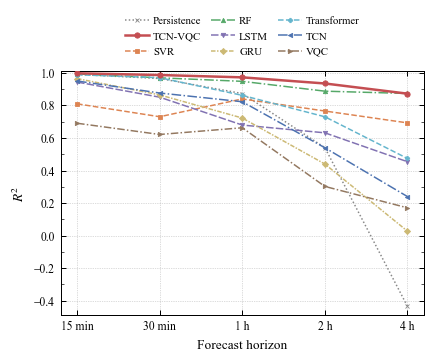

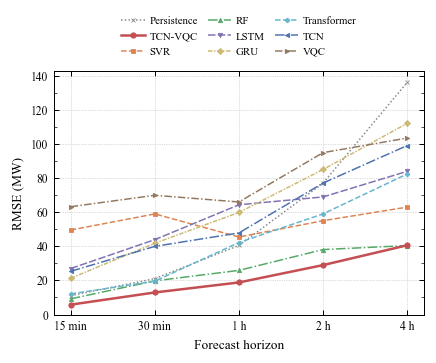

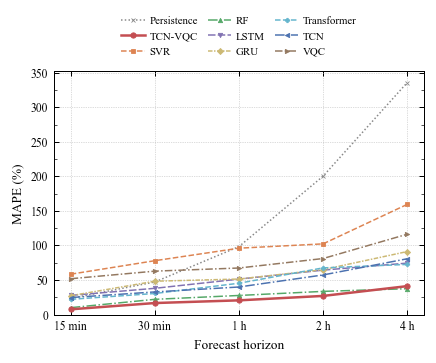

In [30]:
# --- R2 / RMSE / MAPE vs. forecast horizon: one separate IEEE-style figure per metric ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6.5,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

# distinct line style + marker per model, so curves stay separable in grayscale print
LINESTYLES = {
    "Persistence": (0, (1, 1.5)),
    "TCN-VQC":     "-",
    "SVR":         "--",
    "RF":          "-.",
    "LSTM":        (0, (5, 1.5)),
    "GRU":         (0, (3, 1, 1, 1)),
    "Transformer": "--",
    "TCN":         "-.",
    "VQC":         (0, (5, 1.5, 1, 1.5)),
}
MARKERS = {
    "Persistence": "x", "TCN-VQC": "o", "SVR": "s", "RF": "^", "LSTM": "v",
    "GRU": "D", "Transformer": "P", "TCN": "<", "VQC": ">",
}

FIG_SIZE = (3.5, 2.9)          # IEEE single column (3.5 in). Use (7.16, 3.2) for a double-column figure.
out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

metrics = [
    ("R2",     r"$R^2$",    "horizon_sweep_R2"),
    ("RMSE",   "RMSE (MW)", "horizon_sweep_RMSE"),
    ("MAPE_%", "MAPE (%)",  "horizon_sweep_MAPE"),
]

x = np.arange(len(_h_order))

with mpl.rc_context(IEEE_RC):
    for col, ylabel, fname in metrics:
        fig, ax = plt.subplots(figsize=FIG_SIZE)

        for name in _m_order:
            sub = MULTI_DF[MULTI_DF["Model"] == name].set_index("Horizon").reindex(_h_order)
            proposed = (name == "TCN-VQC")
            ax.plot(x, sub[col].values,
                    color=MODEL_COLORS[name], linestyle=LINESTYLES.get(name, "-"),
                    marker=MARKERS.get(name, "o"), markersize=3.2 if proposed else 2.6,
                    linewidth=1.5 if proposed else 0.9, markeredgewidth=0.5,
                    label=name, zorder=9 if proposed else 5)

        ax.set_xticks(x)
        ax.set_xticklabels(_h_order)
        ax.set_xlim(-0.2, len(x) - 0.8)
        ax.set_xlabel("Forecast horizon")
        ax.set_ylabel(ylabel)
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))
        ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")

        if col == "R2":
            ax.set_ylim(max(-0.5, np.nanmin(MULTI_DF["R2"].values) - 0.05), 1.01)
        else:
            ax.set_ylim(bottom=0)

        # legend above the axes, no frame, so it covers no curve
        ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False,
                  handlelength=2.2, columnspacing=0.9, handletextpad=0.4)

        fig.tight_layout(pad=0.3)

        # ---------- save: 600 dpi PNG + vector PDF ----------
        fig.savefig(os.path.join(out_dir, fname + ".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
        fig.savefig(os.path.join(out_dir, fname + ".pdf"), bbox_inches="tight", pad_inches=0.02)
        plt.show()
        plt.close(fig)

## Actual vs forecasted power generation 

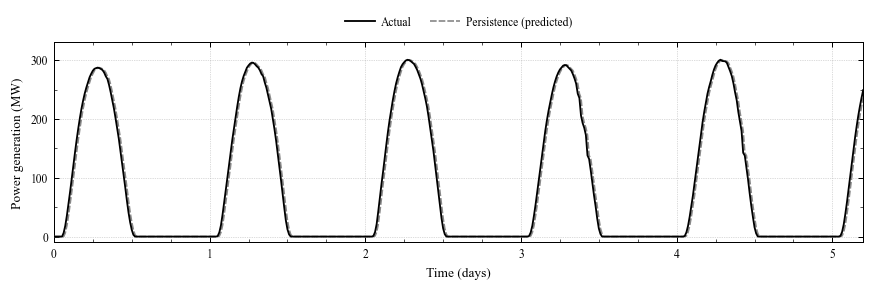

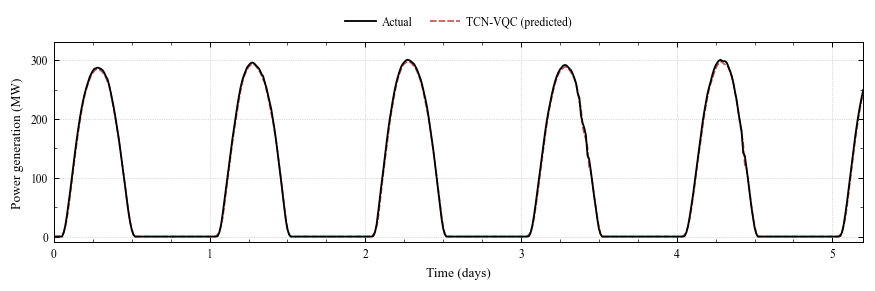

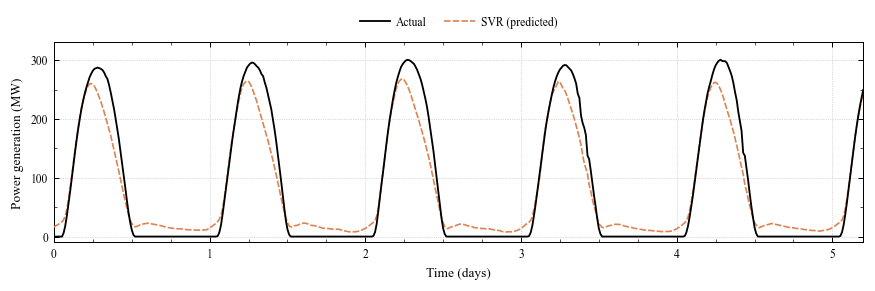

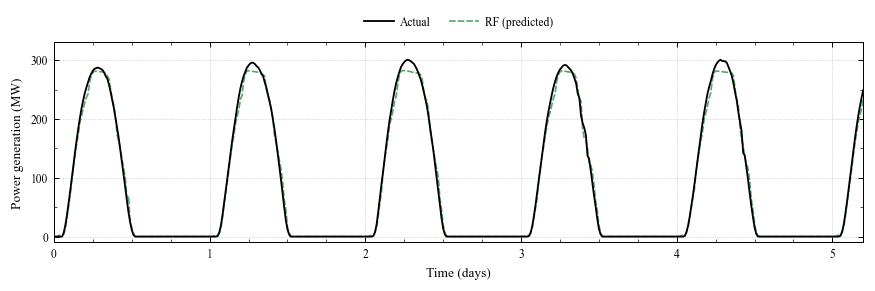

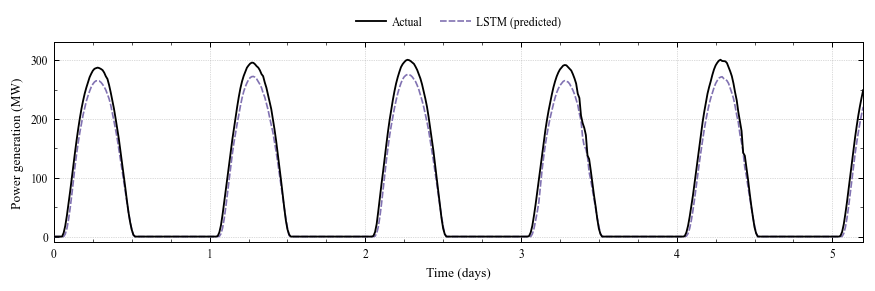

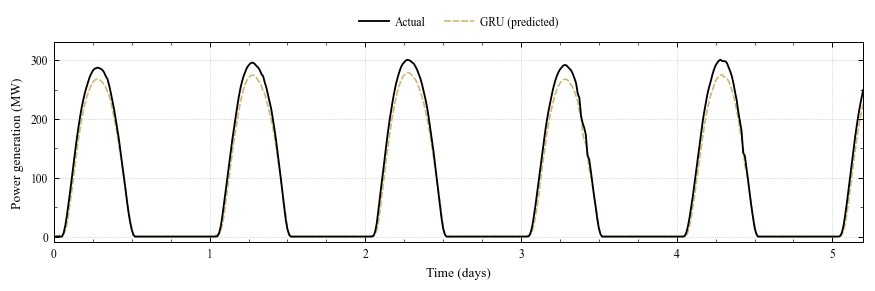

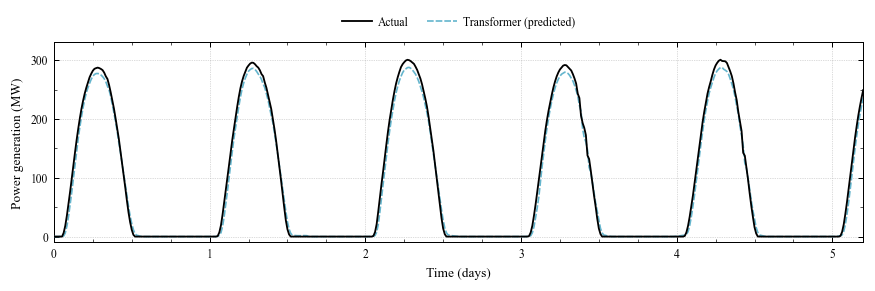

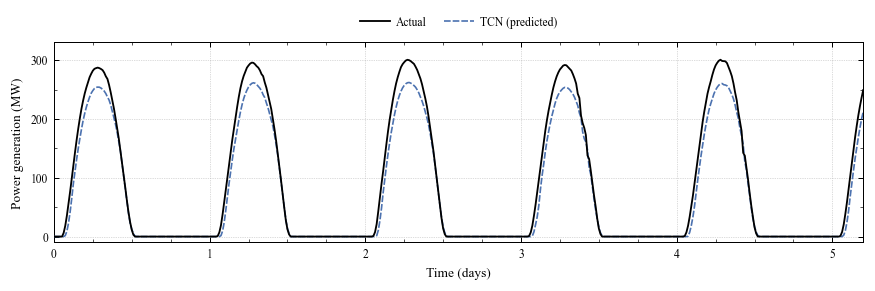

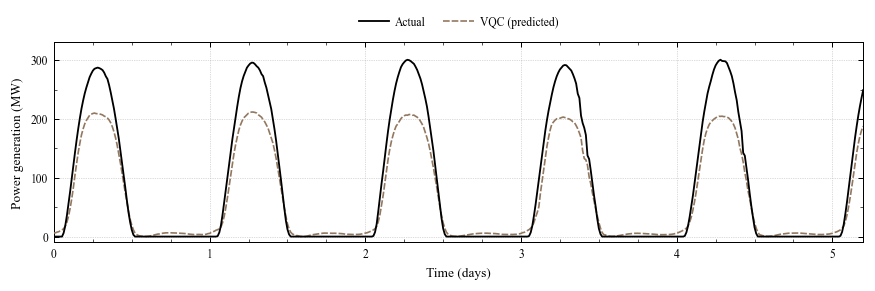

In [31]:
# --- Actual vs Predicted: one separate IEEE-style figure per model ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

n_points = 500                                       # first N test points, as in your original
X_IN_DAYS = True                                     # True: x-axis in days; False: sample index
FIG_SIZE = (7.16, 2.3)                               # IEEE double-column width (7.16 in)
out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

step_min = CFG.time_step_minutes
x_idx = np.arange(n_points)
x_vals = x_idx * step_min / (60 * 24) if X_IN_DAYS else x_idx

with mpl.rc_context(IEEE_RC):
    for name in RESULTS.keys():
        y_true, y_pred = PREDICTIONS[name]
        y_true = np.asarray(y_true, float).ravel()[:n_points]
        y_pred = np.clip(np.asarray(y_pred, float).ravel()[:n_points], 0, None)   # PV >= 0

        fig, ax = plt.subplots(figsize=FIG_SIZE)
        ax.plot(x_vals, y_true, color="black", linestyle="-", linewidth=1.1,
                label="Actual", zorder=6)
        ax.plot(x_vals, y_pred, color=MODEL_COLORS[name], linestyle=(0, (4, 1.2)),
                linewidth=1.0, label=f"{name} (predicted)", zorder=5)

        ax.set_xlim(x_vals[0], x_vals[-1])
        ax.set_ylim(-10, 330)
        ax.yaxis.set_major_locator(MultipleLocator(100))
        ax.yaxis.set_minor_locator(MultipleLocator(50))
        if X_IN_DAYS:
            ax.xaxis.set_major_locator(MultipleLocator(1))
            ax.xaxis.set_minor_locator(MultipleLocator(0.25))
            ax.set_xlabel("Time (days)")
        else:
            ax.xaxis.set_major_locator(MultipleLocator(100))
            ax.xaxis.set_minor_locator(MultipleLocator(25))
            ax.set_xlabel(f"Test sample index ({step_min}-min steps)")
        ax.set_ylabel("Power generation (MW)")
        ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")

        # legend above the axes, no frame, so it covers no curve
        ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False,
                  handlelength=2.6, columnspacing=1.5, handletextpad=0.5)

        fig.tight_layout(pad=0.3)

        # ---------- save: 600 dpi PNG + vector PDF ----------
        fname = "actual_vs_predicted_" + name.replace(" ", "_")
        fig.savefig(os.path.join(out_dir, fname + ".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
        fig.savefig(os.path.join(out_dir, fname + ".pdf"), bbox_inches="tight", pad_inches=0.02)
        plt.show()
        plt.close(fig)

## Actual vs predicted - all models on one axis for first five hundered test step 

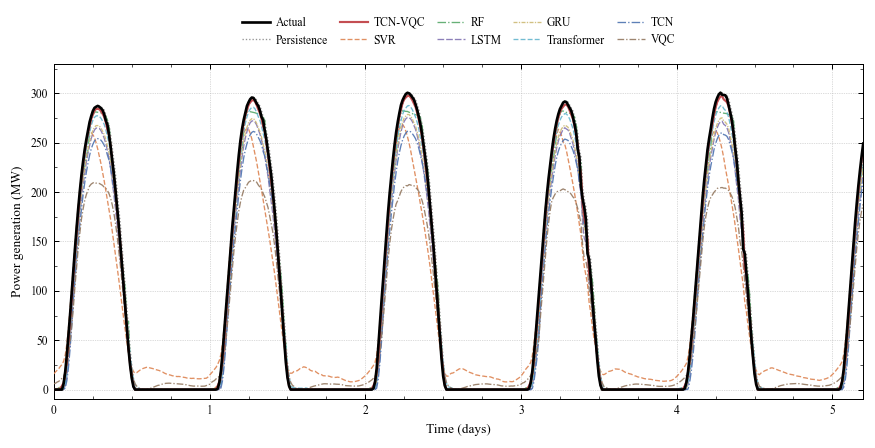

In [32]:
# --- Actual vs Predicted: ALL models on ONE axis (IEEE Transactions style) ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

# distinct line style per model, so curves stay separable in grayscale print
LINESTYLES = {
    "Persistence": (0, (1, 1.5)),
    "TCN-VQC":     "-",
    "SVR":         "--",
    "RF":          "-.",
    "LSTM":        (0, (5, 1.5)),
    "GRU":         (0, (3, 1, 1, 1)),
    "Transformer": "--",
    "TCN":         "-.",
    "VQC":         (0, (5, 1.5, 1, 1.5)),
}

n_points = 500                                       # first N test points
X_IN_DAYS = True                                     # True: x-axis in days; False: sample index
MODELS_TO_PLOT = list(RESULTS.keys())                # e.g. ["Persistence", "RF", "TCN-VQC"] for a cleaner plot
FIG_SIZE = (7.16, 3.6)                               # IEEE double-column width (7.16 in)

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

step_min = CFG.time_step_minutes
x_idx = np.arange(n_points)
x_vals = x_idx * step_min / (60 * 24) if X_IN_DAYS else x_idx

# actual is the same for every model, so take it once
y_true = np.asarray(PREDICTIONS[MODELS_TO_PLOT[0]][0], float).ravel()[:n_points]

with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=FIG_SIZE)

    for name in MODELS_TO_PLOT:
        y_pred = np.clip(np.asarray(PREDICTIONS[name][1], float).ravel()[:n_points], 0, None)   # PV >= 0
        proposed = (name == "TCN-VQC")
        ax.plot(x_vals, y_pred,
                color=MODEL_COLORS[name], linestyle=LINESTYLES.get(name, "-"),
                linewidth=1.3 if proposed else 0.8, alpha=1.0 if proposed else 0.9,
                label=name, zorder=8 if proposed else 4)

    # Actual last and thickest, so it sits on top
    ax.plot(x_vals, y_true, color="black", linewidth=1.6, label="Actual", zorder=10)

    ax.set_xlim(x_vals[0], x_vals[-1])
    ax.set_ylim(-10, 330)
    ax.yaxis.set_major_locator(MultipleLocator(50))
    ax.yaxis.set_minor_locator(MultipleLocator(25))
    if X_IN_DAYS:
        ax.xaxis.set_major_locator(MultipleLocator(1))
        ax.xaxis.set_minor_locator(MultipleLocator(0.25))
        ax.set_xlabel("Time (days)")
    else:
        ax.xaxis.set_major_locator(MultipleLocator(100))
        ax.xaxis.set_minor_locator(MultipleLocator(25))
        ax.set_xlabel(f"Test sample index ({step_min}-min steps)")
    ax.set_ylabel("Power generation (MW)")
    ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")

    # legend above the axes in rows, Actual first, so it covers no curve
    handles, labels = ax.get_legend_handles_labels()
    order = [labels.index("Actual")] + [i for i, l in enumerate(labels) if l != "Actual"]
    ax.legend([handles[i] for i in order], [labels[i] for i in order],
              loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=5, frameon=False,
              handlelength=2.4, columnspacing=1.0, handletextpad=0.5)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig(os.path.join(out_dir, "actual_vs_predicted_all_models.png"),
                dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, "actual_vs_predicted_all_models.pdf"),
                bbox_inches="tight", pad_inches=0.02)
    plt.show()

## Training/ Validation loss curves - all trained models 

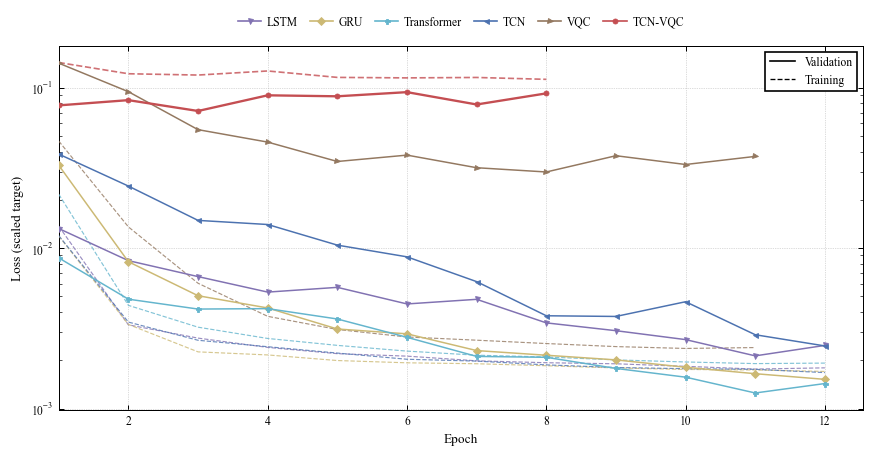

In [33]:
# --- Training / Validation Loss Curves (IEEE Transactions style) ---
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

# one marker per model so curves stay separable in grayscale print
MARKERS = {
    "TCN-VQC": "o", "LSTM": "v", "GRU": "D", "Transformer": "P",
    "TCN": "<", "VQC": ">", "SVR": "s", "RF": "^", "Persistence": "x",
}

with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=(7.16, 3.4))      # IEEE double-column width (7.16 in)

    for name in TRAINED_NN_MODELS:
        proposed = (name == "TCN-VQC")
        color = MODEL_COLORS[name]
        mk = MARKERS.get(name, "o")

        val = HISTORIES[name]["val_loss"]
        if val is not None and len(val) > 0:
            ep = np.arange(1, len(val) + 1)                           # epochs start at 1
            ax.plot(ep, val, color=color, linestyle="-", linewidth=1.4 if proposed else 0.9,
                    marker=mk, markersize=3, markevery=max(1, len(val) // 10),
                    markeredgewidth=0.5, zorder=9 if proposed else 5)

        tr = HISTORIES[name]["train_loss"]
        if tr is not None and len(tr) > 0:
            ep = np.arange(1, len(tr) + 1)
            ax.plot(ep, tr, color=color, linestyle="--", linewidth=1.0 if proposed else 0.7,
                    alpha=0.8, zorder=4)

    ax.set_yscale("log")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss (scaled target)")
    ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.set_xlim(left=1)

    # legend part 1: models (colour + marker)
    model_handles = [
        Line2D([0], [0], color=MODEL_COLORS[n], marker=MARKERS.get(n, "o"), markersize=3,
               linewidth=1.0, markeredgewidth=0.5, label=n)
        for n in TRAINED_NN_MODELS
    ]
    # legend part 2: line type (solid = validation, dashed = training)
    style_handles = [
        Line2D([0], [0], color="black", linestyle="-", linewidth=1.0, label="Validation"),
        Line2D([0], [0], color="black", linestyle="--", linewidth=0.8, label="Training"),
    ]
    leg1 = ax.legend(handles=model_handles, loc="lower center", bbox_to_anchor=(0.5, 1.02),
                     ncol=len(model_handles), frameon=False, handlelength=2.0,
                     columnspacing=1.0, handletextpad=0.5)
    ax.add_artist(leg1)
    ax.legend(handles=style_handles, loc="upper right", frameon=True, fancybox=False,
              edgecolor="black", framealpha=1.0, borderpad=0.4, handlelength=2.2)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig("training_loss.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig("training_loss.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()

## Sactter plot - predicted vs actual , all models 

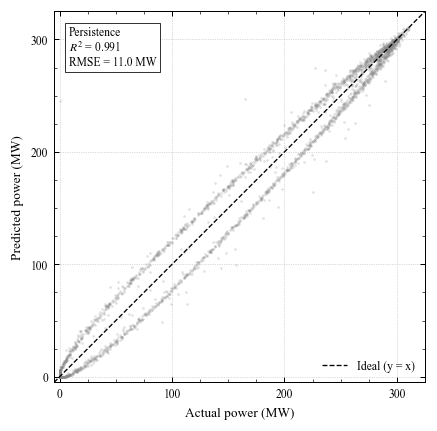

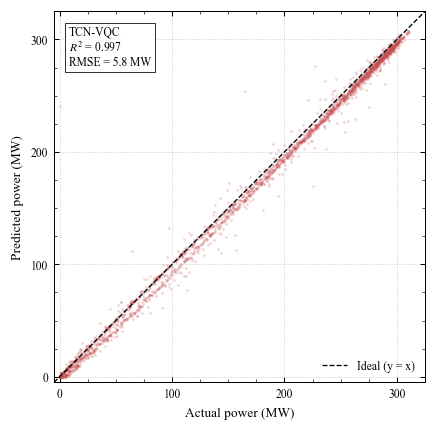

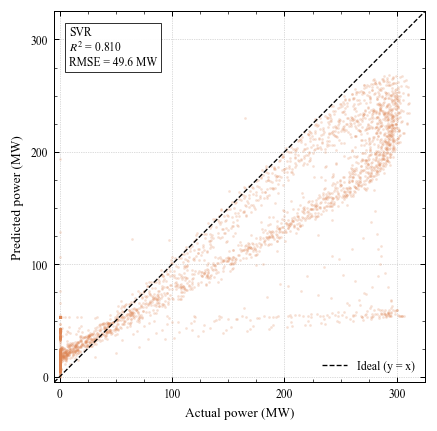

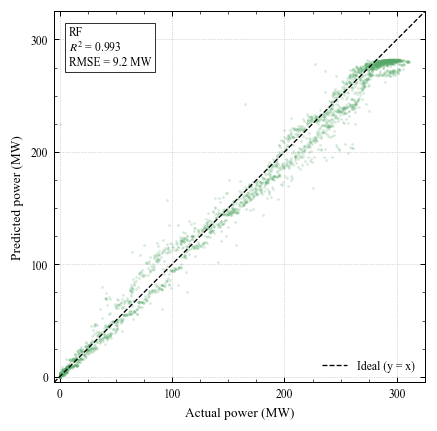

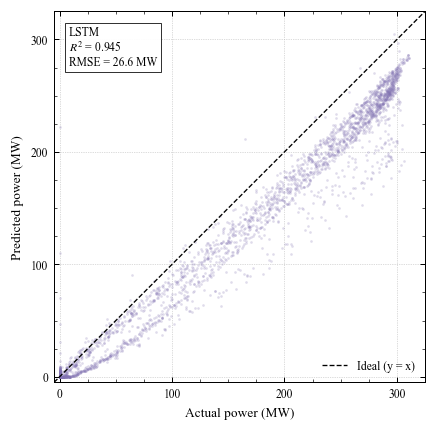

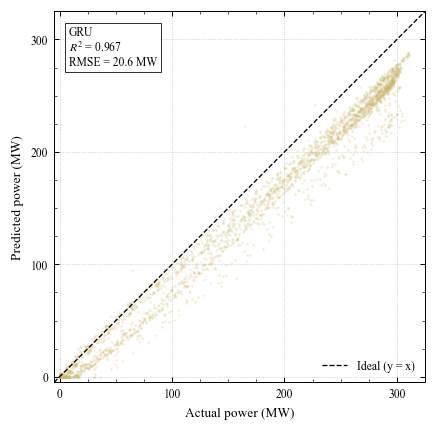

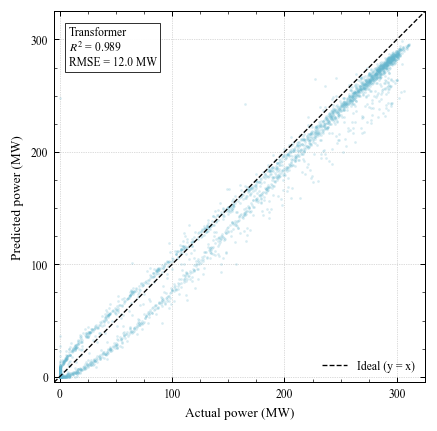

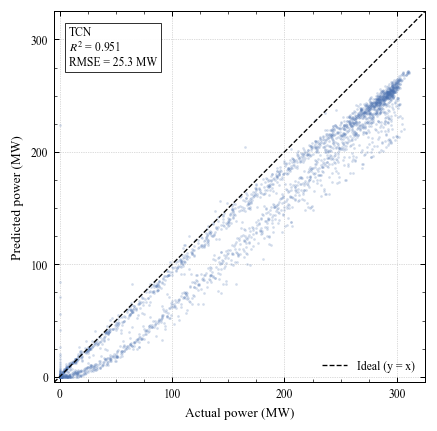

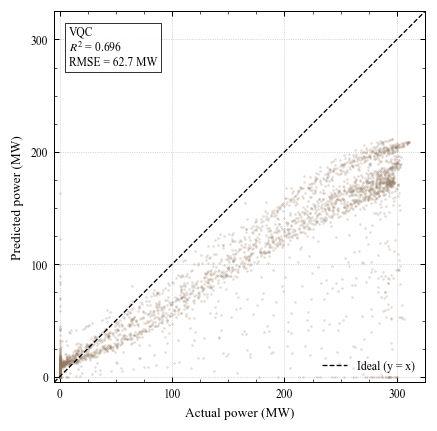

In [34]:
# --- Predicted vs Actual scatter: one separate IEEE-style figure per model ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

FIG_SIZE = (3.5, 3.5)                  # IEEE single column (3.5 in); square, so the 1:1 line is at 45 degrees
CLIP_AT_ZERO = True                    # PV power can't be negative (same as the other figures)
LIM = (-5, 325)

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

with mpl.rc_context(IEEE_RC):
    for name in RESULTS.keys():
        y_true, y_pred = PREDICTIONS[name]
        y_true = np.asarray(y_true, float).ravel()
        y_pred = np.asarray(y_pred, float).ravel()
        if CLIP_AT_ZERO:
            y_pred = np.clip(y_pred, 0, None)

        # metrics from the plotted data
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - y_true.mean()) ** 2)
        r2 = 1.0 - ss_res / ss_tot
        rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))

        fig, ax = plt.subplots(figsize=FIG_SIZE)
        ax.scatter(y_true, y_pred, s=2.5, alpha=0.25, color=MODEL_COLORS[name],
                   linewidths=0, rasterized=True, zorder=3)         # rasterized: keeps the PDF small
        ax.plot(LIM, LIM, color="black", linestyle="--", linewidth=0.8, zorder=4,
                label="Ideal (y = x)")

        ax.set_xlim(LIM)
        ax.set_ylim(LIM)
        ax.set_aspect("equal", adjustable="box")
        ax.xaxis.set_major_locator(MultipleLocator(100))
        ax.yaxis.set_major_locator(MultipleLocator(100))
        ax.xaxis.set_minor_locator(MultipleLocator(25))
        ax.yaxis.set_minor_locator(MultipleLocator(25))
        ax.set_xlabel("Actual power (MW)")
        ax.set_ylabel("Predicted power (MW)")
        ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")

        # model name and metrics in an in-axes box (replaces the title, which IEEE puts in the caption)
        ax.text(0.04, 0.96, f"{name}\n$R^2$ = {r2:.3f}\nRMSE = {rmse:.1f} MW",
                transform=ax.transAxes, ha="left", va="top", fontsize=7,
                bbox=dict(boxstyle="square,pad=0.3", facecolor="white", edgecolor="black",
                          linewidth=0.5, alpha=0.95), zorder=10)
        ax.legend(loc="lower right", frameon=False, handlelength=2.2)

        fig.tight_layout(pad=0.3)

        # ---------- save: 600 dpi PNG + vector PDF ----------
        fname = "scatter_" + name.replace(" ", "_")
        fig.savefig(os.path.join(out_dir, fname + ".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
        fig.savefig(os.path.join(out_dir, fname + ".pdf"), bbox_inches="tight", pad_inches=0.02, dpi=600)
        plt.show()
        plt.close(fig)

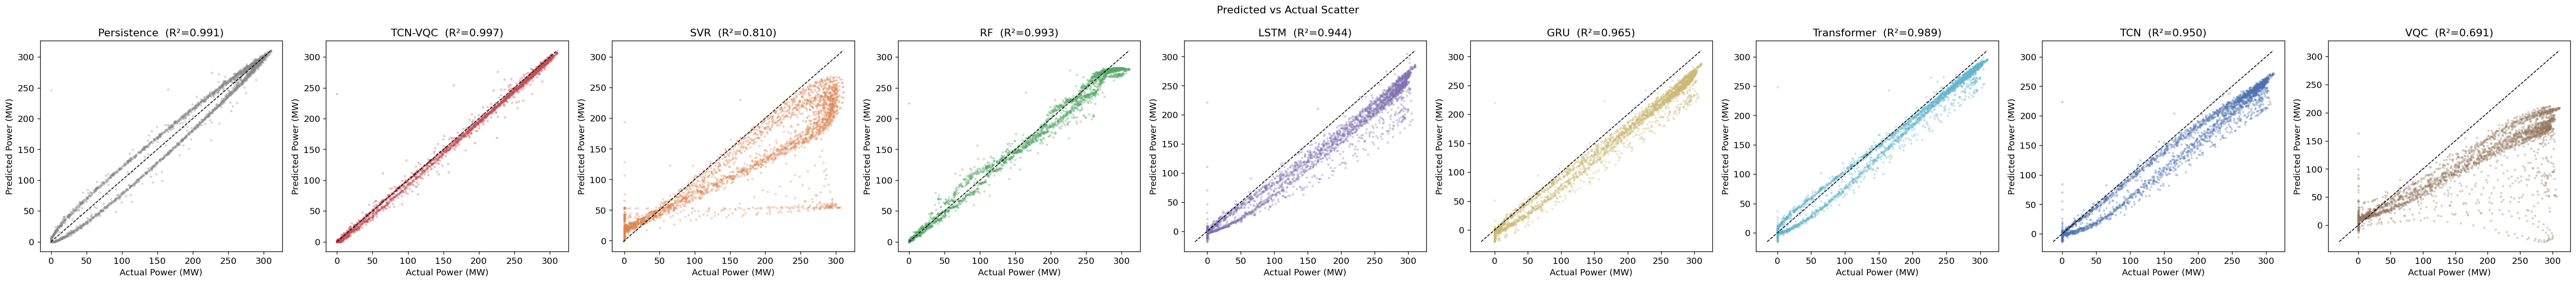

In [35]:
# --- Scatter: predicted vs actual ---
fig, axes = plt.subplots(1, len(RESULTS), figsize=(5 * len(RESULTS), 5))
for ax, name in zip(axes, RESULTS.keys()):
    y_true, y_pred = PREDICTIONS[name]
    ax.scatter(y_true, y_pred, s=4, alpha=0.25, color=MODEL_COLORS[name])
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_title(f"{name}  (R\u00b2={RESULTS[name]['R2']:.3f})")
    ax.set_xlabel("Actual Power (MW)")
    ax.set_ylabel("Predicted Power (MW)")
fig.suptitle("Predicted vs Actual Scatter")
fig.tight_layout()
_savefig(fig, "scatter")


## Residual Plots for all comparison models 

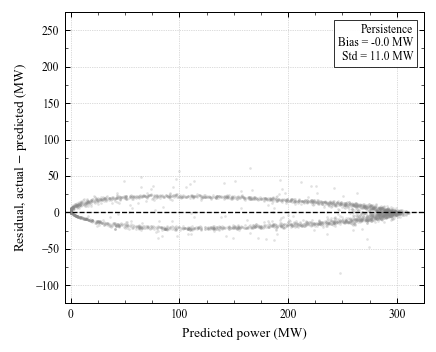

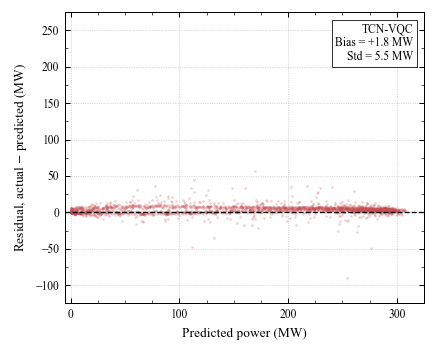

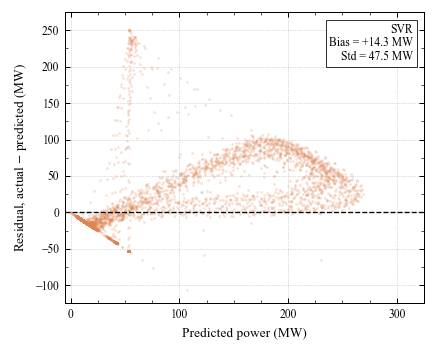

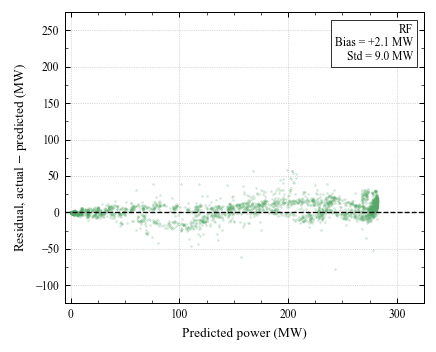

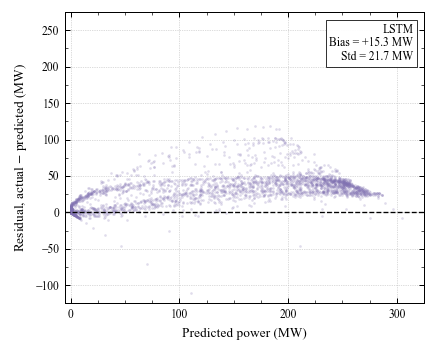

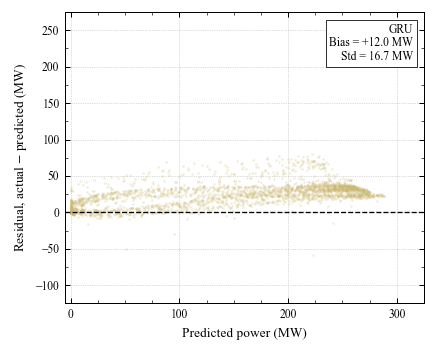

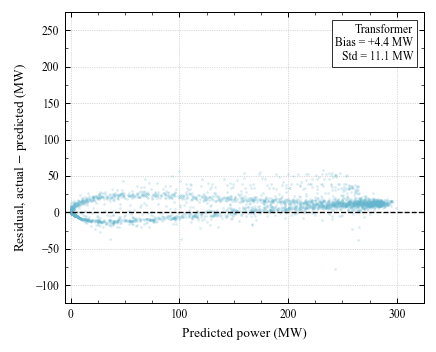

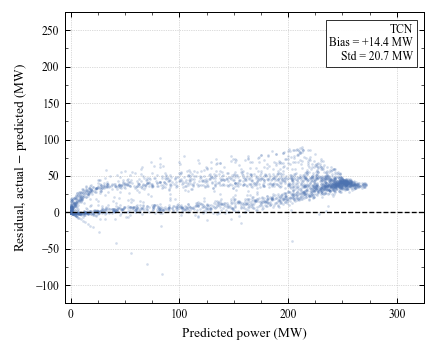

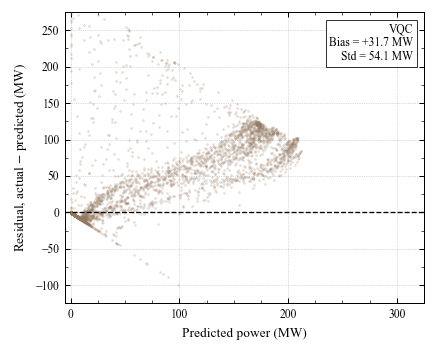

In [36]:
# --- Residual plots: one separate IEEE-style figure per model ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, AutoMinorLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

FIG_SIZE = (3.5, 2.8)                  # IEEE single column (3.5 in)
CLIP_AT_ZERO = True                    # PV power can't be negative (same as the other figures)
SHARED_Y = True                        # same y-range for every model, so the figures are comparable

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

# ---------- prepare residuals for every model ----------
data = {}
for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    y_true = np.asarray(y_true, float).ravel()
    y_pred = np.asarray(y_pred, float).ravel()
    if CLIP_AT_ZERO:
        y_pred = np.clip(y_pred, 0, None)
    data[name] = (y_pred, y_true - y_pred)           # residual = Actual - Predicted

all_res = np.concatenate([r for _, r in data.values()])
y_lo = np.floor(np.percentile(all_res, 0.1) / 50) * 50 - 25      # robust limits: ignore a few extreme outliers
y_hi = np.ceil(np.percentile(all_res, 99.9) / 50) * 50 + 25
x_lim = (-5, 325)

with mpl.rc_context(IEEE_RC):
    for name, (y_pred, res) in data.items():
        bias = res.mean()
        std = res.std()

        fig, ax = plt.subplots(figsize=FIG_SIZE)
        ax.scatter(y_pred, res, s=2.5, alpha=0.25, color=MODEL_COLORS[name],
                   linewidths=0, rasterized=True, zorder=3)      # rasterized: keeps the PDF small
        ax.axhline(0, color="black", linewidth=0.8, linestyle="--", zorder=4)

        ax.set_xlim(x_lim)
        if SHARED_Y:
            ax.set_ylim(y_lo, y_hi)
        ax.xaxis.set_major_locator(MultipleLocator(100))
        ax.xaxis.set_minor_locator(MultipleLocator(25))
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))
        ax.set_xlabel("Predicted power (MW)")
        ax.set_ylabel("Residual, actual $-$ predicted (MW)")
        ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")

        # model name and statistics in an in-axes box (replaces the title, which IEEE puts in the caption)
        ax.text(0.97, 0.96, f"{name}\nBias = {bias:+.1f} MW\nStd = {std:.1f} MW",
                transform=ax.transAxes, ha="right", va="top", fontsize=7,
                bbox=dict(boxstyle="square,pad=0.3", facecolor="white", edgecolor="black",
                          linewidth=0.5, alpha=0.95), zorder=10)

        fig.tight_layout(pad=0.3)

        # ---------- save: 600 dpi PNG + vector PDF ----------
        fname = "residuals_" + name.replace(" ", "_")
        fig.savefig(os.path.join(out_dir, fname + ".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
        fig.savefig(os.path.join(out_dir, fname + ".pdf"), bbox_inches="tight", pad_inches=0.02, dpi=600)
        plt.show()
        plt.close(fig)

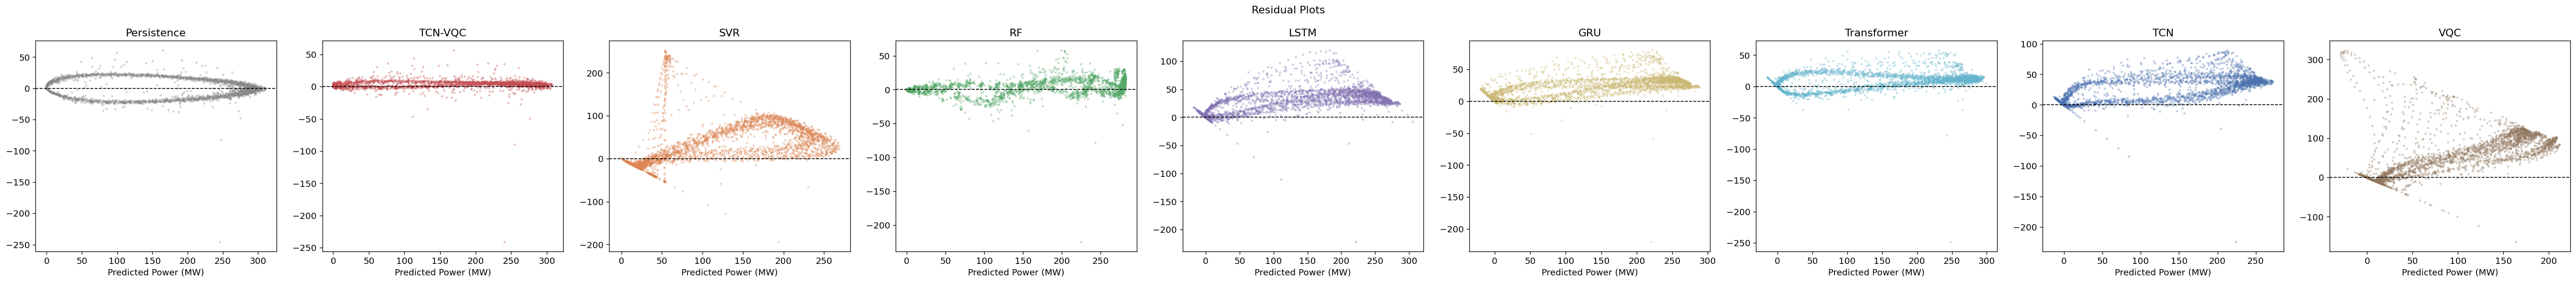

In [37]:
# --- Residual plots ---
fig, axes = plt.subplots(1, len(RESULTS), figsize=(5 * len(RESULTS), 5))
for ax, name in zip(axes, RESULTS.keys()):
    y_true, y_pred = PREDICTIONS[name]
    residuals = y_true - y_pred
    ax.scatter(y_pred, residuals, s=4, alpha=0.25, color=MODEL_COLORS[name])
    ax.axhline(0, color="black", linewidth=1, linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Predicted Power (MW)")
fig.suptitle("Residual Plots")
fig.tight_layout()
_savefig(fig, "residuals")


## Model Comparison across all metrices

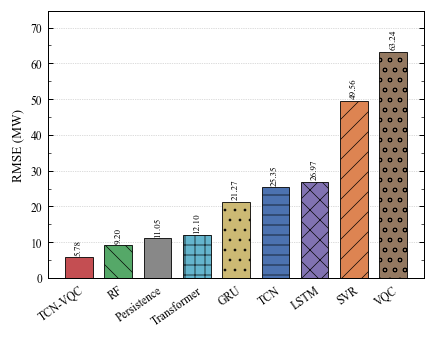

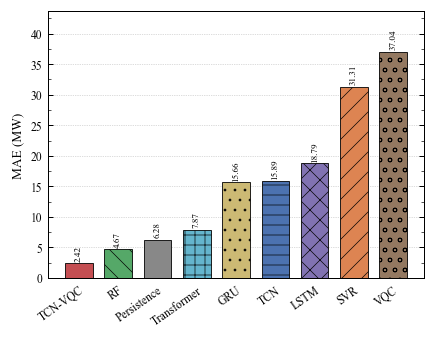

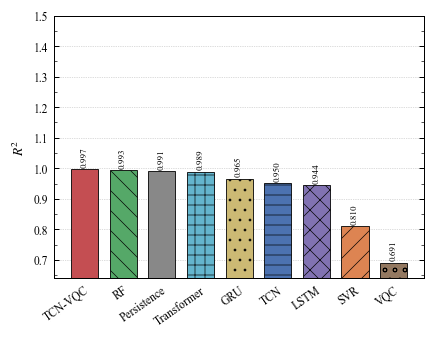

skipping MAPE: not in METRICS_DF


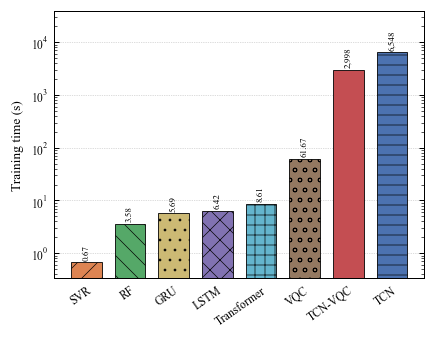

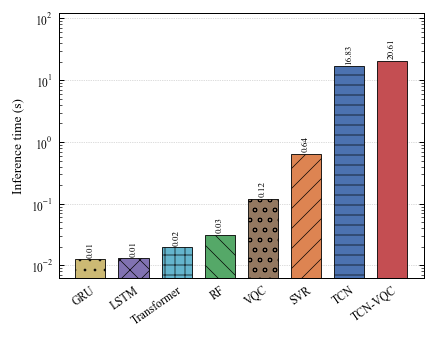

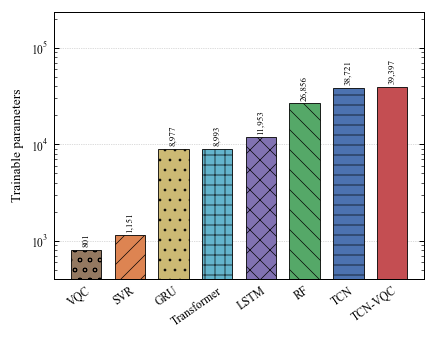

In [38]:
# --- Metric comparison bar charts: one separate IEEE-style figure per metric ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "ytick.minor.size": 1.8,
    "ytick.right": True,
    "hatch.linewidth": 0.4,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

# hatch per model, so bars stay distinguishable in grayscale print
HATCHES = {
    "Persistence": "", "TCN-VQC": "", "SVR": "//", "RF": "\\\\", "LSTM": "xx",
    "GRU": "..", "Transformer": "++", "TCN": "--", "VQC": "oo",
}

# (column, axis label, sort ascending?, log scale?)
metric_specs = [
    ("RMSE",             "RMSE (MW)",              True,  False),
    ("MAE",              "MAE (MW)",               True,  False),
    ("R2",               r"$R^2$",                 False, False),
    ("MAPE",             "MAPE (%)",               True,  False),
    ("Training_Time_s",  "Training time (s)",      True,  True),
    ("Inference_Time_s", "Inference time (s)",     True,  True),
    ("Num_Params",       "Trainable parameters",   True,  True),
]

FIG_SIZE = (3.5, 2.7)                  # IEEE single column (3.5 in). Use (7.16, 2.8) for double-column.
out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

def fmt(v, col):
    if col == "R2":
        return f"{v:.3f}"
    if col in ("Num_Params",):
        return f"{v:,.0f}"
    if col in ("Training_Time_s", "Inference_Time_s"):
        return f"{v:.2f}" if v < 100 else f"{v:,.0f}"
    return f"{v:.2f}"

with mpl.rc_context(IEEE_RC):
    for col, label, ascending, use_log in metric_specs:
        if col not in METRICS_DF.columns:
            print(f"skipping {col}: not in METRICS_DF")
            continue

        ordered = METRICS_DF[["Model", col]].dropna().sort_values(col, ascending=ascending)
        if use_log:
            ordered = ordered[ordered[col] > 0]          # log axis cannot show 0 / negative (e.g. models with no parameters)
        if ordered.empty:
            print(f"skipping {col}: no valid values")
            continue

        models = ordered["Model"].tolist()
        vals = ordered[col].values.astype(float)
        x = np.arange(len(models))

        fig, ax = plt.subplots(figsize=FIG_SIZE)
        bars = ax.bar(x, vals, width=0.7,
                      color=[MODEL_COLORS[m] for m in models],
                      edgecolor="black", linewidth=0.5, zorder=3)
        for b, m in zip(bars, models):
            b.set_hatch(HATCHES.get(m, ""))

        if use_log:
            ax.set_yscale("log")
        else:
            ax.yaxis.set_minor_locator(AutoMinorLocator(2))
            if col != "R2":
                ax.set_ylim(0, vals.max() * 1.18)        # headroom for the value labels
            else:
                ax.set_ylim(max(0.0, vals.min() - 0.05), 1.5)

        # value labels on top of the bars
        for xi, v in zip(x, vals):
            ax.annotate(fmt(v, col), (xi, v), xytext=(0, 1.5), textcoords="offset points",
                        ha="center", va="bottom", fontsize=5.5, rotation=90 if len(models) > 6 else 0)
        if use_log:
            ax.set_ylim(vals.min() / 2, vals.max() * 6)  # headroom on log scale

        ax.set_xticks(x)
        ax.set_xticklabels(models, rotation=35, ha="right", rotation_mode="anchor")
        ax.set_ylabel(label)
        ax.grid(True, axis="y", which="major", linestyle=":", linewidth=0.4, color="0.7")
        ax.set_axisbelow(True)

        fig.tight_layout(pad=0.3)

        # ---------- save: 600 dpi PNG + vector PDF ----------
        fname = "metric_" + col.replace("%", "pct")
        fig.savefig(os.path.join(out_dir, fname + ".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
        fig.savefig(os.path.join(out_dir, fname + ".pdf"), bbox_inches="tight", pad_inches=0.02)
        plt.show()
        plt.close(fig)

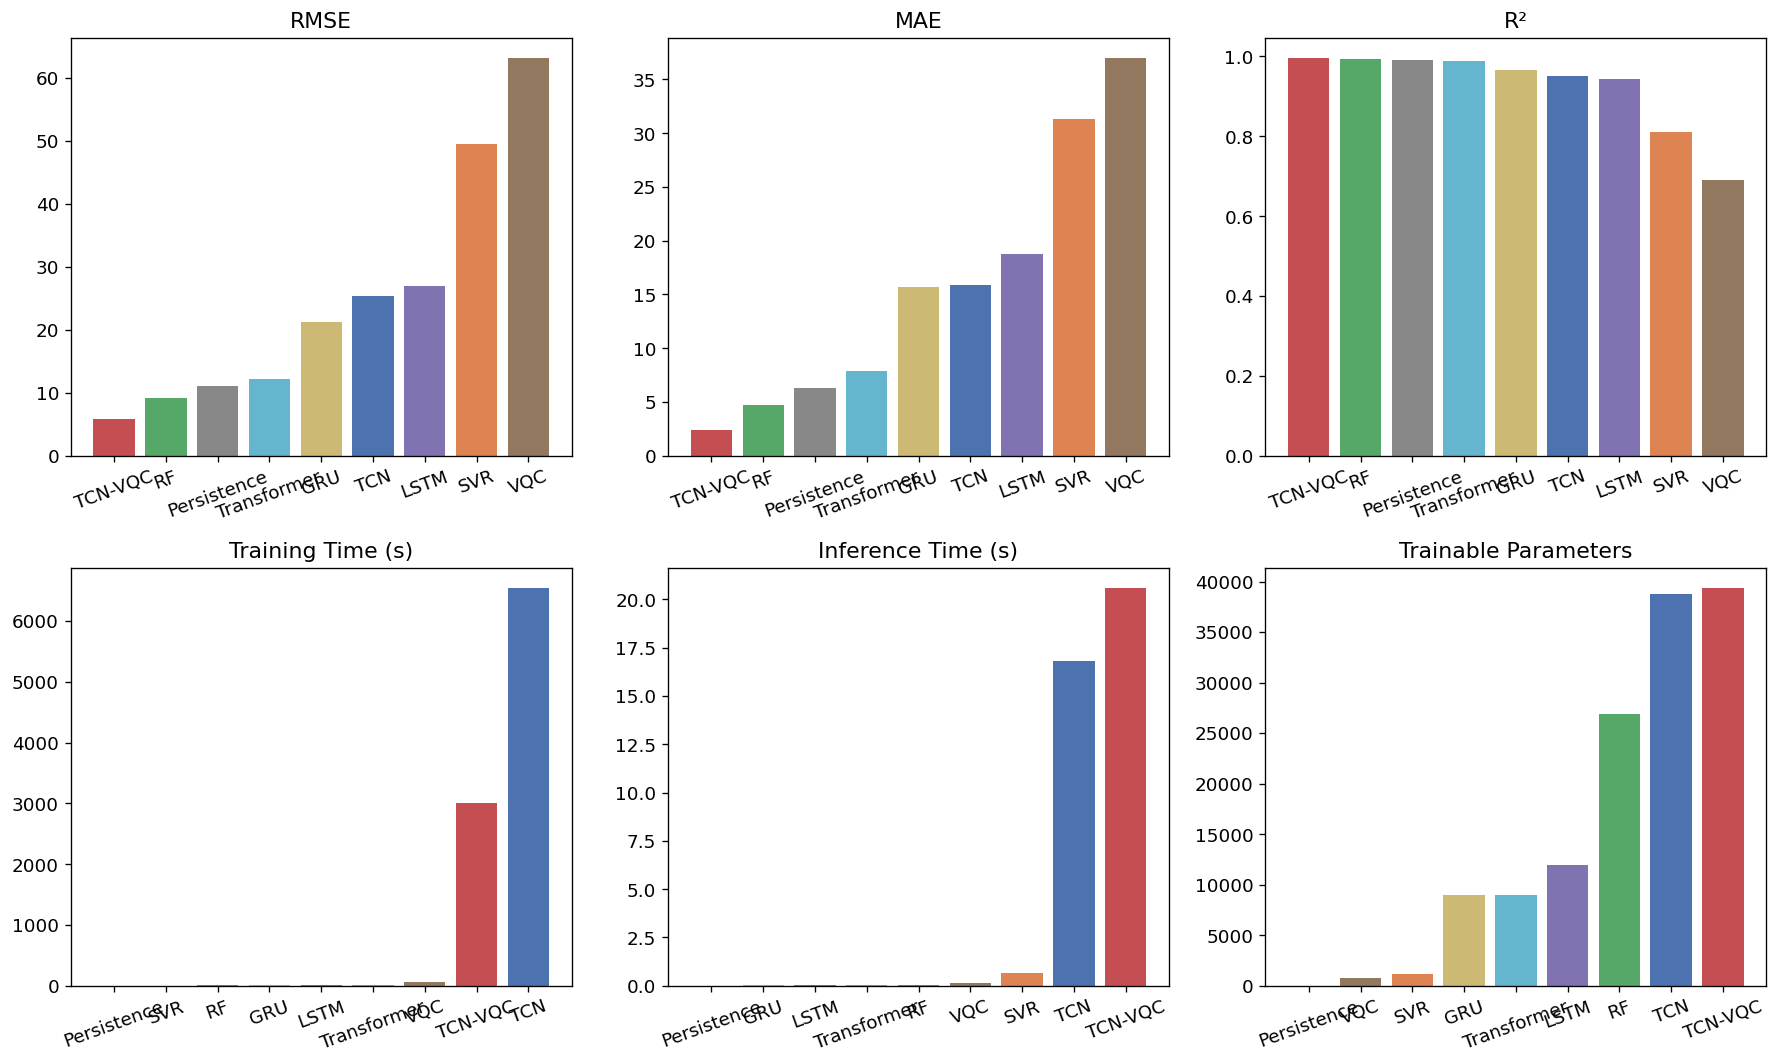

In [39]:
# --- Metric comparison bar charts (RMSE, MAE, R2, Training/Inference time) ---
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
metric_specs = [
    ("RMSE", "RMSE", True), ("MAE", "MAE", True), ("R2", "R\u00b2", False),
    ("Training_Time_s", "Training Time (s)", True), ("Inference_Time_s", "Inference Time (s)", True),
    ("Num_Params", "Trainable Parameters", True), ("MAPE" , "MAPE" , True)
]
for ax, (col, label, ascending) in zip(axes.ravel(), metric_specs):
    ordered = METRICS_DF.sort_values(col, ascending=ascending)
    colors = [MODEL_COLORS[m] for m in ordered["Model"]]
    ax.bar(ordered["Model"], ordered[col], color=colors)
    ax.set_title(label)
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
_savefig(fig, "metric_comparison")


## per month rmse comparison - test splits 

In [40]:
print(DATA["test_months"][:10], np.unique(DATA["test_months"]))
print({k: v["Month"].tolist() for k, v in list(PER_MONTH_TABLES.items())[:1]})

[2. 2. 2. 2. 2. 2. 2. 2. 2. 2.] [2. 3.]
{'Persistence': [2, 3]}


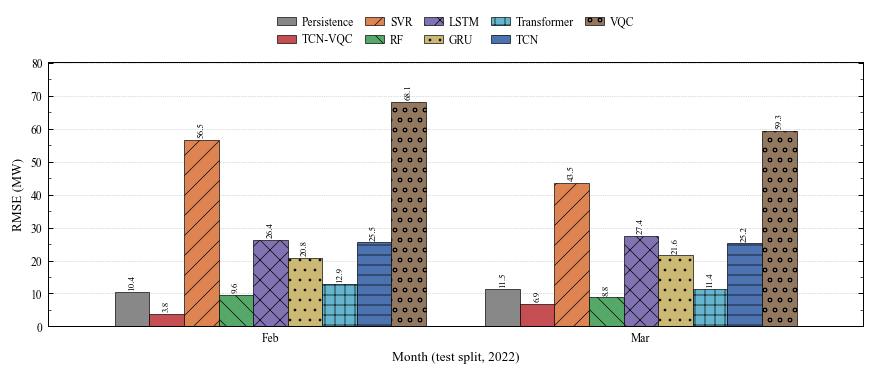

In [41]:
# --- Per-month RMSE comparison 
import os
import calendar
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "ytick.minor.size": 1.8,
    "ytick.right": True,
    "hatch.linewidth": 0.4,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

# hatch per model, so bars stay distinguishable in grayscale print
HATCHES = {
    "Persistence": "", "TCN-VQC": "", "SVR": "//", "RF": "\\\\", "LSTM": "xx",
    "GRU": "..", "Transformer": "++", "TCN": "--", "VQC": "oo",
}

FIG_SIZE = (7.16, 3.0)                 # IEEE double-column width (7.16 in)
SHOW_VALUES = True                     # print the RMSE value above each bar

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

months_sorted = sorted(int(m) for m in np.unique(DATA["test_months"]))     # float -> int
month_labels = [calendar.month_abbr[m] for m in months_sorted]            # Feb, Mar
x = np.arange(len(months_sorted))
n_models = len(RESULTS)
group_w = 0.84                                                            # total width of one month group
width = group_w / n_models

with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=FIG_SIZE)

    ymax = 0.0
    for i, name in enumerate(RESULTS.keys()):
        df_month = PER_MONTH_TABLES[name].copy()
        df_month["Month"] = df_month["Month"].astype(int)                  # match int index
        vals = df_month.set_index("Month").reindex(months_sorted)["RMSE"].values.astype(float)
        ymax = max(ymax, np.nanmax(vals))

        xs = x + (i - (n_models - 1) / 2) * width                         # group is CENTRED on the tick
        ax.bar(xs, vals, width=width, color=MODEL_COLORS[name],
               edgecolor="black", linewidth=0.4, hatch=HATCHES.get(name, ""),
               label=name, zorder=3)
        if SHOW_VALUES:
            for xi, v in zip(xs, vals):
                if np.isfinite(v):
                    ax.annotate(f"{v:.1f}", (xi, v), xytext=(0, 1.5), textcoords="offset points",
                                ha="center", va="bottom", fontsize=5.5, rotation=90)

    ax.set_xticks(x)                                                      # tick at the centre of each group
    ax.set_xticklabels(month_labels)
    ax.set_xlim(-0.6, len(x) - 0.4)                                       # room on both sides, nothing clipped
    ax.set_ylim(0, ymax * 1.18)                                           # headroom for value labels
    ax.yaxis.set_major_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(5))
    ax.set_xlabel("Month (test split, 2022)")
    ax.set_ylabel("RMSE (MW)")
    ax.grid(True, axis="y", which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.set_axisbelow(True)

    # legend above the axes, no frame, so it covers no bar
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=5, frameon=False,
              handlelength=1.6, columnspacing=1.0, handletextpad=0.5)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig(os.path.join(out_dir, "per_month_rmse.png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, "per_month_rmse.pdf"), bbox_inches="tight", pad_inches=0.02)
    plt.show()

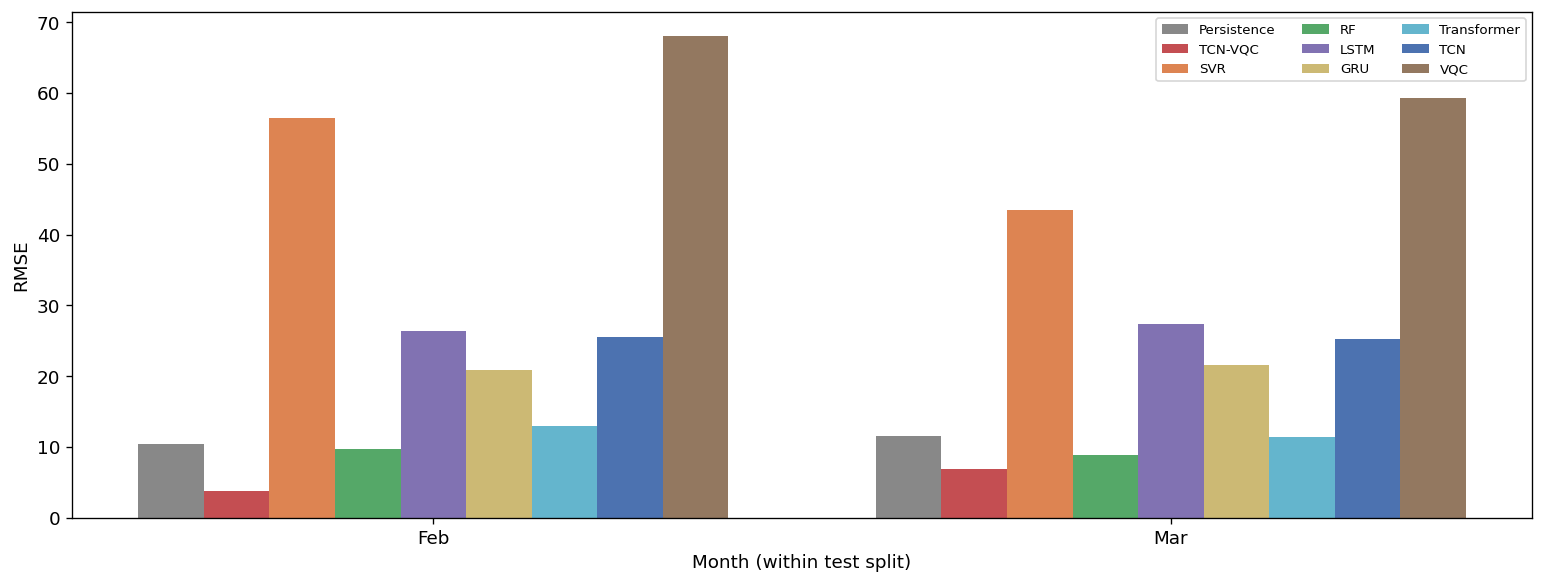

In [42]:
# --- Per-month RMSE comparison ---
import calendar

fig, ax = plt.subplots(figsize=(13, 5))
n_models = len(RESULTS)
width = 0.8 / n_models
months_sorted = sorted(int(m) for m in np.unique(DATA["test_months"]))     # FIX: float -> int
month_labels = [calendar.month_abbr[m] for m in months_sorted]            # FIX: Feb, Mar
x = np.arange(len(months_sorted))
for i, name in enumerate(RESULTS.keys()):
    df_month = PER_MONTH_TABLES[name].copy()
    df_month["Month"] = df_month["Month"].astype(int)                     # FIX: match int index
    df_month = df_month.set_index("Month").reindex(months_sorted)
    ax.bar(x + i * width, df_month["RMSE"], width=width, label=name, color=MODEL_COLORS[name])
ax.set_xticks(x + width * (n_models - 1) / 2)
ax.set_xticklabels(month_labels)
ax.set_xlabel("Month (within test split)")
ax.set_ylabel("RMSE")
ax.legend(fontsize=8, ncol=3)
fig.tight_layout()
_savefig(fig, "per_month_rmse")

In [46]:
# %% [markdown]
# ## 19. Paper tables (Tables I–V) for the TCN-VQC study
# 
# Run **after** Sections 13e–14 in the same kernel (needs `ALL_PREDICTIONS`, `RAW_DF`, `CFG`). Uses only the models and horizons your notebook already has — **no retraining** except Table V.
# 
# | Table | Source |
# |---|---|
# | I – models evaluated | static list of the notebook's models |
# | II – experimental configuration | read live from `CFG` and the circuit definition |
# | III – overall performance (MAE, RMSE, NMAE %, NRMSE %, R²) | recomputed from stored predictions |
# | IV – horizon-wise (NMAE, NRMSE, R²) | same predictions, every horizon you ran |
# | V – ablation | **5 new VQC trainings** (§19g) at one horizon — the only part that trains |
# 
# Normalised errors use `NORM_BASIS` (§19a) — set it to match your paper.

# %%
# ---- 19a. Settings for the paper tables (uses only models/horizons already in your notebook) ----
import time, math, itertools
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# (name in this notebook, short name printed in the tables, category for Table I)
PAPER_MODELS = [
    ("Persistence", "Pers.",   "Benchmark"),
    ("SVR",         "SVR",     "Machine learning"),
    ("RF",          "RF",      "Machine learning"),
    ("LSTM",        "LSTM",    "Deep learning"),
    ("GRU",         "GRU",     "Deep learning"),
    ("Transformer", "Trans.",  "Attention-based"),
    ("TCN",         "TCN",     "Deep learning"),
    ("VQC",         "VQC",     "Quantum"),
    ("TCN-VQC",     "TCN-VQC", "Quantum-enhanced"),      # proposed model
]
SHORT = {n: s for n, s, _ in PAPER_MODELS}
ORDER = [n for n, _, _ in PAPER_MODELS]

# horizons = whatever you already ran in Section 13e (no new training)
PAPER_HORIZONS = [(s, l) for s, l in CFG.horizons if l in ALL_PREDICTIONS]

# Normaliser for NMAE / NRMSE (%):  "peak" = max observed Actual power (MW) | "mean" = mean Actual | "value" = NORM_VALUE
# -> use the same definition as in your paper (e.g. plant rated capacity: NORM_BASIS="value"; NORM_VALUE=<MW>).
NORM_BASIS, NORM_VALUE = "peak", None

# Table III = average of the per-horizon metrics over these horizons (None -> all),
# or set e.g. OVERALL_HORIZONS = ["15 min"] for a single horizon.
OVERALL_HORIZONS = None

def get_norm() -> float:
    a = RAW_DF[CFG.target_col].values.astype(float)
    v = {"peak": a.max(), "mean": a.mean(), "value": NORM_VALUE}[NORM_BASIS]
    assert v and v > 0, "NORM_VALUE must be set (>0) when NORM_BASIS='value'"
    return float(v)

NORM = get_norm()
print(f"Normaliser for NMAE/NRMSE: {NORM_BASIS} = {NORM:.3f} (same units as `{CFG.target_col}`)")
print("Horizons:", [l for _, l in PAPER_HORIZONS])


# %%
# ---- 19b. Collect the predictions you already have: PAPER_PREDS[horizon][model] = (y_true, y_pred)  (no training) ----
PAPER_PREDS = {l: {m: ALL_PREDICTIONS[l][m] for m in ORDER} for _, l in PAPER_HORIZONS}
print({l: len(v) for l, v in PAPER_PREDS.items()}, "models per horizon")


# %%
# ---- 19c. Metrics for every (horizon, model): MAE, RMSE, NMAE %, NRMSE %, R2 ----
def paper_metrics(y_true, y_pred, norm=NORM) -> dict:
    mae = mean_absolute_error(y_true, y_pred)
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    return {"MAE": mae, "RMSE": rmse, "NMAE": 100 * mae / norm, "NRMSE": 100 * rmse / norm, "R2": r2_score(y_true, y_pred)}

PAPER_DF = pd.DataFrame([
    {"Horizon": h, "Model": m, **paper_metrics(*PAPER_PREDS[h][m])}
    for _, h in PAPER_HORIZONS for m in ORDER
])
H_ORDER = [l for _, l in PAPER_HORIZONS]
print(f"{len(PAPER_DF)} rows = {len(H_ORDER)} horizons x {len(ORDER)} models")


# %%
# ---- Table I: forecasting models evaluated ----
TABLE_I = pd.DataFrame([{"Category": c, "Model": ("Proposed TCN-VQC (hybrid)" if n == "TCN-VQC" else
                         {"RF": "Random Forest (RF)", "Persistence": "Persistence"}.get(n, n))}
                        for n, _, c in PAPER_MODELS])
print("TABLE I - Forecasting models evaluated in the experimental study")
display(TABLE_I)


# %%
# ---- Table II: experimental configuration (read live from CFG / the circuit definition) ----
_in_vars = ", ".join(CFG.raw_feature_cols) + ", " + ", ".join(CFG.engineered_cols)
TABLE_II = pd.DataFrame([
    ("Sampling interval",        f"{CFG.time_step_minutes} min"),
    ("Look-back window L",       f"{CFG.seq_len} steps ({CFG.lookback_hours:g} h) proposed; {CFG.baseline_seq_len} steps ({CFG.baseline_seq_len*CFG.time_step_minutes/60:g} h) baselines"),
    ("Forecast horizons",        f"{PAPER_HORIZONS[0][1]} - {PAPER_HORIZONS[-1][1]}  ({', '.join(l for _, l in PAPER_HORIZONS)})"),
    ("Input variables",          f"PV power + meteorological variables ({len(CFG.feature_cols)} proposed / {len(CFG.baseline_feature_cols)} baselines)"),
    ("Normalization",            "Min-max (fit on training split only)"),
    ("Quantum encoding",         "Angle encoding (R_y), inputs bounded to [-pi, pi] by tanh"),
    ("Qubits, n_q",              f"{CFG.n_qubits} (main); 4 / 6 / 8 in sensitivity study"),
    ("VQC depth, M",             f"{CFG.q_layers} (main); 1-4 in sensitivity study"),
    ("Single-qubit gates",       "Rot(phi, theta, omega) = R_z R_y R_z  (3 trainable angles / qubit / layer)"),
    ("Entanglement",             "CNOT, StronglyEntanglingLayers pattern (range r = (l mod (n_q-1)) + 1)"),
    ("Measurement",              "Pauli-Z expectation on every qubit"),
    ("Output layer",             "Linear regression on <Z>, added to last observed power (residual form)"),
    ("Loss",                     f"MSE + {CFG.mape_loss_weight:g} x masked MAPE (hybrid)"),
    ("Optimizer",                f"Adam (lr={CFG.lr:g}, weight decay={CFG.weight_decay:g}, grad-clip {CFG.grad_clip_norm:g}, ReduceLROnPlateau)"),
    ("Measurement shots S",      "Exact expectation values (analytic simulation, no shot noise)"),
    ("Random seeds",             f"{CFG.seed} (main run); see ABL_SEEDS in 19g for the ablation"),
    ("TCN backbone",             f"channels {CFG.tcn_channels}, kernel {CFG.tcn_kernel_size}, dropout {CFG.tcn_dropout}"),
    ("Data split",               f"Chronological {CFG.train_frac:.0%} / {CFG.val_frac:.0%} / {1-CFG.train_frac-CFG.val_frac:.0%}"),
], columns=["Parameter", "Configuration"])
print("TABLE II - Experimental configuration")
display(TABLE_II)


# %%
# ---- Table III: overall forecasting performance (mean over OVERALL_HORIZONS) ----
_hs = OVERALL_HORIZONS or H_ORDER
_ov = PAPER_DF[PAPER_DF.Horizon.isin(_hs)].groupby("Model")[["MAE", "RMSE", "NMAE", "NRMSE", "R2"]].mean().reindex(ORDER)
TABLE_III = _ov.rename(index=SHORT).rename(columns={"NMAE": "NMAE (%)", "NRMSE": "NRMSE (%)", "R2": "R²"}).reset_index()
print(f"TABLE III - Overall forecasting performance (average over horizons: {', '.join(_hs)})")
display(TABLE_III.round(4))
print("Best per metric:", {c: TABLE_III.loc[TABLE_III[c].idxmax() if c == "R²" else TABLE_III[c].idxmin(), "Model"]
                           for c in ["MAE", "RMSE", "NMAE (%)", "NRMSE (%)", "R²"]})


# %%
# ---- Table IV: horizon-wise performance (NMAE, NRMSE, R2 per horizon x model) ----
_rows = []
for h in H_ORDER:
    sub = PAPER_DF[PAPER_DF.Horizon == h].set_index("Model").reindex(ORDER)
    for key, nm in (("NMAE", "NMAE"), ("NRMSE", "NRMSE"), ("R2", "R²")):
        _rows.append({"H": h, "Metric": nm, **{SHORT[m]: sub.loc[m, key] for m in ORDER}})
TABLE_IV = pd.DataFrame(_rows)
print("TABLE IV - Horizon-wise forecasting performance")
display(TABLE_IV.set_index(["H", "Metric"]).round(4))


# %% [markdown]
# ### 19g. Ablation variants (Table V) — new training runs
# 
# Each variant changes **one** thing relative to the full TCN-VQC and is trained with the identical recipe (hybrid loss, Adam, scheduler, early stopping) on the identical data:
# 
# | Variant | Change |
# |---|---|
# | Full VQC | `Rot` layers + CNOT entanglers, `n_q`/`M` from `CFG` (rebuilt with the custom circuit below, which is the same as `StronglyEntanglingLayers`; a check against the main run is printed) |
# | Without entanglement | CNOTs removed — independent single-qubit rotations only |
# | Reduced depth | `M = ABL_REDUCED_DEPTH` layers (default 1) |
# | Without projection | the `pre_net` MLP is removed; the TCN's last channel width is set to `n_q`, so its pooled output feeds the angle embedding directly |
# | Reduced qubits | `n_q = ABL_REDUCED_QUBITS` (default 4) |
# 
# Cost: 5 variants × `len(ABL_SEEDS)` VQC trainings at one horizon. Add seeds to `ABL_SEEDS` for mean ± std (your Table II says "multiple seeds").

# %%
# ---- 19g. Ablation models ----
ABL_HORIZON = "15 min"
ABL_SEEDS = (CFG.seed,)                  # e.g. (42, 43, 44) for mean ± std
ABL_REDUCED_DEPTH, ABL_REDUCED_QUBITS = 1, 4


def make_vqc_layer_custom(n_qubits: int, q_layers: int, entangle: bool = True):
    """Same circuit as StronglyEntanglingLayers (Rot on every wire, CNOT range r=(l mod (n-1))+1),
    but with the CNOT block switchable so entanglement can be ablated in isolation."""
    dev = qml.device("default.qubit", wires=n_qubits)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="Y")
        for l in range(q_layers):
            for w in range(n_qubits):
                qml.Rot(weights[l, w, 0], weights[l, w, 1], weights[l, w, 2], wires=w)
            if entangle and n_qubits > 1:
                r = (l % (n_qubits - 1)) + 1
                for w in range(n_qubits):
                    qml.CNOT(wires=[w, (w + r) % n_qubits])
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

    return qml.qnn.TorchLayer(circuit, {"weights": (q_layers, n_qubits, 3)})


class TCN_VQC_Ablation(nn.Module):
    """TCN_VQC_Model with switches: entangle (CNOTs on/off) and project (pre_net MLP on/off)."""
    def __init__(self, n_features: int, cfg: Config, entangle: bool = True, project: bool = True):
        super().__init__()
        self.actual_idx = cfg.feature_cols.index("Actual")
        self.project = project
        channels = tuple(cfg.tcn_channels) if project else tuple(cfg.tcn_channels[:-1]) + (cfg.n_qubits,)
        self.tcn = TemporalConvNet(n_features, channels, cfg.tcn_kernel_size, cfg.tcn_dropout)
        if project:
            self.pre_net = nn.Sequential(nn.Linear(channels[-1], 16), nn.ReLU(), nn.Linear(16, cfg.n_qubits))
        self.qlayer = make_vqc_layer_custom(cfg.n_qubits, cfg.q_layers, entangle)
        self.post_net = nn.Linear(cfg.n_qubits, 1)
        nn.init.zeros_(self.post_net.bias)

    def forward(self, x):
        last_val = x[:, -1, self.actual_idx].unsqueeze(-1)
        pooled = self.tcn(x)[:, -1, :]
        z = self.pre_net(pooled) if self.project else pooled
        angles = torch.tanh(z) * math.pi
        return last_val + self.post_net(self.qlayer(angles))


ABL_VARIANTS = {   # name -> (Config overrides, model switches)
    "Full VQC":             ({}, {}),
    "Without entanglement": ({}, {"entangle": False}),
    "Reduced depth":        ({"q_layers": ABL_REDUCED_DEPTH}, {}),
    "Without projection":   ({}, {"project": False}),
    "Reduced qubits":       ({"n_qubits": ABL_REDUCED_QUBITS}, {}),
}


def train_eval_vqc_variant(data, loaders, hybrid_loss, cfg_v, **switches):
    set_seed(cfg_v.seed)
    model = TCN_VQC_Ablation(data["n_features"], cfg_v, **switches)
    tr, va, te = loaders
    model, hist, t_train = train_model(model, tr, va, cfg_v, verbose=False, criterion=hybrid_loss)
    y_true, y_pred, _ = evaluate_model(model, te, data["target_scaler"], cfg_v, clip=True)
    return {**paper_metrics(y_true, y_pred), "epochs": len(hist["train_loss"]), "train_s": t_train,
            "params": count_parameters(model)}


_steps = dict((l, s) for s, l in PAPER_HORIZONS)[ABL_HORIZON]
_cfg_h = replace(CFG, horizon_steps=_steps)
_data = prepare_data(RAW_DF, _cfg_h)
_loaders = make_loaders(_data, _cfg_h.batch_size)
_hybrid = make_hybrid_loss(_cfg_h.mape_loss_weight, _cfg_h.mape_eps_mw / _data["target_scaler"].data_max_[0])

try:
    ABL_RUNS
except NameError:
    ABL_RUNS = {}                          # (variant, seed) -> metrics ; resumable
for name, (cfg_over, switches) in ABL_VARIANTS.items():
    for seed in ABL_SEEDS:
        if (name, seed) in ABL_RUNS:
            continue
        t0 = time.time()
        ABL_RUNS[(name, seed)] = train_eval_vqc_variant(_data, _loaders, _hybrid,
                                                        replace(_cfg_h, seed=seed, **cfg_over), **switches)
        r = ABL_RUNS[(name, seed)]
        print(f"{name:<22} seed={seed}  MAE={r['MAE']:.4f}  NRMSE={r['NRMSE']:.3f}%  R2={r['R2']:.4f}  "
              f"epochs={r['epochs']}  params={r['params']}  ({time.time()-t0:.0f}s)")

# consistency check: 'Full VQC' (custom circuit) vs. the TCN-VQC from the main run at the same horizon/seed
if CFG.seed in ABL_SEEDS and ABL_HORIZON in PAPER_PREDS:
    _m = paper_metrics(*PAPER_PREDS[ABL_HORIZON]["TCN-VQC"])
    print(f"\nCheck vs main run ({ABL_HORIZON}): R2 main={_m['R2']:.4f}  ablation-'Full'={ABL_RUNS[('Full VQC', CFG.seed)]['R2']:.4f}")
del _data, _loaders
gc.collect()


# %%
# ---- Table V: ablation study ----
def _fmt(vals, nd):
    vals = np.asarray(vals, float)
    return f"{vals.mean():.{nd}f}" if len(vals) == 1 else f"{vals.mean():.{nd}f} ± {vals.std(ddof=1):.{nd}f}"

_rows = []
for name in ABL_VARIANTS:
    runs = [ABL_RUNS[(name, s)] for s in ABL_SEEDS if (name, s) in ABL_RUNS]
    _rows.append({"Configuration": name, "MAE": _fmt([r["MAE"] for r in runs], 4),
                  "NRMSE (%)": _fmt([r["NRMSE"] for r in runs], 3), "R²": _fmt([r["R2"] for r in runs], 4)})
TABLE_V = pd.DataFrame(_rows)
print(f"TABLE V - Ablation study of the proposed quantum forecasting framework  "
      f"(horizon {ABL_HORIZON}, {len(ABL_SEEDS)} seed{'s' if len(ABL_SEEDS) > 1 else ''})")
display(TABLE_V)


# %% [markdown]
# ### 19h. (Optional) Qubit × depth sensitivity — backs the "Qubits 4, 6, 8 / depth 1–4" rows of Table II
# 
# 12 VQC trainings per seed (3 qubit counts × 4 depths). Off by default; set `RUN_SENSITIVITY = True` to run it. Reuses the ablation model and data from 19g.

# %%
# ---- 19h. Optional sensitivity grid ----
RUN_SENSITIVITY = False
SENS_QUBITS, SENS_DEPTHS = (4, 6, 8), (1, 2, 3, 4)

if RUN_SENSITIVITY:
    _data = prepare_data(RAW_DF, _cfg_h)
    _loaders = make_loaders(_data, _cfg_h.batch_size)
    _hybrid = make_hybrid_loss(_cfg_h.mape_loss_weight, _cfg_h.mape_eps_mw / _data["target_scaler"].data_max_[0])
    SENS = {}
    for nq, M in itertools.product(SENS_QUBITS, SENS_DEPTHS):
        SENS[(nq, M)] = [train_eval_vqc_variant(_data, _loaders, _hybrid,
                                                replace(_cfg_h, seed=s, n_qubits=nq, q_layers=M)) for s in ABL_SEEDS]
        print(f"n_q={nq} M={M}: R2={np.mean([r['R2'] for r in SENS[(nq, M)]]):.4f}")
    for key, nd in (("NRMSE", 3), ("R2", 4)):
        print(f"\n=== {key}: rows = qubits, cols = depth M ===")
        display(pd.DataFrame({M: {nq: np.mean([r[key] for r in SENS[(nq, M)]]) for nq in SENS_QUBITS}
                              for M in SENS_DEPTHS}).round(nd))
    del _data, _loaders
    gc.collect()
else:
    print("Skipped (RUN_SENSITIVITY=False).")



_pt = os.path.join(CFG.out_dir, "metrics", "paper_tables")
os.makedirs(_pt, exist_ok=True)
_tables = {"table_I_models": TABLE_I, "table_II_config": TABLE_II, "table_III_overall": TABLE_III,
           "table_IV_horizon": TABLE_IV, "table_V_ablation": TABLE_V}
for name, df in _tables.items():
    df.to_csv(os.path.join(_pt, name + ".csv"), index=False)
    try:
        with open(os.path.join(_pt, name + ".tex"), "w", encoding="utf-8") as f:
            f.write(df.to_latex(index=False, float_format="%.3f", escape=True))
    except Exception as e:                      # to_latex needs jinja2 in recent pandas
        print(f"  (LaTeX skipped for {name}: {e})")
PAPER_DF.to_csv(os.path.join(_pt, "all_metrics_long.csv"), index=False)
print("Saved to", os.path.abspath(_pt), "->", sorted(os.listdir(_pt)))

Normaliser for NMAE/NRMSE: peak = 313.704 (same units as `Actual`)
Horizons: ['15 min', '30 min', '1 h', '2 h', '4 h']
{'15 min': 9, '30 min': 9, '1 h': 9, '2 h': 9, '4 h': 9} models per horizon
45 rows = 5 horizons x 9 models
TABLE I - Forecasting models evaluated in the experimental study


,Category,Model
0,Benchmark,Persistence
1,Machine learning,SVR
2,Machine learning,Random Forest (RF)
3,Deep learning,LSTM
4,Deep learning,GRU
5,Attention-based,Transformer
6,Deep learning,TCN
7,Quantum,VQC
8,Quantum-enhanced,Proposed TCN-VQC (hybrid)


TABLE II - Experimental configuration


,Parameter,Configuration
0,Sampling interval,15 min
1,Look-back window L,96 steps (24 h) proposed; 16 steps (4 h) basel...
2,Forecast horizons,"15 min - 4 h (15 min, 30 min, 1 h, 2 h, 4 h)"
3,Input variables,PV power + meteorological variables (12 propos...
4,Normalization,Min-max (fit on training split only)
5,Quantum encoding,"Angle encoding (R_y), inputs bounded to [-pi, ..."
6,"Qubits, n_q",6 (main); 4 / 6 / 8 in sensitivity study
7,"VQC depth, M",4 (main); 1-4 in sensitivity study
8,Single-qubit gates,"Rot(phi, theta, omega) = R_z R_y R_z (3 train..."
9,Entanglement,"CNOT, StronglyEntanglingLayers pattern (range ..."


TABLE III - Overall forecasting performance (average over horizons: 15 min, 30 min, 1 h, 2 h, 4 h)


,Model,MAE,RMSE,NMAE (%),NRMSE (%),R²
0,Pers.,37.2349,57.1752,11.8694,18.2259,0.5870
1,SVR,39.6137,54.4158,12.6277,17.3462,0.7679
2,RF,15.1959,26.6734,4.8440,8.5027,0.9345
3,LSTM,37.0816,57.6539,11.8206,18.3784,0.7120
4,GRU,41.5303,64.0377,13.2387,20.4134,0.6039
5,Trans.,28.0333,43.0744,8.9362,13.7309,0.8051
6,TCN,35.7072,57.8872,11.3824,18.4528,0.6859
7,VQC,49.4526,79.5416,15.7641,25.3556,0.4896
8,TCN-VQC,12.2642,21.4220,3.9095,6.8287,0.9529


Best per metric: {'MAE': 'TCN-VQC', 'RMSE': 'TCN-VQC', 'NMAE (%)': 'TCN-VQC', 'NRMSE (%)': 'TCN-VQC', 'R²': 'TCN-VQC'}
TABLE IV - Horizon-wise forecasting performance


Pers.      SVR       RF     LSTM      GRU   Trans.      TCN  \
H      Metric                                                                  
15 min NMAE     2.0014   9.9804   1.4884   5.9894   4.9924   2.5093   5.0656   
       NRMSE    3.5217  15.7984   2.9315   8.5966   6.7808   3.8556   8.0812   
       R²       0.9906   0.8100   0.9935   0.9437   0.9650   0.9887   0.9503   
30 min NMAE     3.9553  13.2199   3.2584   9.0707   9.5433   3.7565   7.9838   
       NRMSE    6.7135  18.8111   6.2939  14.0016  13.3293   6.2340  12.7412   
       R²       0.9657   0.7306   0.9698   0.8508   0.8648   0.9704   0.8764   
1 h    NMAE     7.8362  11.1712   4.6485  13.0841  12.1253   8.6829   9.4743   
       NRMSE   12.9146  14.4927   8.2529  20.5192  19.0880  13.4607  15.2583   
       R²       0.8730   0.8401   0.9482   0.6795   0.7226   0.8621   0.8228   
2 h    NMAE    15.5245  13.6135   7.0427  13.9404  17.0153  12.1439  14.9148   
       NRMSE   24.5663  17.5429  12.1446  21.9944  27.1237  18.8200  24.5840   
       R²       0.5406   0.7657   0.8877   0.6318   0.4400   0.7304   0.5399   
4 h    NMAE    30.0299  15.1535   7.7822  17.0181  22.5171  17.5886  19.4737   
       NRMSE   43.4131  20.0860  12.8907  26.7804  35.7454  26.2842  31.5995   
       R²      -0.4347   0.6929   0.8735   0.4541   0.0274   0.4741   0.2399   

                   VQC  TCN-VQC  
H      Metric                    
15 min NMAE    11.8065   0.7724  
       NRMSE   20.1592   1.8414  
       R²       0.6906   0.9974  
30 min NMAE    13.3460   2.1322  
       NRMSE   22.2958   4.1206  
       R²       0.6216   0.9871  
1 h    NMAE    12.1058   2.9578  
       NRMSE   21.0451   5.9945  
       R²       0.6629   0.9726  
2 h    NMAE    19.3469   5.0058  
       NRMSE   30.2739   9.2392  
       R²       0.3023   0.9350  
4 h    NMAE    22.2152   8.6793  
       NRMSE   33.0041  12.9479  
       R²       0.1708   0.8724

Full VQC               seed=42  MAE=2.4231  NRMSE=1.841%  R2=0.9974  epochs=18  params=39397  (3085s)
Without entanglement   seed=42  MAE=3.1850  NRMSE=2.106%  R2=0.9966  epochs=20  params=39397  (3243s)
Reduced depth          seed=42  MAE=2.5106  NRMSE=1.872%  R2=0.9973  epochs=24  params=39343  (3760s)
Without projection     seed=42  MAE=3.7839  NRMSE=2.336%  R2=0.9958  epochs=17  params=29761  (2611s)
Reduced qubits         seed=42  MAE=2.0079  NRMSE=1.716%  R2=0.9978  epochs=21  params=39337  (5386s)

Check vs main run (15 min): R2 main=0.9974  ablation-'Full'=0.9974
TABLE V - Ablation study of the proposed quantum forecasting framework  (horizon 15 min, 1 seed)


,Configuration,MAE,NRMSE (%),R²
0,Full VQC,2.4231,1.841,0.9974
1,Without entanglement,3.1850,2.106,0.9966
2,Reduced depth,2.5106,1.872,0.9973
3,Without projection,3.7839,2.336,0.9958
4,Reduced qubits,2.0079,1.716,0.9978


Skipped (RUN_SENSITIVITY=False).
Saved to c:\Users\VICTUS\OneDrive\Desktop\TCN-VQC_Model\outputs_power\metrics\paper_tables -> ['all_metrics_long.csv', 'table_III_overall.csv', 'table_III_overall.tex', 'table_II_config.csv', 'table_II_config.tex', 'table_IV_horizon.csv', 'table_IV_horizon.tex', 'table_I_models.csv', 'table_I_models.tex', 'table_V_ablation.csv', 'table_V_ablation.tex']


## 17. Explainability — Permutation Feature Importance

Model-agnostic sanity check: for the main TCN-VQC model, each input feature is shuffled
across the test set (breaking its relationship with the target while preserving its
marginal distribution) and the resulting RMSE degradation is measured. Larger degradation
= the model relies more on that feature. This works identically regardless of the quantum
head, since it only touches inputs/outputs, not internals.

In [44]:
# --- Permutation importance (TCN-VQC)
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8,
    "xtick.top": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

TOP_N = None                      # e.g. 15 to show only the 15 most important features; None = all
SHOW_VALUES = True
BAR_COLOR = "#C44E52"             # TCN-VQC colour used in the other figures

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

ordered = IMPORTANCE_DF.sort_values("RMSE_increase", ascending=False)
if TOP_N:
    ordered = ordered.head(TOP_N)
ordered = ordered.iloc[::-1]                          # most important at the top of the barh plot

n = len(ordered)
fig_h = max(2.2, 0.17 * n + 0.7)                      # height grows with the number of features

with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=(3.5, fig_h))      # IEEE single column (3.5 in)

    y = np.arange(n)
    vals = ordered["RMSE_increase"].values
    errs = ordered["Std"].values
    ax.barh(y, vals, xerr=errs, color=BAR_COLOR, edgecolor="black", linewidth=0.4, height=0.7,
            error_kw=dict(ecolor="black", elinewidth=0.5, capsize=1.5, capthick=0.5), zorder=3)
    ax.axvline(0, color="black", linewidth=0.6, zorder=4)

    if SHOW_VALUES:
        xmax = (vals + errs).max()
        for yi, v, e in zip(y, vals, errs):
            ax.text(max(v + e, 0) + xmax * 0.02, yi, f"{v:.2f}", va="center", ha="left", fontsize=5.5)
        ax.set_xlim(min(0, (vals - errs).min() * 1.1), xmax * 1.15)

    ax.set_yticks(y)
    ax.set_yticklabels(ordered["Feature"])
    ax.set_ylim(-0.6, n - 0.4)
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.set_xlabel("RMSE increase when feature is shuffled (MW)")
    ax.grid(True, axis="x", which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.set_axisbelow(True)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig(os.path.join(out_dir, "permutation_importance.png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, "permutation_importance.pdf"), bbox_inches="tight", pad_inches=0.02)
    plt.show()

NameError: name 'IMPORTANCE_DF' is not defined

## Monthly average full generation Profile for full dataset 

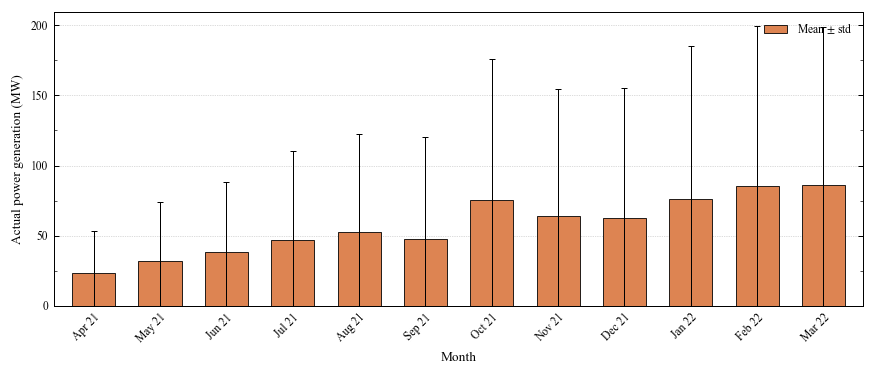

          mean     std  days
ym                          
2021-04  23.41   29.83    30
2021-05  31.74   42.48    31
2021-06  38.14   49.93    30
2021-07  46.96   63.50    31
2021-08  52.40   70.28    31
2021-09  47.78   72.71    30
2021-10  75.52  100.34    31
2021-11  64.14   90.68    30
2021-12  62.61   92.95    31
2022-01  76.42  108.73    31
2022-02  85.39  114.16    28
2022-03  86.11  112.68    31


In [ ]:
# --- Infographic 1: Monthly Average Generation Profile (IEEE Transactions style) ---
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "ytick.minor.size": 1.8,
    "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

# ---------- data ----------
_d = RAW_DF.copy()

# build a proper datetime (reuse it if the column already exists)
if "datetime" not in _d.columns:
    _d["datetime"] = pd.to_datetime(_d["Date"] + " " + _d["Time"], format="%d-%m-%Y %H:%M:%S")

# year-month key: Apr-21 and Apr-22 stay separate, and months stay in time order
_d["ym"] = _d["datetime"].dt.to_period("M")
monthly = _d.groupby("ym")["Actual"].agg(["mean", "std"])
n_days = _d.groupby("ym")["datetime"].apply(lambda s: s.dt.normalize().nunique())

# optional: drop months with fewer than N days (e.g. the single day of Apr 22)
MIN_DAYS = 1                                          # set to 7, for example, to drop partial months
keep = n_days >= MIN_DAYS
monthly, n_days = monthly[keep], n_days[keep]

labels = [p.strftime("%b %y") for p in monthly.index]
x = np.arange(len(monthly))
mean_v = monthly["mean"].values
std_v = monthly["std"].values
lower = np.minimum(std_v, mean_v)                     # clip the lower error bar at 0 (PV can't be negative)

# ---------- plot ----------
with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=(7.16, 3.0))       # IEEE double-column width (7.16 in)

    ax.bar(x, mean_v, width=0.65, color="#DD8452", edgecolor="black", linewidth=0.5,
           yerr=[lower, std_v], capsize=2.0,
           error_kw=dict(ecolor="black", elinewidth=0.6, capthick=0.6),
           label="Mean $\\pm$ std")

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right", rotation_mode="anchor")
    ax.set_xlim(-0.6, len(x) - 0.4)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_locator(MultipleLocator(50))
    ax.yaxis.set_minor_locator(MultipleLocator(25))

    ax.set_xlabel("Month")
    ax.set_ylabel("Actual power generation (MW)")
    ax.grid(True, axis="y", which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.set_axisbelow(True)
    ax.legend(loc="upper right", frameon=False)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig("info01_monthly_generation_profile.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig("Fig1_monthly_generation_profile.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()

print(monthly.assign(days=n_days).round(2))           # sanity check: about 13 rows, Apr 21 to Apr 22

In [ ]:
from scipy import stats  # only used for the Q-Q plot (Infographic 19)

# CHANGED (v4): test-target row positions are stored by prepare_data(), so timestamps are a direct lookup
# (identical for every horizon and every model - all are scored on the same test rows).
TEST_TIMESTAMPS = pd.to_datetime(RAW_DF["__timestamp"].values[DATA["test_target_pos"]])
assert len(TEST_TIMESTAMPS) == len(DATA["y_test"]), "timestamp alignment mismatch - check prepare_data windowing logic"
TEST_HOURS = TEST_TIMESTAMPS.hour + TEST_TIMESTAMPS.minute / 60.0
print(f"[{ACTIVE_HORIZON}] Test timestamps aligned: {len(TEST_TIMESTAMPS)} samples "
      f"({TEST_TIMESTAMPS.min()} to {TEST_TIMESTAMPS.max()})")

[15 min] Test timestamps aligned: 5256 samples (2022-02-05 06:00:00 to 2022-03-31 23:45:00)


## Diurnal Generation Profile - Full dataset 

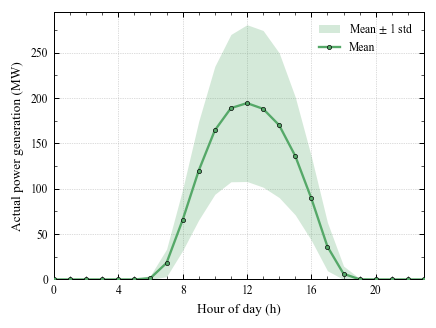

Hour  0.0   1.0   2.0   3.0   4.0   5.0   6.0   7.0   8.0    9.0   ...   14.0  \
mean   0.0   0.0   0.0   0.0   0.0   0.0   1.5  18.2  65.6  120.1  ...  170.1   
std    0.0   0.0   0.0   0.0   0.0   0.0   2.9  15.2  33.8   54.4  ...   79.7   

Hour   15.0  16.0  17.0  18.0  19.0  20.0  21.0  22.0  23.0  
mean  136.1  89.3  36.2   6.2   0.2   0.0   0.0   0.0   0.0  
std    65.0  46.2  26.6   8.6   0.9   0.0   0.0   0.0   0.0  

[2 rows x 24 columns]


In [ ]:
# --- Infographic 2: Diurnal (Hourly) Generation Profile (IEEE Transactions style) ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

FIG_SIZE = (3.5, 2.6)                  # IEEE single column (3.5 in). Use (7.16, 3.0) for double-column.
LINE_COLOR = "#55A868"

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

# ---------- data ----------
hourly = (RAW_DF.assign(Hour=RAW_DF["__timestamp"].dt.hour)
                .groupby("Hour")["Actual"].agg(["mean", "std"]))
hours = hourly.index.values
mean_v = hourly["mean"].values
std_v = hourly["std"].values
lower = np.clip(mean_v - std_v, 0, None)              # PV power can't be negative
upper = mean_v + std_v

# ---------- plot ----------
with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=FIG_SIZE)

    ax.fill_between(hours, lower, upper, color=LINE_COLOR, alpha=0.25, linewidth=0,
                    label=r"Mean $\pm$ 1 std", zorder=2)
    ax.plot(hours, mean_v, color=LINE_COLOR, linewidth=1.4, marker="o", markersize=2.5,
            markeredgecolor="black", markeredgewidth=0.4, label="Mean", zorder=4)

    ax.set_xlim(0, 23)
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(MultipleLocator(4))
    ax.xaxis.set_minor_locator(MultipleLocator(1))
    ax.yaxis.set_major_locator(MultipleLocator(50))
    ax.yaxis.set_minor_locator(MultipleLocator(25))

    ax.set_xlabel("Hour of day (h)")
    ax.set_ylabel("Actual power generation (MW)")
    ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.legend(loc="upper right", frameon=False, handlelength=1.8)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig(os.path.join(out_dir, "info02_diurnal_profile.png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, "info02_diurnal_profile.pdf"), bbox_inches="tight", pad_inches=0.02)
    plt.show()

print(hourly.round(1).T)                               # table for the text

## Feature Correlation Heatmap

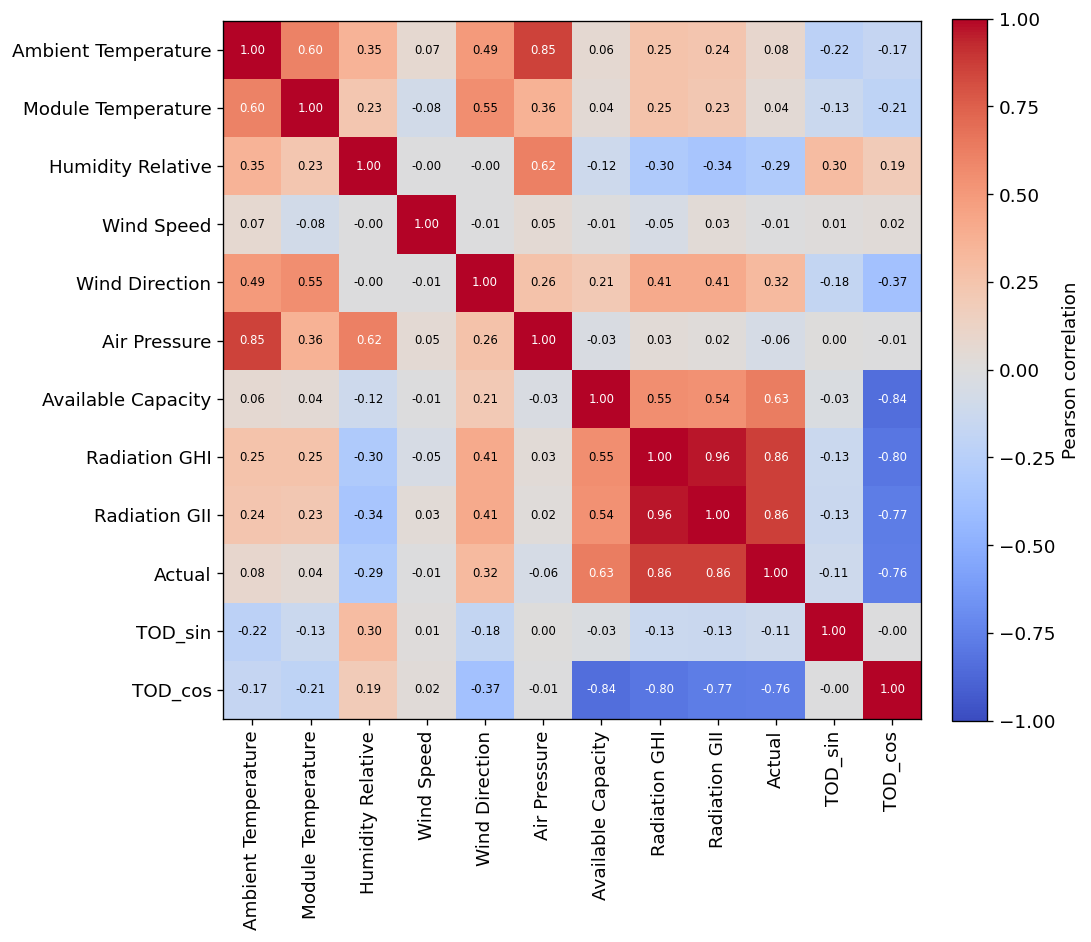

In [ ]:
# --- Infographic 3: Feature Correlation Heatmap ---
corr_cols = list(CFG.feature_cols)
corr = RAW_DF[corr_cols].corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols))); ax.set_xticklabels(corr_cols, rotation=90)
ax.set_yticks(range(len(corr_cols))); ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                 color="white" if abs(corr.values[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
fig.tight_layout()
_savefig(fig, "info03_correlation_heatmap")

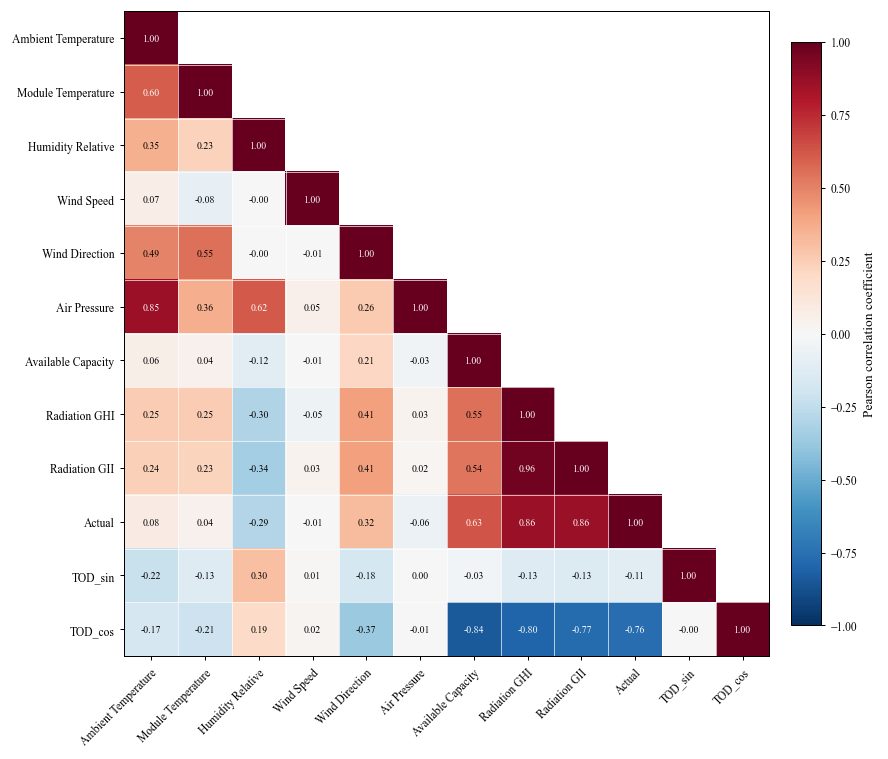

                A                    B      r
35  Radiation GII        Radiation GHI  0.964
43         Actual        Radiation GHI  0.865
44         Actual        Radiation GII  0.860
10   Air Pressure  Ambient Temperature  0.855
61        TOD_cos   Available Capacity -0.839
62        TOD_cos        Radiation GHI -0.800
63        TOD_cos        Radiation GII -0.772
64        TOD_cos               Actual -0.764
42         Actual   Available Capacity  0.628
12   Air Pressure    Humidity Relative  0.615


In [ ]:
# --- Infographic 3: Feature Correlation Heatmap
import os
import matplotlib as mpl
import matplotlib.pyplot as plt

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

LOWER_TRIANGLE_ONLY = True             # the matrix is symmetric, so show each pair once
ANNOTATE = True                        # print the correlation value in every cell
FIG_SIZE = (7.16, 6.2)                 # IEEE double-column width; use (3.5, 3.5) for a few features only
CMAP = "RdBu_r"                        # diverging, prints well in grayscale (dark = strong)

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

corr_cols = list(CFG.feature_cols)
corr = RAW_DF[corr_cols].corr()
vals = corr.values.copy()
n = len(corr_cols)

if LOWER_TRIANGLE_ONLY:
    vals = np.ma.masked_where(np.triu(np.ones_like(vals, dtype=bool), k=1), vals)

# font size of the cell numbers shrinks as the number of features grows
cell_fs = float(np.clip(70.0 / n, 4.0, 7.0))

with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    im = ax.imshow(vals, cmap=CMAP, vmin=-1, vmax=1, aspect="equal")

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(corr_cols, rotation=45, ha="right", rotation_mode="anchor")
    ax.set_yticklabels(corr_cols)
    ax.tick_params(length=2.5, width=0.6)

    # thin white grid between cells
    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.4)
    ax.tick_params(which="minor", length=0)

    if ANNOTATE:
        for i in range(n):
            for j in range(n):
                if LOWER_TRIANGLE_ONLY and j > i:
                    continue
                v = corr.values[i, j]
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=cell_fs,
                        color="white" if abs(v) > 0.6 else "black")

    for s in ax.spines.values():
        s.set_linewidth(0.6)

    cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03)
    cbar.set_label("Pearson correlation coefficient", fontsize=8)
    cbar.ax.tick_params(labelsize=7, width=0.6, length=2.5)
    cbar.outline.set_linewidth(0.6)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig(os.path.join(out_dir, "info03_correlation_heatmap.png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, "info03_correlation_heatmap.pdf"), bbox_inches="tight", pad_inches=0.02)
    plt.show()

# strongest pairs (excluding the diagonal), useful for the text
pairs = (corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).stack()
             .rename("r").reset_index().rename(columns={"level_0": "A", "level_1": "B"}))
print(pairs.reindex(pairs["r"].abs().sort_values(ascending=False).index).head(10).round(3))

## Actual Power Generation by split
### - Actual power distribution by split (all samples)
### - Actual power distribution by split (daytime only, >1MW)

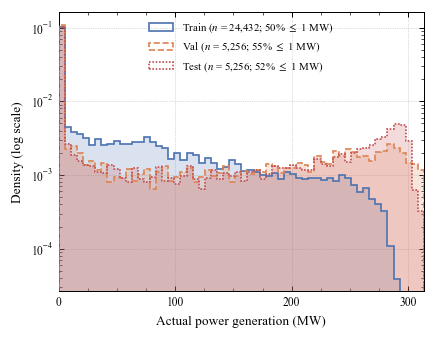

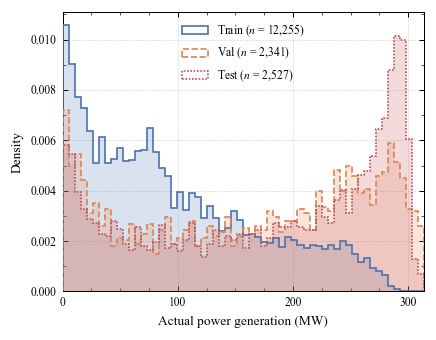

             n  night %  day mean (MW)  day median (MW)  P90 day (MW)
Train  24432.0     49.8           95.5             77.5         214.9
Val     5256.0     55.5          165.0            180.1         287.0
Test    5256.0     51.9          180.2            205.7         292.4


In [ ]:
# --- Infographic 4: Actual power distribution by split
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, AutoMinorLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "hatch.linewidth": 0.4,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

FIG_SIZE = (3.5, 2.7)                  # IEEE single column (3.5 in)
N_BINS = 60
NIGHT_MW = 1.0                         # samples at or below this are counted as night / ~0 MW

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

y_train_mw = inverse_scale(DATA["target_scaler"], DATA["y_train"]).ravel()
y_val_mw   = inverse_scale(DATA["target_scaler"], DATA["y_val"]).ravel()
y_test_mw  = inverse_scale(DATA["target_scaler"], DATA["y_test"]).ravel()

# colour, line style and hatch per split, so the three stay distinguishable in grayscale print
splits = [(y_train_mw, "Train", "#4C72B0", "-",         ""),
          (y_val_mw,   "Val",   "#DD8452", "--",        "//"),
          (y_test_mw,  "Test",  "#C44E52", (0, (1, 1)), "xx")]
bins = np.linspace(0, max(a.max() for a, *_ in splits), N_BINS + 1)   # same bins for every split

def save_both(fig, stem):
    fig.savefig(os.path.join(out_dir, stem + ".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, stem + ".pdf"), bbox_inches="tight", pad_inches=0.02)

with mpl.rc_context(IEEE_RC):

    # ================= Figure 4a: all samples, log scale =================
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    for arr, label, color, ls, hatch in splits:
        night_pct = 100 * np.mean(arr <= NIGHT_MW)
        ax.hist(arr, bins=bins, density=True, histtype="stepfilled", color=color, alpha=0.20,
                linewidth=0, zorder=2)
        ax.hist(arr, bins=bins, density=True, histtype="step", color=color, linestyle=ls,
                linewidth=1.0, zorder=3,
                label=f"{label} ($n$ = {len(arr):,}; {night_pct:.0f}% $\\leq$ {NIGHT_MW:.0f} MW)")
    ax.set_yscale("log")
    ax.set_xlim(0, bins[-1])
    ax.xaxis.set_major_locator(MultipleLocator(100))
    ax.xaxis.set_minor_locator(MultipleLocator(25))
    ax.set_xlabel("Actual power generation (MW)")
    ax.set_ylabel("Density (log scale)")
    ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.legend(loc="upper center", frameon=False, handlelength=2.2, fontsize=6.5)
    fig.tight_layout(pad=0.3)
    save_both(fig, "info04a_actual_distribution_all_samples")
    plt.show()
    plt.close(fig)

    # ================= Figure 4b: daytime only (> NIGHT_MW) =================
    fig, ax = plt.subplots(figsize=FIG_SIZE)
    for arr, label, color, ls, hatch in splits:
        day = arr[arr > NIGHT_MW]
        ax.hist(day, bins=bins, density=True, histtype="stepfilled", color=color, alpha=0.20,
                linewidth=0, zorder=2)
        ax.hist(day, bins=bins, density=True, histtype="step", color=color, linestyle=ls,
                linewidth=1.0, zorder=3, label=f"{label} ($n$ = {len(day):,})")
    ax.set_xlim(0, bins[-1])
    ax.xaxis.set_major_locator(MultipleLocator(100))
    ax.xaxis.set_minor_locator(MultipleLocator(25))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Actual power generation (MW)")
    ax.set_ylabel("Density")
    ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.legend(loc="upper center", frameon=False, handlelength=2.2)
    fig.tight_layout(pad=0.3)
    save_both(fig, "info04b_actual_distribution_daytime")
    plt.show()
    plt.close(fig)

# numeric summary for the text
summary = pd.DataFrame({
    label: {"n": len(a), "night %": 100 * np.mean(a <= NIGHT_MW),
            "day mean (MW)": a[a > NIGHT_MW].mean(), "day median (MW)": np.median(a[a > NIGHT_MW]),
            "P90 day (MW)": np.percentile(a[a > NIGHT_MW], 90)}
    for a, label, *_ in splits}).T.round(1)
print(summary)

## Weather Drivers vs Power Generation----- Scatter

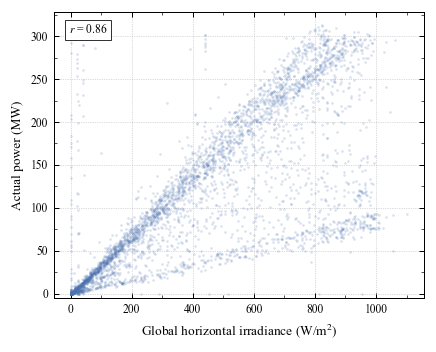

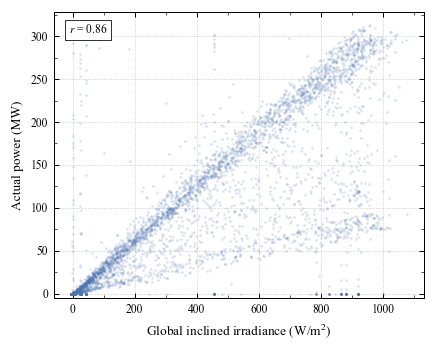

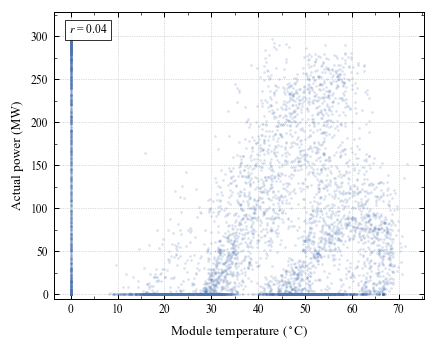

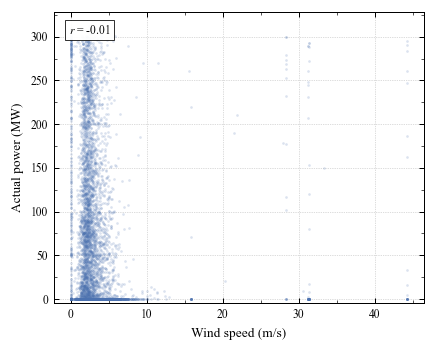

In [ ]:
# --- Infographic 5: Weather driver vs Actual power, one separate IEEE-style figure per driver ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

drivers = ["Radiation GHI", "Radiation GII", "Module Temperature", "Wind Speed"]

# axis labels with units (EDIT if your units differ; these are my assumption, the data file does not state them)
AXIS_LABELS = {
    "Radiation GHI":      r"Global horizontal irradiance (W/m$^2$)",
    "Radiation GII":      r"Global inclined irradiance (W/m$^2$)",
    "Module Temperature": r"Module temperature ($^\circ$C)",
    "Wind Speed":         "Wind speed (m/s)",
}

FIG_SIZE = (3.5, 2.8)                  # IEEE single column (3.5 in)
N_SAMPLE = 8000
DAYTIME_ONLY = False                   # True: keep only samples with Actual > 1 MW
POINT_COLOR = "#4C72B0"

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

data = RAW_DF[RAW_DF["Actual"] > 1] if DAYTIME_ONLY else RAW_DF
sample = data.sample(min(N_SAMPLE, len(data)), random_state=CFG.seed)

with mpl.rc_context(IEEE_RC):
    for col in drivers:
        r = data[col].corr(data["Actual"])                       # Pearson r over the plotted population

        fig, ax = plt.subplots(figsize=FIG_SIZE)
        ax.scatter(sample[col], sample["Actual"], s=2.5, alpha=0.2, color=POINT_COLOR,
                   linewidths=0, rasterized=True, zorder=3)      # rasterized: keeps the PDF small

        ax.set_xlabel(AXIS_LABELS.get(col, col))
        ax.set_ylabel("Actual power (MW)")
        ax.set_ylim(bottom=-5)
        ax.xaxis.set_minor_locator(AutoMinorLocator(2))
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))
        ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")

        # correlation in an in-axes box (replaces the title, which IEEE puts in the caption)
        ax.text(0.04, 0.96, f"$r$ = {r:.2f}", transform=ax.transAxes, ha="left", va="top",
                fontsize=7, bbox=dict(boxstyle="square,pad=0.3", facecolor="white",
                                      edgecolor="black", linewidth=0.5, alpha=0.95), zorder=10)

        fig.tight_layout(pad=0.3)

        # ---------- save: 600 dpi PNG + vector PDF ----------
        fname = "info05_scatter_" + col.lower().replace(" ", "_")
        fig.savefig(os.path.join(out_dir, fname + ".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
        fig.savefig(os.path.join(out_dir, fname + ".pdf"), bbox_inches="tight", pad_inches=0.02)
        plt.show()
        plt.close(fig)

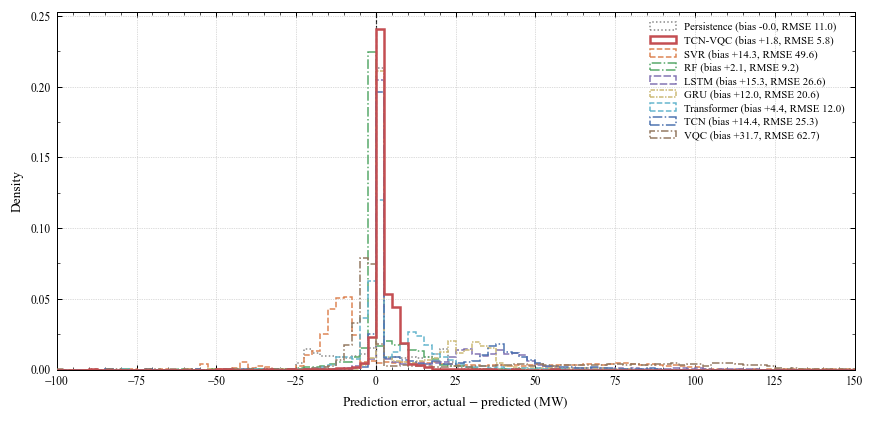

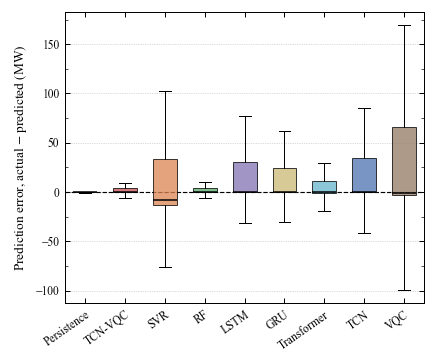

              bias    std   RMSE     P5     P95
Persistence  -0.00  11.05  11.05 -19.96   20.54
TCN-VQC       1.81   5.49   5.78  -1.14    8.30
SVR          14.29  47.46  49.56 -22.46   93.81
RF            2.11   8.95   9.20  -8.56   17.90
LSTM         15.30  21.70  26.55   0.00   49.79
GRU          11.96  16.73  20.57   0.00   38.44
Transformer   4.44  11.11  11.96  -8.71   23.57
TCN          14.44  20.72  25.26  -0.40   51.02
VQC          31.71  54.06  62.68  -9.19  121.90


In [ ]:
# --- Infographic 6: Prediction error distribution (IEEE Transactions style) ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, AutoMinorLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6.5,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

# distinct line style per model, so curves stay separable in grayscale print
LINESTYLES = {
    "Persistence": (0, (1, 1.5)), "TCN-VQC": "-", "SVR": "--", "RF": "-.", "LSTM": (0, (5, 1.5)),
    "GRU": (0, (3, 1, 1, 1)), "Transformer": "--", "TCN": "-.", "VQC": (0, (5, 1.5, 1, 1.5)),
}

CLIP_AT_ZERO = True                    # PV power can't be negative (same as the other figures)

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

def save_both(fig, stem):
    fig.savefig(os.path.join(out_dir, stem + ".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, stem + ".pdf"), bbox_inches="tight", pad_inches=0.02)

# ---------- errors (Actual - Predicted) ----------
errs = {}
for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    y_true = np.asarray(y_true, float).ravel()
    y_pred = np.asarray(y_pred, float).ravel()
    if CLIP_AT_ZERO:
        y_pred = np.clip(y_pred, 0, None)
    errs[name] = y_true - y_pred

with mpl.rc_context(IEEE_RC):

    # ================= Figure 6a: overlaid outlines, shared bins, zoomed x-range =================
    lo, hi = -100, 150
    bins = np.linspace(lo, hi, 101)                          # same bin edges for every model

    fig, ax = plt.subplots(figsize=(7.16, 3.4))               # IEEE double-column width (7.16 in)
    for name, err in errs.items():
        proposed = (name == "TCN-VQC")
        ax.hist(err, bins=bins, histtype="step", density=True,
                linewidth=1.5 if proposed else 0.9, linestyle=LINESTYLES.get(name, "-"),
                color=MODEL_COLORS[name], zorder=8 if proposed else 4,
                label=f"{name} (bias {err.mean():+.1f}, RMSE {np.sqrt((err**2).mean()):.1f})")
    ax.axvline(0, color="black", linewidth=0.7, linestyle="--", zorder=1)
    ax.set_xlim(lo, hi)
    ax.xaxis.set_major_locator(MultipleLocator(25))
    ax.xaxis.set_minor_locator(MultipleLocator(5))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.set_xlabel("Prediction error, actual $-$ predicted (MW)")
    ax.set_ylabel("Density")
    ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.legend(loc="upper right", frameon=False, handlelength=2.4, labelspacing=0.3)
    fig.tight_layout(pad=0.3)
    save_both(fig, "info06a_error_distribution_overlay")
    plt.show()
    plt.close(fig)

    # ================= Figure 6b: boxplot, one box per model =================
    names = list(errs.keys())
    fig, ax = plt.subplots(figsize=(3.5, 2.9))                # IEEE single column (3.5 in)
    bp = ax.boxplot([errs[n] for n in names], labels=names, patch_artist=True, showfliers=False,
                    widths=0.6, medianprops=dict(color="black", linewidth=0.9),
                    whiskerprops=dict(linewidth=0.6), capprops=dict(linewidth=0.6),
                    boxprops=dict(linewidth=0.6))
    for patch, n in zip(bp["boxes"], names):
        patch.set_facecolor(MODEL_COLORS[n]); patch.set_alpha(0.75)
    ax.axhline(0, color="black", linewidth=0.7, linestyle="--", zorder=1)
    ax.set_ylabel("Prediction error, actual $-$ predicted (MW)")
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.grid(True, axis="y", which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.set_axisbelow(True)
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right", rotation_mode="anchor")
    fig.tight_layout(pad=0.3)
    save_both(fig, "info06b_error_boxplot")
    plt.show()
    plt.close(fig)

# numeric summary for the paper
summary = pd.DataFrame({n: {"bias": e.mean(), "std": e.std(), "RMSE": np.sqrt((e**2).mean()),
                            "P5": np.percentile(e, 5), "P95": np.percentile(e, 95)}
                        for n, e in errs.items()}).T.round(2)
print(summary)

## Empirical CDF of Absolute percentage error 

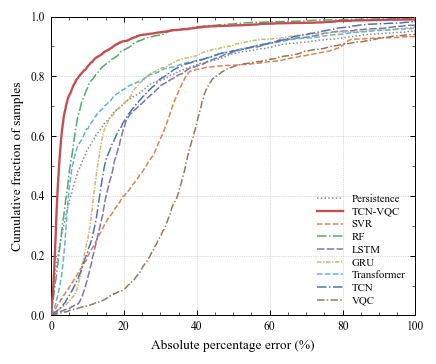

                  n  median APE %  within 5 %  within 10 %  within 20 %  \
Persistence  2527.0           8.1        37.8         55.2         70.8   
TCN-VQC      2527.0           2.2        73.6         83.1         91.7   
SVR          2527.0          26.1         9.5         19.5         39.9   
RF           2527.0           5.3        47.9         76.1         88.7   
LSTM         2527.0          17.2         2.3         12.3         62.7   
GRU          2527.0          12.8         4.6         25.0         71.0   
Transformer  2527.0           5.8        42.8         62.4         75.6   
TCN          2527.0          14.7         6.6         21.0         64.8   
VQC          2527.0          36.9         1.6          3.2          8.8   

             P90 APE %  
Persistence       61.2  
TCN-VQC           17.2  
SVR               79.6  
RF                21.8  
LSTM              57.3  
GRU               48.6  
Transformer       55.6  
TCN               55.7  
VQC               76.9  

In [ ]:
# --- Infographic 8: Empirical CDF of Absolute Percentage Error
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6.5,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

# distinct line style per model, so curves stay separable in grayscale print
LINESTYLES = {
    "Persistence": (0, (1, 1.5)), "TCN-VQC": "-", "SVR": "--", "RF": "-.", "LSTM": (0, (5, 1.5)),
    "GRU": (0, (3, 1, 1, 1)), "Transformer": "--", "TCN": "-.", "VQC": (0, (5, 1.5, 1, 1.5)),
}

CLIP_AT_ZERO = True                    # PV power can't be negative (same as the other figures)
X_MAX = 100                            # truncate the x-axis at this APE (%)
FIG_SIZE = (3.5, 2.9)                  # IEEE single column (3.5 in). Use (7.16, 3.2) for double-column.

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

ecdf, rows = {}, {}
for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    y_true = np.asarray(y_true, float).ravel()
    y_pred = np.asarray(y_pred, float).ravel()
    if CLIP_AT_ZERO:
        y_pred = np.clip(y_pred, 0, None)
    mask = y_true > CFG.mape_eps_mw                           # same threshold as your MAPE metric
    ape = np.abs((y_true[mask] - y_pred[mask]) / y_true[mask]) * 100
    s = np.sort(ape)
    ecdf[name] = (s, np.arange(1, len(s) + 1) / len(s))
    rows[name] = {"n": len(s), "median APE %": np.median(s),
                  "within 5 %": 100 * np.mean(s <= 5), "within 10 %": 100 * np.mean(s <= 10),
                  "within 20 %": 100 * np.mean(s <= 20), "P90 APE %": np.percentile(s, 90)}

with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=FIG_SIZE)

    for name, (s, c) in ecdf.items():
        proposed = (name == "TCN-VQC")
        ax.plot(s, c, color=MODEL_COLORS[name], linestyle=LINESTYLES.get(name, "-"),
                linewidth=1.4 if proposed else 0.9, label=name, zorder=8 if proposed else 4)

    ax.set_xlim(0, X_MAX)
    ax.set_ylim(0, 1.0)
    ax.xaxis.set_major_locator(MultipleLocator(20))
    ax.xaxis.set_minor_locator(MultipleLocator(5))
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    ax.set_xlabel("Absolute percentage error (%)")
    ax.set_ylabel("Cumulative fraction of samples")
    ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.legend(loc="lower right", frameon=False, handlelength=2.4, labelspacing=0.25)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig(os.path.join(out_dir, "info08_ape_ecdf.png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, "info08_ape_ecdf.pdf"), bbox_inches="tight", pad_inches=0.02)
    plt.show()

print(pd.DataFrame(rows).T.round(1))                          # table for the text

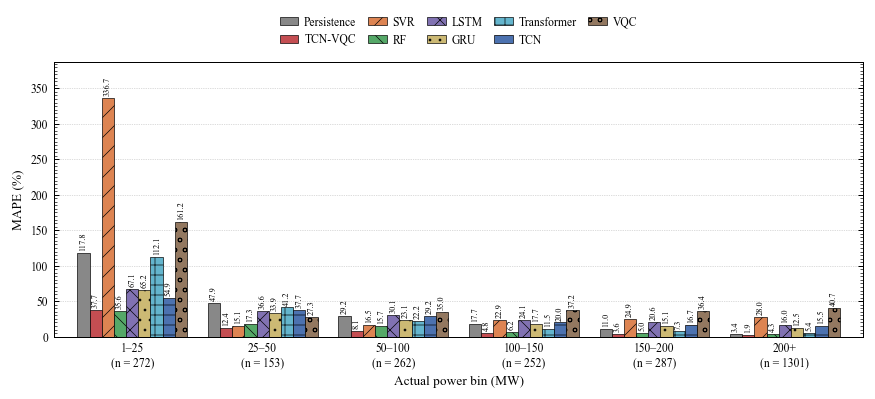

         Persistence  TCN-VQC     SVR     RF   LSTM    GRU  Transformer  \
1–25          117.77    37.74  336.74  35.58  67.13  65.24       112.12   
25–50          47.93    12.36   15.12  17.30  36.61  33.94        41.18   
50–100         29.18     8.15   16.54  15.66  30.08  23.09        22.17   
100–150        17.66     4.79   22.93   6.16  24.12  17.67        11.47   
150–200        11.05     3.59   24.86   5.00  20.62  15.10         7.31   
200+            3.38     1.87   27.96   4.33  15.96  12.52         5.35   

           TCN     VQC     n  
1–25     54.92  161.17   272  
25–50    37.68   27.33   153  
50–100   29.20   34.95   262  
100–150  20.03   37.21   252  
150–200  16.71   36.39   287  
200+     15.52   40.69  1301  


In [ ]:
# --- MAPE by power-output bin: IEEE Transactions style ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "ytick.minor.size": 1.8,
    "ytick.right": True,
    "hatch.linewidth": 0.4,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

# hatch per model, so bars stay distinguishable in grayscale print
HATCHES = {
    "Persistence": "", "TCN-VQC": "", "SVR": "//", "RF": "\\\\", "LSTM": "xx",
    "GRU": "..", "Transformer": "++", "TCN": "--", "VQC": "oo",
}

CLIP_AT_ZERO = True                    # PV power can't be negative (same as the other figures)
SHOW_VALUES = True                     # print the MAPE value above each bar
FIG_SIZE = (7.16, 3.2)                 # IEEE double-column width (7.16 in)

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

# ---------- bins ----------
cap = max(np.max(PREDICTIONS[n][0]) for n in RESULTS) + 1
bins = [1, 25, 50, 100, 150, 200, cap]
bin_labels = ["1–25", "25–50", "50–100", "100–150", "150–200", "200+"]

# ---------- MAPE per bin and model ----------
mape = {}
counts = None
for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    y_true = np.asarray(y_true, float).ravel()
    y_pred = np.asarray(y_pred, float).ravel()
    if CLIP_AT_ZERO:
        y_pred = np.clip(y_pred, 0, None)
    vals, cnt = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (y_true >= lo) & (y_true < hi)
        cnt.append(int(m.sum()))
        vals.append(np.mean(np.abs((y_true[m] - y_pred[m]) / y_true[m])) * 100 if m.any() else np.nan)
    mape[name] = np.array(vals)
    counts = cnt                                              # same actuals for every model

x = np.arange(len(bin_labels))
n_models = len(RESULTS)
group_w = 0.84
width = group_w / n_models

with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=FIG_SIZE)

    ymax = 0.0
    for i, name in enumerate(RESULTS.keys()):
        v = mape[name]
        ymax = max(ymax, np.nanmax(v))
        xs = x + (i - (n_models - 1) / 2) * width            # group centred on the tick
        ax.bar(xs, v, width=width, color=MODEL_COLORS[name], edgecolor="black",
               linewidth=0.4, hatch=HATCHES.get(name, ""), label=name, zorder=3)
        if SHOW_VALUES:
            for xi, vi in zip(xs, v):
                if np.isfinite(vi):
                    ax.annotate(f"{vi:.1f}", (xi, vi), xytext=(0, 1.5), textcoords="offset points",
                                ha="center", va="bottom", fontsize=5, rotation=90)

    ax.set_xticks(x)
    ax.set_xticklabels([f"{l}\n(n = {c})" for l, c in zip(bin_labels, counts)])   # sample count per bin
    ax.set_xlim(-0.6, len(x) - 0.4)
    ax.set_ylim(0, ymax * 1.15)
    ax.yaxis.set_minor_locator(MultipleLocator(5))
    ax.set_xlabel("Actual power bin (MW)")
    ax.set_ylabel("MAPE (%)")
    ax.grid(True, axis="y", which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.set_axisbelow(True)

    # legend above the axes, no frame, so it covers no bar
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=5, frameon=False,
              handlelength=1.6, columnspacing=1.0, handletextpad=0.5)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig(os.path.join(out_dir, "mape_by_power_bin.png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, "mape_by_power_bin.pdf"), bbox_inches="tight", pad_inches=0.02)
    plt.show()

print(pd.DataFrame(mape, index=bin_labels).round(2).assign(n=counts))   # table for the paper

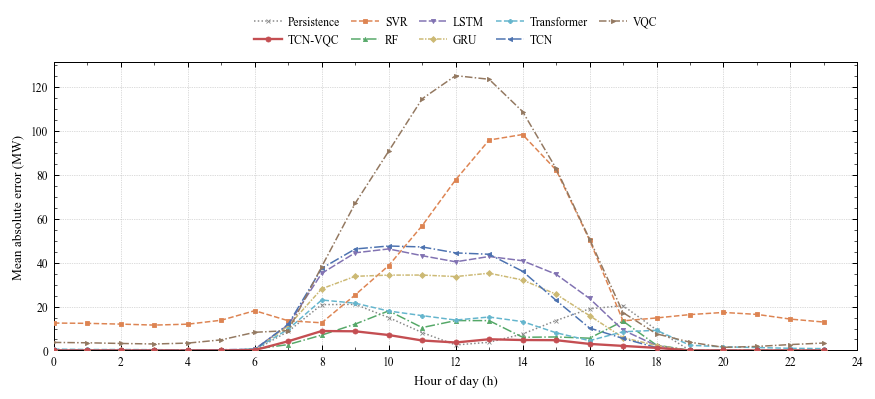

In [ ]:
# --- Infographic 10: Mean Absolute Error by Hour of Day 
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,          # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

# distinct line style + marker per model, so curves stay separable in grayscale print
LINESTYLES = {
    "Persistence": (0, (1, 1.5)),
    "TCN-VQC":     "-",
    "SVR":         "--",
    "RF":          "-.",
    "LSTM":        (0, (5, 1.5)),
    "GRU":         (0, (3, 1, 1, 1)),
    "Transformer": "--",
    "TCN":         "-.",
    "VQC":         (0, (5, 1.5, 1, 1.5)),
}
MARKERS = {
    "Persistence": "x", "TCN-VQC": "o", "SVR": "s", "RF": "^", "LSTM": "v",
    "GRU": "D", "Transformer": "P", "TCN": "<", "VQC": ">",
}

# ---------- data ----------
hour_bins = np.arange(0, 25, 1)
hours_axis = hour_bins[:-1]                           # 0 ... 23
hours_test = np.asarray(TEST_HOURS, float).ravel()

mae_by_hour = {}
for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    y_true = np.asarray(y_true, float).ravel()
    y_pred = np.clip(np.asarray(y_pred, float).ravel(), 0, None)      # PV >= 0 (keeps metrics consistent with other figures)
    df_h = pd.DataFrame({"hour": hours_test, "abs_err": np.abs(y_true - y_pred)})
    grouped = df_h.groupby(pd.cut(df_h["hour"], hour_bins, right=False), observed=False)["abs_err"].mean()
    mae_by_hour[name] = grouped.values                                # always 24 values (NaN if an hour is empty)

# ---------- plot ----------
with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=(7.16, 3.2))       # IEEE double-column width (7.16 in)

    for name in RESULTS.keys():
        proposed = (name == "TCN-VQC")
        ax.plot(hours_axis, mae_by_hour[name],
                color=MODEL_COLORS[name], linestyle=LINESTYLES.get(name, "-"),
                marker=MARKERS.get(name, "o"), markersize=3.0 if proposed else 2.5,
                linewidth=1.4 if proposed else 0.9,
                markeredgewidth=0.5, label=name,
                zorder=9 if proposed else 5)

    ax.set_xlim(0, 23)
    ax.set_xticks(range(0, 25, 2))
    ax.xaxis.set_minor_locator(MultipleLocator(1))
    ax.set_ylim(bottom=0)
    ax.yaxis.set_minor_locator(MultipleLocator(5))

    ax.set_xlabel("Hour of day (h)")
    ax.set_ylabel("Mean absolute error (MW)")
    ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")

    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=5,
              frameon=False, handlelength=2.4, columnspacing=1.0, handletextpad=0.5)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig("info10_error_by_hour.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig("info10_error_by_hour.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()

##  Single-Day Zoom (highest-generation test day)   --- peak day

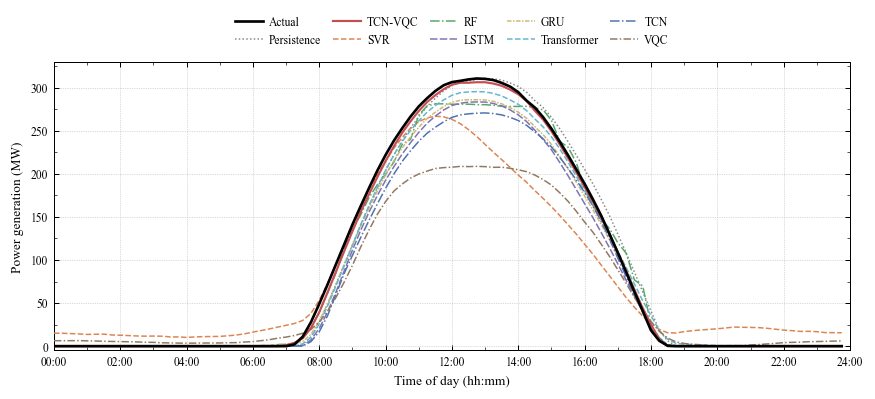

Day: 2022-02-12 | Actual peak: 310.8 MW
              RMSE  Peak pred
Persistence  10.7      310.8
TCN-VQC       3.4      306.4
SVR          38.4      267.0
RF           11.4      281.3
LSTM         16.9      283.5
GRU          13.4      286.1
Transformer  10.5      295.5
TCN          20.6      270.8
VQC          44.1      208.8


In [ ]:
# --- Infographic 11: Single-Day Zoom , highest generation day
import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ---------- data (unchanged logic) ----------
ts = pd.to_datetime(pd.Series(TEST_TIMESTAMPS)).reset_index(drop=True)
y_true_all = np.asarray(PREDICTIONS["TCN-VQC"][0], float).ravel()   # actuals (same for all models)

dates = ts.dt.date
peak_day = pd.Series(y_true_all).groupby(dates).max().idxmax()
mask = (dates == peak_day).values

times_day = ts[mask]
y_true_day = y_true_all[mask]
day0 = pd.Timestamp(peak_day)                                        # 00:00 of the chosen day

# ---------- IEEE style ----------
IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,                           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

# distinct line styles so curves remain separable in grayscale print
LINESTYLES = {
    "Persistence": (0, (1, 1.5)),      # dotted
    "TCN-VQC":     "-",                # proposed model: solid, thicker
    "SVR":         "--",
    "RF":          "-.",
    "LSTM":        (0, (5, 1.5)),
    "GRU":         (0, (3, 1, 1, 1)),
    "Transformer": "--",
    "TCN":         "-.",
    "VQC":         (0, (5, 1.5, 1, 1.5)),
}

with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=(7.16, 3.2))                      # IEEE double-column width (7.16 in)

    # Actual first (black, on top via zorder) so it is first in the legend
    ax.plot(times_day, y_true_day, color="black", linewidth=1.6, label="Actual", zorder=10)

    for name in RESULTS.keys():
        y_pred_day = np.clip(np.asarray(PREDICTIONS[name][1], float).ravel()[mask], 0, None)  # PV >= 0
        lw = 1.3 if name == "TCN-VQC" else 0.9
        ax.plot(times_day, y_pred_day,
                color=MODEL_COLORS[name], linestyle=LINESTYLES.get(name, "-"),
                linewidth=lw, label=name,
                zorder=9 if name == "TCN-VQC" else 5)

    # axes: full 00:00 -> 24:00, so the last tick reads 24:00
    ax.set_xlim(day0, day0 + pd.Timedelta(hours=24))
    ticks = [day0 + pd.Timedelta(hours=h) for h in range(0, 25, 2)]
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 2)])
    ax.xaxis.set_minor_locator(mdates.HourLocator(interval=1))

    ax.set_ylim(-5, 330)
    ax.yaxis.set_major_locator(MultipleLocator(50))
    ax.yaxis.set_minor_locator(MultipleLocator(25))

    ax.set_xlabel("Time of day (hh:mm)")
    ax.set_ylabel("Power generation (MW)")
    ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")

    # legend above the axes in two rows, so it does not cover any curve
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=5,
              frameon=False, handlelength=2.4, columnspacing=1.0, handletextpad=0.5)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig("Fig11_single_day_zoom.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig("Fig11_single_day_zoom_Highest_Generation_test_Day.pdf", bbox_inches="tight", pad_inches=0.02)
    plt.show()

# per-model error for this day (for the caption / text)
day_err = pd.DataFrame({
    n: {"RMSE": np.sqrt(np.mean((y_true_day - np.clip(np.asarray(PREDICTIONS[n][1], float).ravel()[mask], 0, None))**2)),
        "Peak pred": np.clip(np.asarray(PREDICTIONS[n][1], float).ravel()[mask], 0, None).max()}
    for n in RESULTS.keys()}).T.round(1)
print(f"Day: {peak_day} | Actual peak: {y_true_day.max():.1f} MW\n", day_err)

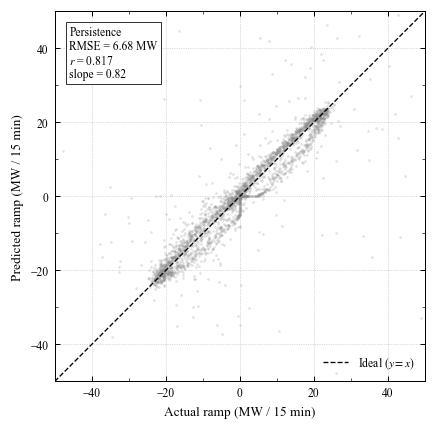

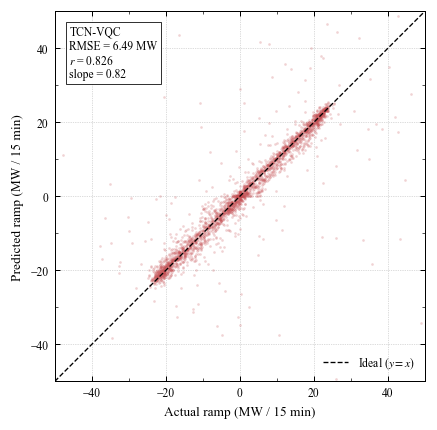

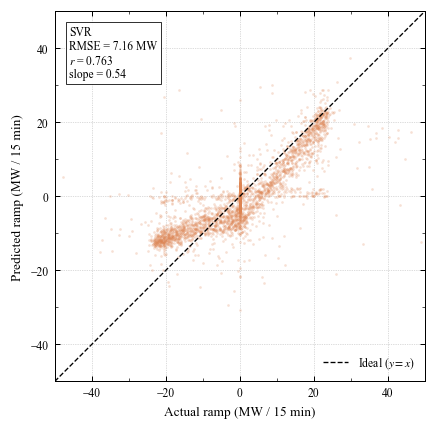

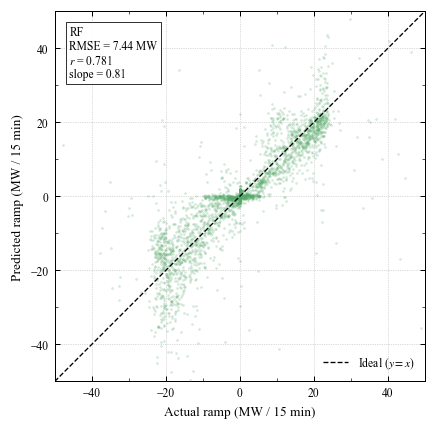

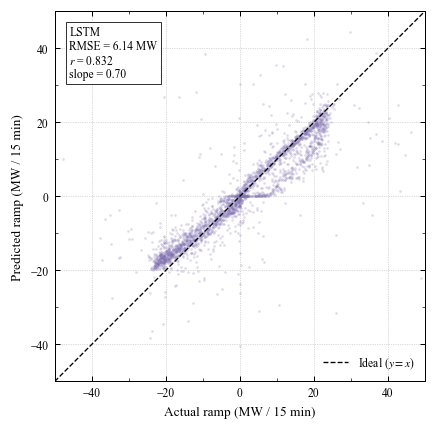

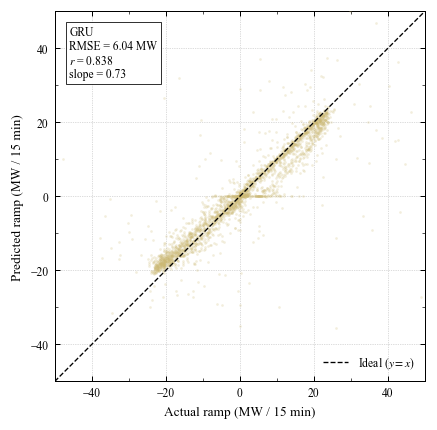

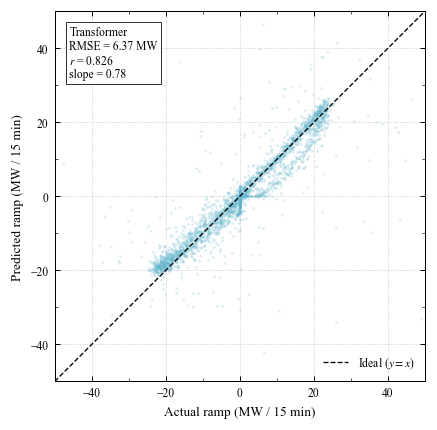

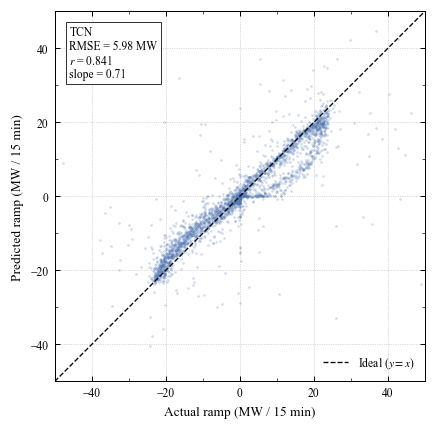

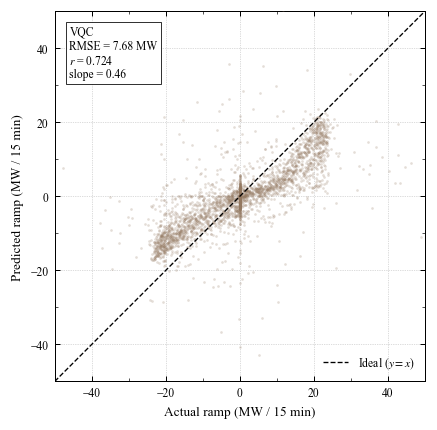

             ramp RMSE (MW/step)  ramp corr  slope
Persistence                6.683      0.817  0.817
TCN-VQC                    6.493      0.826  0.818
SVR                        7.164      0.763  0.541
RF                         7.436      0.781  0.808
LSTM                       6.137      0.832  0.701
GRU                        6.039      0.838  0.735
Transformer                6.366      0.826  0.779
TCN                        5.981      0.841  0.710
VQC                        7.679      0.724  0.463


In [ ]:
# --- Infographic 12: Ramp-rate accuracy, one separate IEEE-style figure per model ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

FIG_SIZE = (3.5, 3.5)                  # IEEE single column (3.5 in); square, so the 1:1 line is at 45 degrees
CLIP_AT_ZERO = True                    # PV power can't be negative (same as the other figures)
step_min = CFG.time_step_minutes

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

# ---------- ramps for every model ----------
ramps, stats_rows = {}, {}
for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    y_true = np.asarray(y_true, float).ravel()
    y_pred = np.asarray(y_pred, float).ravel()
    if CLIP_AT_ZERO:
        y_pred = np.clip(y_pred, 0, None)
    rt, rp = np.diff(y_true), np.diff(y_pred)             # MW per step
    ramps[name] = (rt, rp)
    stats_rows[name] = {
        "ramp RMSE (MW/step)": np.sqrt(np.mean((rt - rp) ** 2)),
        "ramp corr": np.corrcoef(rt, rp)[0, 1],
        "slope": np.polyfit(rt, rp, 1)[0],                # < 1: the model smooths ramps
    }

# the same square range for every model, so the figures are comparable
lim = np.ceil(max(np.percentile(np.abs(np.concatenate([r[0] for r in ramps.values()])), 99.9),
                  np.percentile(np.abs(np.concatenate([r[1] for r in ramps.values()])), 99.9)) / 5) * 5
LIM = (-lim, lim)

with mpl.rc_context(IEEE_RC):
    for name, (rt, rp) in ramps.items():
        s = stats_rows[name]

        fig, ax = plt.subplots(figsize=FIG_SIZE)
        ax.scatter(rt, rp, s=2.5, alpha=0.25, color=MODEL_COLORS[name],
                   linewidths=0, rasterized=True, zorder=3)          # rasterized: keeps the PDF small
        ax.plot(LIM, LIM, color="black", linestyle="--", linewidth=0.8, zorder=4, label="Ideal ($y = x$)")

        ax.set_xlim(LIM)
        ax.set_ylim(LIM)
        ax.set_aspect("equal", adjustable="box")
        ax.xaxis.set_minor_locator(AutoMinorLocator(2))
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))
        ax.set_xlabel(f"Actual ramp (MW / {step_min} min)")
        ax.set_ylabel(f"Predicted ramp (MW / {step_min} min)")
        ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")

        # model name and ramp statistics in an in-axes box (replaces the title)
        ax.text(0.04, 0.96,
                f"{name}\nRMSE = {s['ramp RMSE (MW/step)']:.2f} MW\n$r$ = {s['ramp corr']:.3f}\nslope = {s['slope']:.2f}",
                transform=ax.transAxes, ha="left", va="top", fontsize=7,
                bbox=dict(boxstyle="square,pad=0.3", facecolor="white", edgecolor="black",
                          linewidth=0.5, alpha=0.95), zorder=10)
        ax.legend(loc="lower right", frameon=False, handlelength=2.2)

        fig.tight_layout(pad=0.3)

        # ---------- save: 600 dpi PNG + vector PDF ----------
        fname = "info12_ramp_scatter_" + name.replace(" ", "_")
        fig.savefig(os.path.join(out_dir, fname + ".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
        fig.savefig(os.path.join(out_dir, fname + ".pdf"), bbox_inches="tight", pad_inches=0.02)
        plt.show()
        plt.close(fig)

print(pd.DataFrame(stats_rows).T.round(3))                    # table for the paper

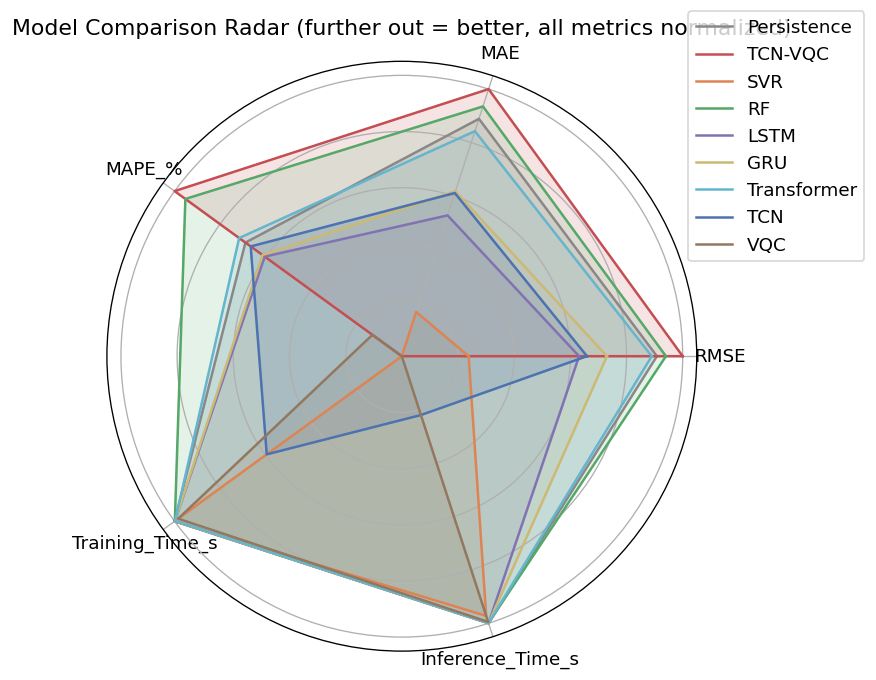

In [ ]:
# --- Infographic 13: Radar Chart — Normalized Metric Comparison ---
radar_metrics = ["RMSE", "MAE", "MAPE_%", "Training_Time_s", "Inference_Time_s"]
# lower is better for all of these -> invert so "further out" always means "better" on the radar
norm_df = METRICS_DF.set_index("Model")[radar_metrics].copy()
norm_scores = 1 - (norm_df - norm_df.min()) / (norm_df.max() - norm_df.min() + 1e-9)
angles = np.linspace(0, 2 * np.pi, len(radar_metrics), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": "polar"})
for name in RESULTS.keys():
    values = norm_scores.loc[name].tolist()
    values += values[:1]
    ax.plot(angles, values, label=name, color=MODEL_COLORS[name])
    ax.fill(angles, values, color=MODEL_COLORS[name], alpha=0.15)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_metrics)
ax.set_yticklabels([])
ax.set_title("Model Comparison Radar (further out = better, all metrics normalized)")
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
fig.tight_layout()
_savefig(fig, "info13_radar_chart")


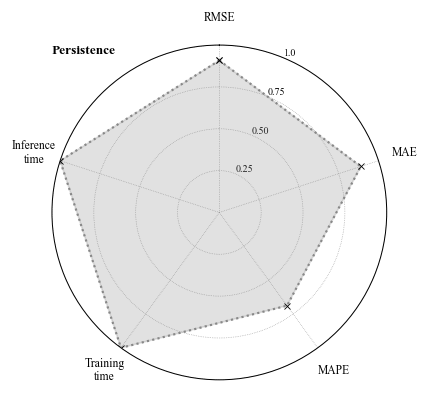

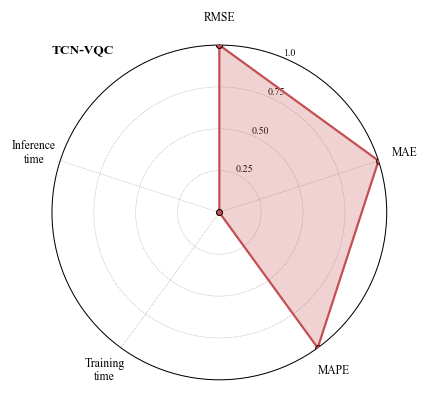

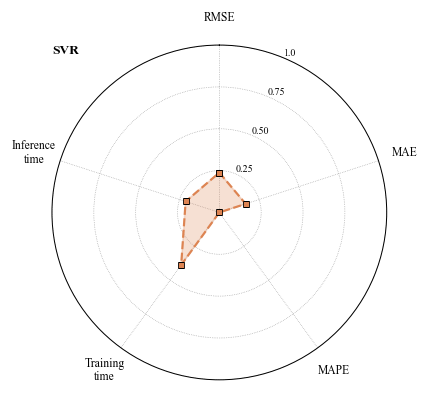

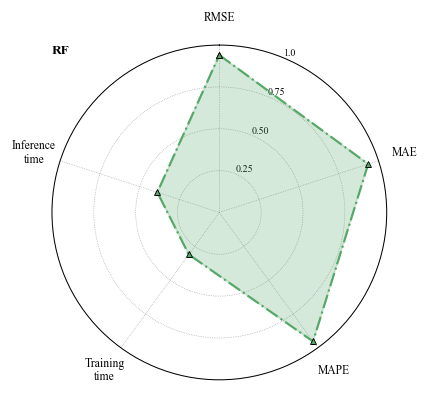

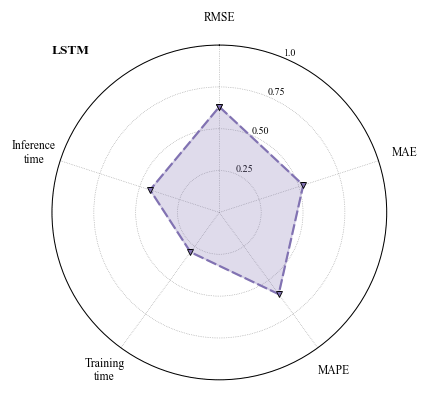

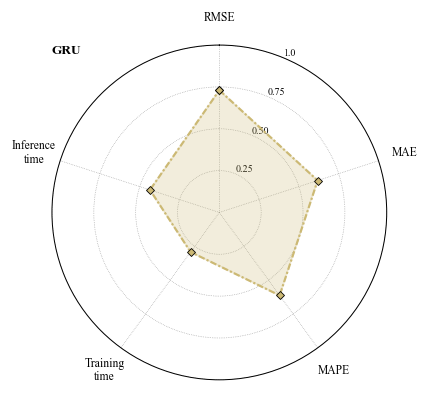

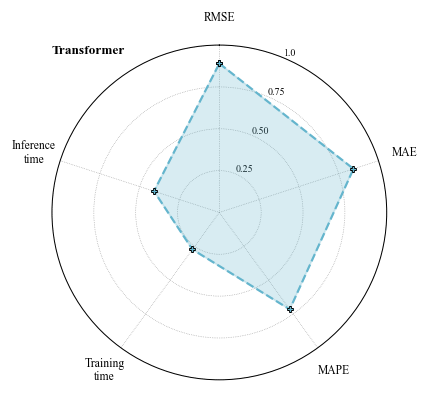

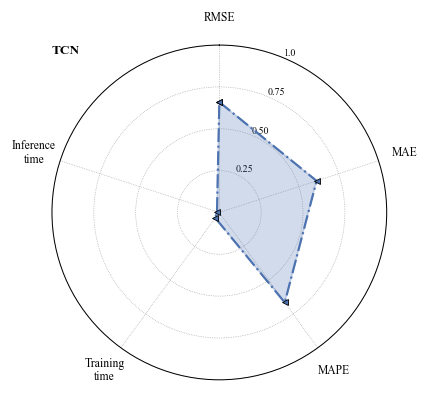

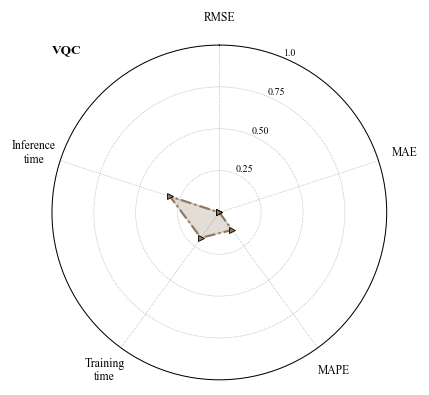

             RMSE   MAE  MAPE_%  Training_Time_s  Inference_Time_s
Model                                                             
Persistence  0.91  0.89    0.69             1.00              1.00
TCN-VQC      1.00  1.00    1.00             0.00              0.00
SVR          0.24  0.17    0.00             0.39              0.21
RF           0.94  0.94    0.95             0.31              0.39
LSTM         0.63  0.53    0.60             0.29              0.44
GRU          0.73  0.62    0.61             0.29              0.44
Transformer  0.89  0.84    0.72             0.27              0.41
TCN          0.66  0.61    0.67             0.04              0.01
VQC          0.00  0.00    0.13             0.19              0.31


In [ ]:
# --- Radar charts: one separate IEEE-style figure per model ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 6,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

radar_metrics = ["RMSE", "MAE", "MAPE_%", "Training_Time_s", "Inference_Time_s"]
radar_labels  = ["RMSE", "MAE", "MAPE", "Training\ntime", "Inference\ntime"]
LOG_TIMES = True                       # normalise the two time axes on a log scale (they span orders of magnitude)
FIG_SIZE = (3.5, 3.5)                  # IEEE single column (3.5 in)

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

# ---------- normalised scores: 1 = best model on that metric, 0 = worst (all metrics: lower is better) ----------
raw = METRICS_DF.set_index("Model")[radar_metrics].astype(float).copy()
tmp = raw.copy()
if LOG_TIMES:
    for c in ("Training_Time_s", "Inference_Time_s"):
        tmp[c] = np.log10(tmp[c].clip(lower=1e-6))
scores = 1 - (tmp - tmp.min()) / (tmp.max() - tmp.min() + 1e-9)
if scores.isna().any().any():
    print("Warning: NaN values in METRICS_DF; they are plotted as 0.")
scores = scores.fillna(0.0)

angles = np.linspace(0, 2 * np.pi, len(radar_metrics), endpoint=False)
angles_closed = np.concatenate([angles, angles[:1]])

LINESTYLES = {
    "Persistence": (0, (1, 1.5)), "TCN-VQC": "-", "SVR": "--", "RF": "-.", "LSTM": (0, (5, 1.5)),
    "GRU": (0, (3, 1, 1, 1)), "Transformer": "--", "TCN": "-.", "VQC": (0, (5, 1.5, 1, 1.5)),
}
MARKERS = {
    "Persistence": "x", "TCN-VQC": "o", "SVR": "s", "RF": "^", "LSTM": "v",
    "GRU": "D", "Transformer": "P", "TCN": "<", "VQC": ">",
}

with mpl.rc_context(IEEE_RC):
    for name in RESULTS.keys():
        vals = scores.loc[name].values
        vals_closed = np.concatenate([vals, vals[:1]])

        fig, ax = plt.subplots(figsize=FIG_SIZE, subplot_kw={"projection": "polar"})
        ax.set_theta_offset(np.pi / 2)                       # first axis at the top
        ax.set_theta_direction(-1)                           # clockwise

        ax.plot(angles_closed, vals_closed, color=MODEL_COLORS[name],
                linestyle=LINESTYLES.get(name, "-"), linewidth=1.3,
                marker=MARKERS.get(name, "o"), markersize=3.5, markeredgewidth=0.5,
                markeredgecolor="black", zorder=5)
        ax.fill(angles_closed, vals_closed, color=MODEL_COLORS[name], alpha=0.25, zorder=4)

        ax.set_ylim(0, 1)
        ax.set_rgrids([0.25, 0.5, 0.75, 1.0], labels=["0.25", "0.50", "0.75", "1.0"], angle=22.5)
        ax.set_xticks(angles)
        ax.set_xticklabels(radar_labels)
        ax.tick_params(axis="x", pad=6)
        ax.grid(True, linestyle=":", linewidth=0.4, color="0.6")
        ax.spines["polar"].set_linewidth(0.6)

        # model name in the corner (replaces the title, which IEEE puts in the caption)
        ax.text(0.0, 1.0, name, transform=ax.transAxes, ha="left", va="top", fontsize=8, fontweight="bold")

        fig.tight_layout(pad=0.6)

        # ---------- save: 600 dpi PNG + vector PDF ----------
        fname = "radar_" + name.replace(" ", "_")
        fig.savefig(os.path.join(out_dir, fname + ".png"), dpi=600, bbox_inches="tight", pad_inches=0.05)
        fig.savefig(os.path.join(out_dir, fname + ".pdf"), bbox_inches="tight", pad_inches=0.05)
        plt.show()
        plt.close(fig)

print(scores.round(2))                                       # the plotted scores, for the paper

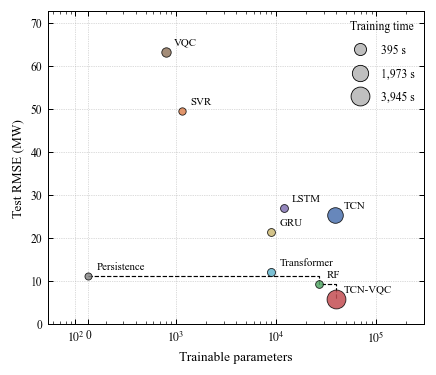

In [ ]:
# --- Efficiency frontier: parameters vs RMSE, bubble = training time (IEEE Transactions style) ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

FIG_SIZE = (3.5, 3.0)                  # IEEE single column (3.5 in). Use (7.16, 3.4) for double-column.
SHOW_FRONTIER = True                   # draw the Pareto frontier (no other model is better in BOTH parameters and RMSE)

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

df = METRICS_DF[["Model", "Num_Params", "RMSE", "Training_Time_s"]].copy()
df["Num_Params"] = df["Num_Params"].fillna(0)
df["Training_Time_s"] = df["Training_Time_s"].fillna(0)

# models with no trainable parameters (e.g. Persistence, SVR, RF) cannot sit on a log axis:
# place them in a separate slot at the left and label that slot "0"
pos = df.loc[df["Num_Params"] > 0, "Num_Params"]
x_zero = pos.min() / 6.0
df["x"] = np.where(df["Num_Params"] > 0, df["Num_Params"], x_zero)

# bubble area grows with training time (square-root scaling keeps the range readable)
def bubble(t):
    return 18 + 110 * np.sqrt(np.clip(t, 0, None) / max(df["Training_Time_s"].max(), 1e-9))

# per-model label offsets (points); adjust if two labels overlap
OFFSETS = {m: (5, 4) for m in df["Model"]}
# OFFSETS["RF"] = (5, -9)        # example: move one label down

with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=FIG_SIZE)

    # Pareto frontier: sort by parameters, keep models whose RMSE beats every cheaper model
    if SHOW_FRONTIER:
        d = df.sort_values(["Num_Params", "RMSE"])
        best, front = np.inf, []
        for _, r in d.iterrows():
            if r["RMSE"] < best:
                front.append((r["x"], r["RMSE"]))
                best = r["RMSE"]
        fx, fy = zip(*front)
        ax.step(fx, fy, where="post", color="black", linestyle="--", linewidth=0.7, zorder=2)

    for _, r in df.iterrows():
        ax.scatter(r["x"], r["RMSE"], s=bubble(r["Training_Time_s"]),
                   color=MODEL_COLORS[r["Model"]], alpha=0.85,
                   edgecolor="black", linewidth=0.5, zorder=4)
        ax.annotate(r["Model"], (r["x"], r["RMSE"]), textcoords="offset points",
                    xytext=OFFSETS.get(r["Model"], (5, 4)), fontsize=6.5, zorder=5)

    ax.set_xscale("log")
    # custom ticks: the "0" slot plus decades of parameters
    lo, hi = int(np.floor(np.log10(pos.min()))), int(np.ceil(np.log10(pos.max())))
    ticks = [x_zero] + [10 ** k for k in range(lo, hi + 1)]
    ax.set_xticks(ticks)
    ax.set_xticklabels(["0"] + [rf"$10^{{{k}}}$" for k in range(lo, hi + 1)])
    ax.set_xlim(x_zero / 2.5, 10 ** hi * 3)
    ax.set_ylim(0, df["RMSE"].max() * 1.15)

    ax.set_xlabel("Trainable parameters")
    ax.set_ylabel("Test RMSE (MW)")
    ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")

    # legend: bubble size = training time
    t_ref = [df["Training_Time_s"].max() * f for f in (0.1, 0.5, 1.0)]
    handles = [Line2D([0], [0], marker="o", color="none", markerfacecolor="0.75",
                      markeredgecolor="black", markeredgewidth=0.5,
                      markersize=np.sqrt(bubble(t)), label=f"{t:,.0f} s") for t in t_ref]
    ax.legend(handles=handles, title="Training time", loc="upper right", frameon=False,
              labelspacing=1.0, borderpad=0.3, title_fontsize=7)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig(os.path.join(out_dir, "efficiency_frontier.png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, "efficiency_frontier.pdf"), bbox_inches="tight", pad_inches=0.02)
    plt.show()

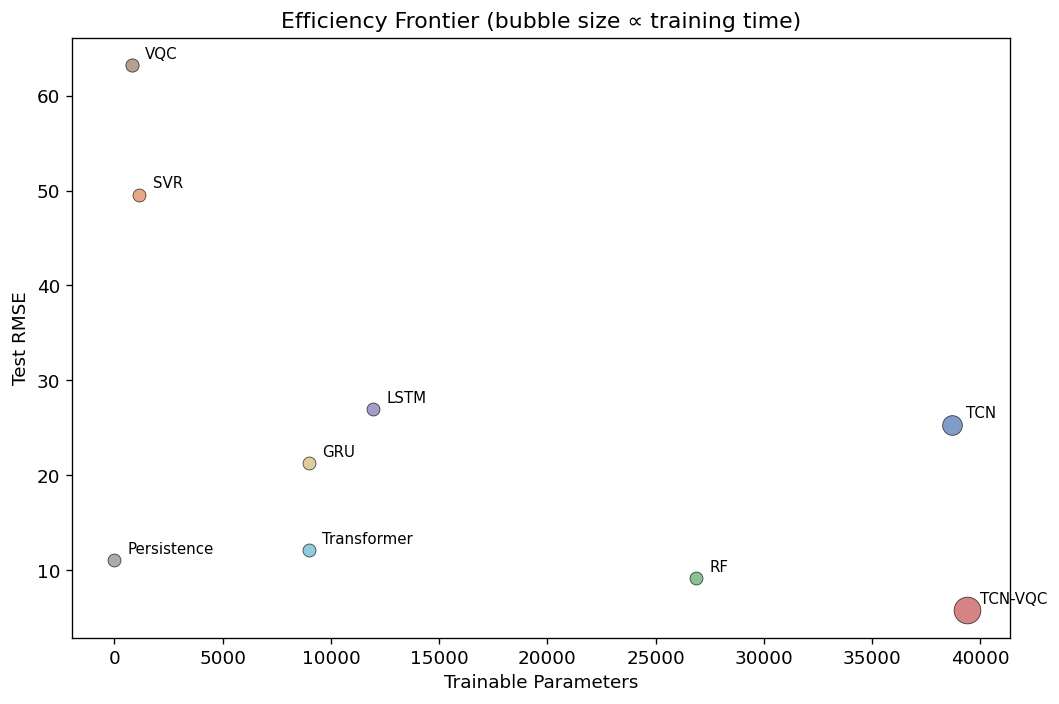

In [ ]:
# --- Infographic 14: Efficiency Frontier — Params vs RMSE (bubble = training time) ---
fig, ax = plt.subplots(figsize=(9, 6))
for _, row in METRICS_DF.iterrows():
    size = max(row["Training_Time_s"], 1) * 0.05 + 60
    ax.scatter(row["Num_Params"], row["RMSE"], s=size, color=MODEL_COLORS[row["Model"]], alpha=0.7,
               edgecolor="black", linewidth=0.5)
    ax.annotate(row["Model"], (row["Num_Params"], row["RMSE"]),
                textcoords="offset points", xytext=(8, 4), fontsize=9)
ax.set_xlabel("Trainable Parameters")
ax.set_ylabel("Test RMSE")
ax.set_title("Efficiency Frontier (bubble size ∝ training time)")
fig.tight_layout()
_savefig(fig, "info14_efficiency_frontier")


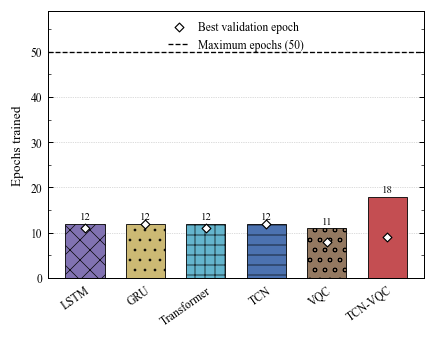

             Epochs trained  Best val epoch
LSTM                     12              11
GRU                      12              12
Transformer              12              11
TCN                      12              12
VQC                      11               8
TCN-VQC                  18               9


In [ ]:
# --- Epochs to convergence (early stopping): IEEE Transactions style ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "ytick.minor.size": 1.8,
    "ytick.right": True,
    "hatch.linewidth": 0.4,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

# hatch per model, so bars stay distinguishable in grayscale print
HATCHES = {
    "TCN-VQC": "", "LSTM": "xx", "GRU": "..", "Transformer": "++", "TCN": "--", "VQC": "oo",
}

FIG_SIZE = (3.5, 2.7)                  # IEEE single column (3.5 in)
SHOW_BEST_EPOCH = True                 # also mark the epoch with the lowest validation loss

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

names = list(TRAINED_NN_MODELS)
trained = np.array([len(HISTORIES[n]["train_loss"]) for n in names])
best = np.array([int(np.argmin(HISTORIES[n]["val_loss"])) + 1 if len(HISTORIES[n]["val_loss"]) else np.nan
                 for n in names])                                     # epochs are 1-based
x = np.arange(len(names))

with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=FIG_SIZE)

    bars = ax.bar(x, trained, width=0.65, color=[MODEL_COLORS[n] for n in names],
                  edgecolor="black", linewidth=0.5, zorder=3)
    for b, n in zip(bars, names):
        b.set_hatch(HATCHES.get(n, ""))

    if SHOW_BEST_EPOCH:
        ax.scatter(x, best, marker="D", s=14, color="white", edgecolor="black",
                   linewidth=0.7, zorder=6, label="Best validation epoch")

    for xi, cnt in zip(x, trained):
        ax.annotate(str(cnt), (xi, cnt), xytext=(0, 1.5), textcoords="offset points",
                    ha="center", va="bottom", fontsize=6.5)

    ax.axhline(CFG.epochs, color="black", linestyle="--", linewidth=0.8, zorder=4,
               label=f"Maximum epochs ({CFG.epochs})")

    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=35, ha="right", rotation_mode="anchor")
    ax.set_ylim(0, CFG.epochs * 1.18)
    ax.yaxis.set_major_locator(MultipleLocator(10 if CFG.epochs <= 100 else 20))
    ax.yaxis.set_minor_locator(MultipleLocator(5 if CFG.epochs <= 100 else 10))
    ax.set_ylabel("Epochs trained")
    ax.grid(True, axis="y", which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.set_axisbelow(True)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=1, frameon=False, handlelength=1.8)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig(os.path.join(out_dir, "epochs_to_convergence.png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, "epochs_to_convergence.pdf"), bbox_inches="tight", pad_inches=0.02)
    plt.show()

print(pd.DataFrame({"Epochs trained": trained, "Best val epoch": best}, index=names))

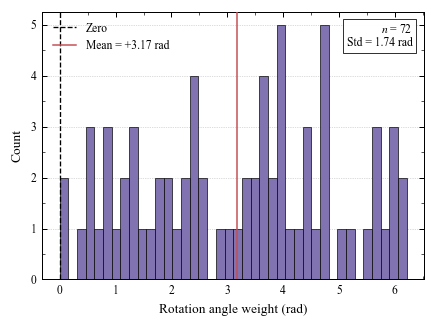

n = 72 (4 layers x 6 qubits x 3) | mean = +3.173 | std = 1.744 | min = -0.000 | max = +6.211 rad


In [ ]:
# --- Trained VQC weight distribution: IEEE Transactions style ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

FIG_SIZE = (3.5, 2.6)                  # IEEE single column (3.5 in)
N_BINS = 40
BAR_COLOR = "#8172B2"

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

w = tcn_vqc_model.qlayer.weights.detach().cpu().numpy().ravel()
mean_w, std_w = w.mean(), w.std()

with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=FIG_SIZE)

    ax.hist(w, bins=N_BINS, color=BAR_COLOR, edgecolor="black", linewidth=0.4, zorder=3)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8, zorder=4, label="Zero")
    ax.axvline(mean_w, color="#C44E52", linestyle="-", linewidth=0.9, zorder=4,
               label=f"Mean = {mean_w:+.2f} rad")

    ax.set_xlabel("Rotation angle weight (rad)")
    ax.set_ylabel("Count")
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.grid(True, axis="y", which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.set_axisbelow(True)

    # sample size and spread in an in-axes box (replaces the title, which IEEE puts in the caption)
    ax.text(0.97, 0.96, f"$n$ = {len(w)}\nStd = {std_w:.2f} rad",
            transform=ax.transAxes, ha="right", va="top", fontsize=7,
            bbox=dict(boxstyle="square,pad=0.3", facecolor="white", edgecolor="black",
                      linewidth=0.5, alpha=0.95), zorder=10)
    ax.legend(loc="upper left", frameon=False, handlelength=2.0)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig(os.path.join(out_dir, "vqc_weight_distribution.png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, "vqc_weight_distribution.pdf"), bbox_inches="tight", pad_inches=0.02)
    plt.show()

print(f"n = {len(w)} ({Q_LAYERS} layers x {N_QUBITS} qubits x 3) | "
      f"mean = {mean_w:+.3f} | std = {std_w:.3f} | min = {w.min():+.3f} | max = {w.max():+.3f} rad")

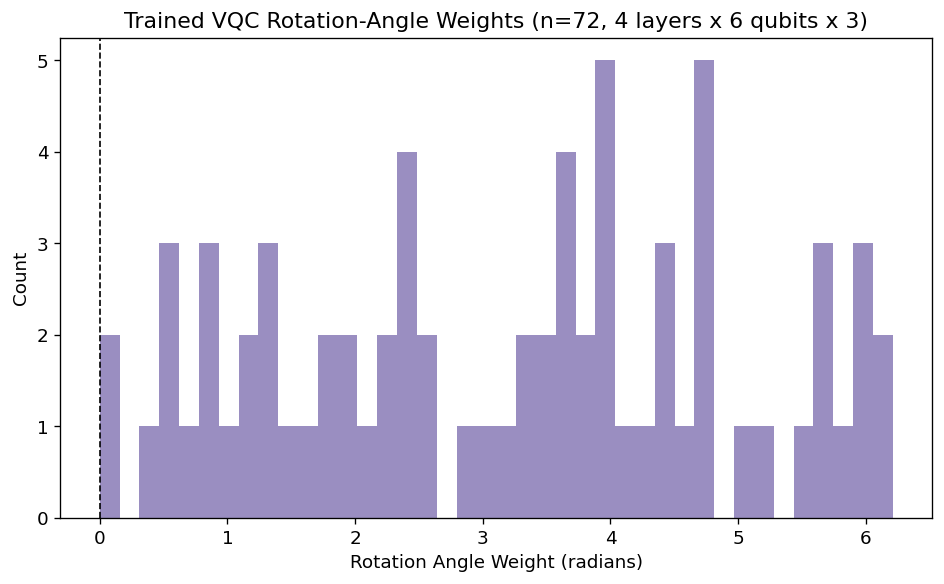

In [ ]:
# --- Infographic 16: Trained VQC Weight Distribution ---
vqc_weights = tcn_vqc_model.qlayer.weights.detach().cpu().numpy().ravel()
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(vqc_weights, bins=40, color="#8172B2", alpha=0.8)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Rotation Angle Weight (radians)")
ax.set_ylabel("Count")
ax.set_title(f"Trained VQC Rotation-Angle Weights (n={len(vqc_weights)}, "
             f"{Q_LAYERS} layers x {N_QUBITS} qubits x 3)")
fig.tight_layout()
_savefig(fig, "info16_vqc_weight_distribution")

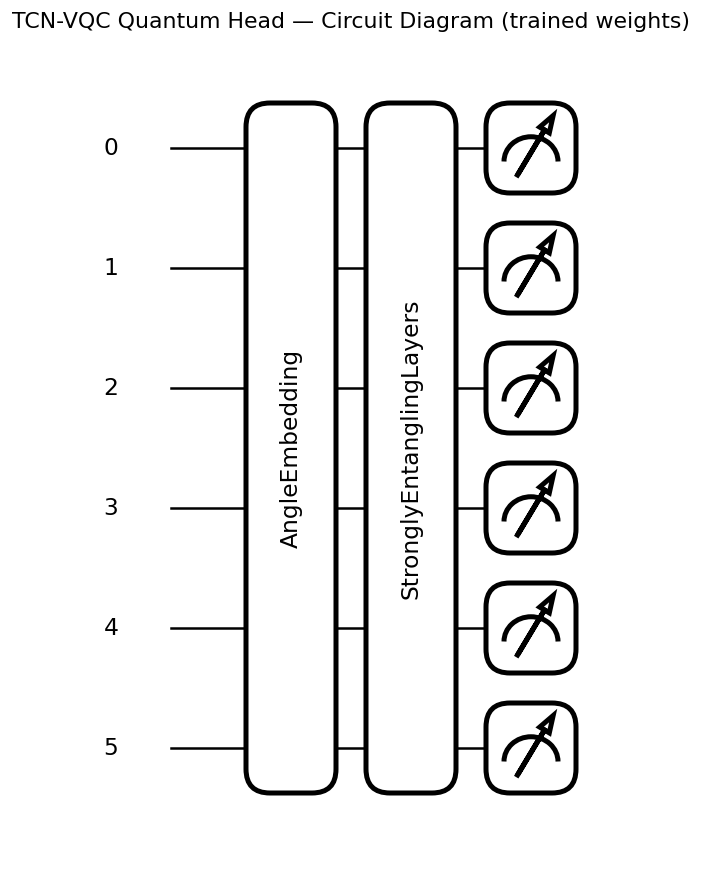

In [ ]:
# --- Infographic 17: Quantum Circuit Diagram ---
_dummy_dev = qml.device("default.qubit", wires=N_QUBITS)


@qml.qnode(_dummy_dev)
def _circuit_for_drawing(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation="Y")
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]


_dummy_inputs = np.zeros(N_QUBITS)
_dummy_weights = tcn_vqc_model.qlayer.weights.detach().cpu().numpy()
fig, _ax = qml.draw_mpl(_circuit_for_drawing)(_dummy_inputs, _dummy_weights)
fig.suptitle("TCN-VQC Quantum Head — Circuit Diagram (trained weights)", y=1.02)
_savefig(fig, "info17_quantum_circuit_diagram")


### --- Residual autocorrelation (TCN-VQC): IEEE Transactions style ---

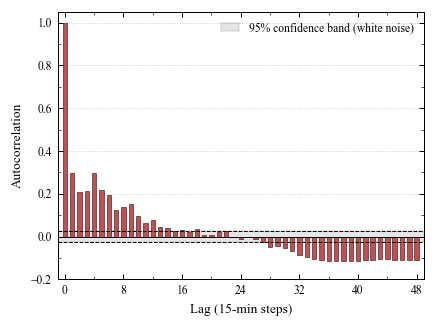

n = 5256 | 95% bound = ±0.0270 | lag-1 ACF = 0.299 | lags outside the band: 38 of 48


In [ ]:
# --- Residual autocorrelation (TCN-VQC): IEEE Transactions style ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

MODEL = "TCN-VQC"
CLIP_AT_ZERO = True                    # PV power can't be negative (same as the other figures)
DAYTIME_ONLY = False                   # True: drop samples where actual <= MAPE_THRESHOLD_MW (see note below)
n_lags = 48                            # 12 hours at 15-min resolution
FIG_SIZE = (3.5, 2.6)                  # IEEE single column (3.5 in). Use (7.16, 2.6) for double-column.

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

# ---------- residuals ----------
y_true, y_pred = PREDICTIONS[MODEL]
y_true = np.asarray(y_true, float).ravel()
y_pred = np.asarray(y_pred, float).ravel()
if CLIP_AT_ZERO:
    y_pred = np.clip(y_pred, 0, None)
resid = y_true - y_pred                                              # residual = Actual - Predicted
if DAYTIME_ONLY:
    resid = resid[y_true > MAPE_THRESHOLD_MW]

resid_c = resid - resid.mean()
acf = np.array([1.0] + [np.corrcoef(resid_c[:-lag], resid_c[lag:])[0, 1] for lag in range(1, n_lags + 1)])
ci = 1.96 / np.sqrt(len(resid))                                      # 95% bound under white noise
lags = np.arange(n_lags + 1)

with mpl.rc_context(IEEE_RC):
    fig, ax = plt.subplots(figsize=FIG_SIZE)

    ax.bar(lags, acf, width=0.6, color=MODEL_COLORS.get(MODEL, "#C44E52"),
           edgecolor="black", linewidth=0.3, zorder=3)
    ax.axhline(0, color="black", linewidth=0.6, zorder=4)
    ax.axhspan(-ci, ci, color="0.6", alpha=0.25, zorder=1, label="95% confidence band (white noise)")
    ax.axhline(ci, color="black", linestyle="--", linewidth=0.6, zorder=4)
    ax.axhline(-ci, color="black", linestyle="--", linewidth=0.6, zorder=4)

    ax.set_xlim(-1, n_lags + 1)
    lo = min(-0.2, acf[1:].min() * 1.15)
    ax.set_ylim(lo, 1.05)
    ax.xaxis.set_major_locator(MultipleLocator(8))                   # every 8 lags = 2 h at 15-min steps
    ax.xaxis.set_minor_locator(MultipleLocator(4))
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    ax.set_xlabel(f"Lag ({CFG.time_step_minutes}-min steps)")
    ax.set_ylabel("Autocorrelation")
    ax.grid(True, axis="y", which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.set_axisbelow(True)
    ax.legend(loc="upper right", frameon=False, handlelength=1.6)

    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig(os.path.join(out_dir, "residual_acf_tcn_vqc.png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, "residual_acf_tcn_vqc.pdf"), bbox_inches="tight", pad_inches=0.02)
    plt.show()

print(f"n = {len(resid)} | 95% bound = ±{ci:.4f} | lag-1 ACF = {acf[1]:.3f} | "
      f"lags outside the band: {(np.abs(acf[1:]) > ci).sum()} of {n_lags}")

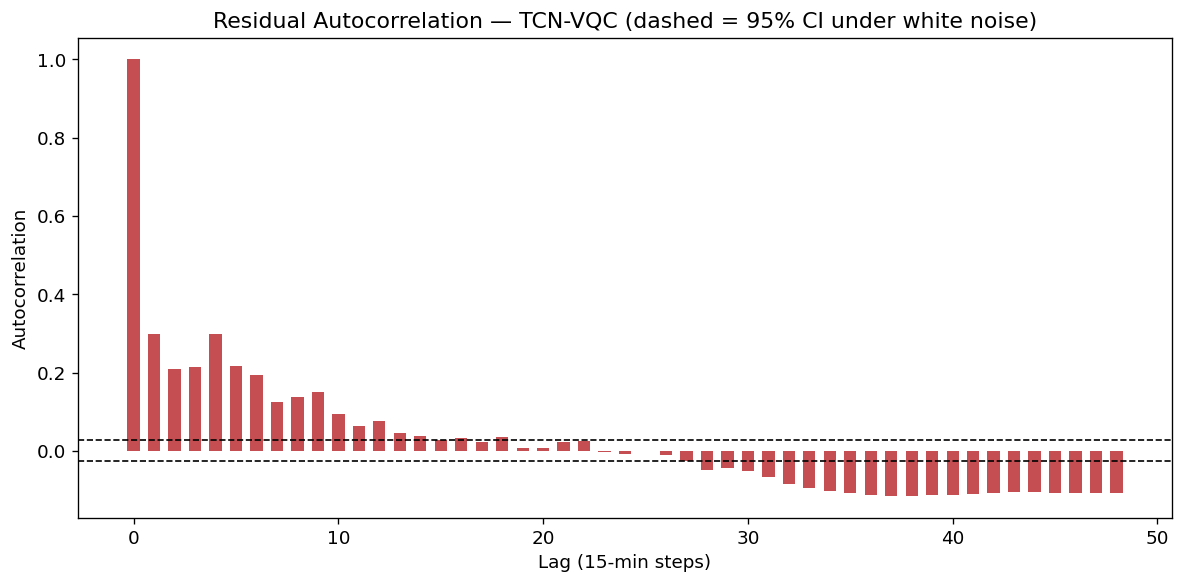

In [ ]:
# --- Infographic 18: Autocorrelation of Residuals (TCN-VQC) ---
y_true, y_pred = PREDICTIONS["TCN-VQC"]
resid = y_true - y_pred
resid_centered = resid - resid.mean()
n_lags = 48  # 12 hours at 15-min resolution
acf = [1.0] + [
    np.corrcoef(resid_centered[:-lag], resid_centered[lag:])[0, 1] for lag in range(1, n_lags + 1)
]
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(n_lags + 1), acf, color="#C44E52", width=0.6)
ci = 1.96 / np.sqrt(len(resid))
ax.axhline(ci, color="black", linestyle="--", linewidth=1)
ax.axhline(-ci, color="black", linestyle="--", linewidth=1)
ax.set_xlabel(f"Lag ({CFG.time_step_minutes}-min steps)")
ax.set_ylabel("Autocorrelation")
ax.set_title("Residual Autocorrelation — TCN-VQC (dashed = 95% CI under white noise)")
fig.tight_layout()
_savefig(fig, "info18_residual_acf")

### --- Q-Q plot of residuals: one separate IEEE-style figure per model ---

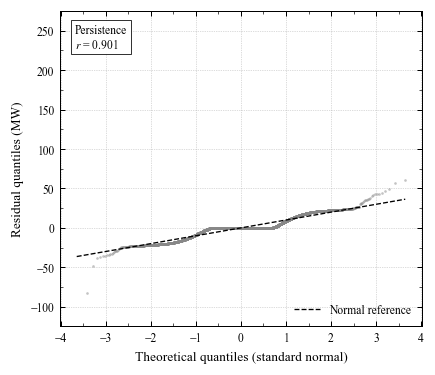

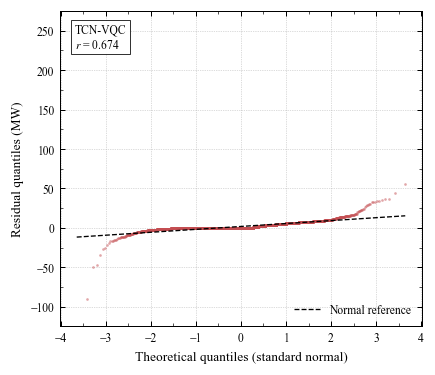

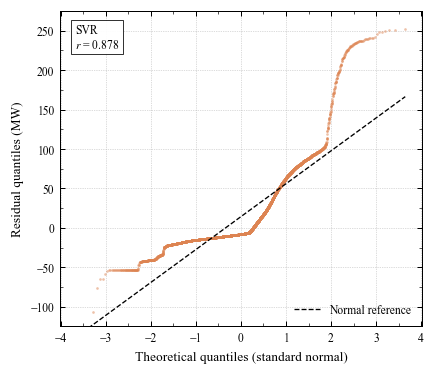

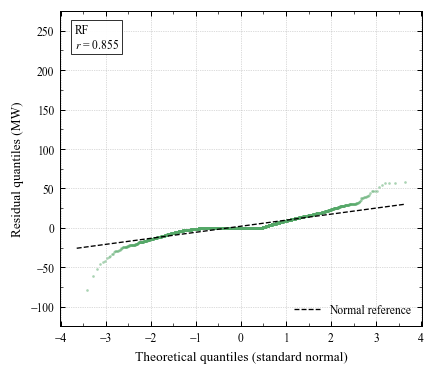

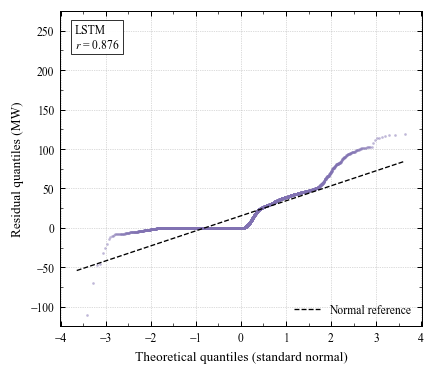

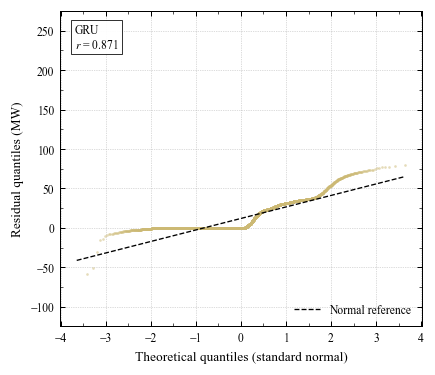

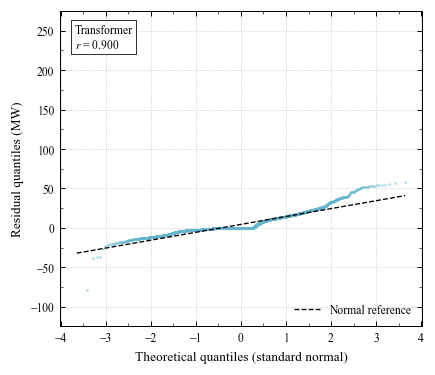

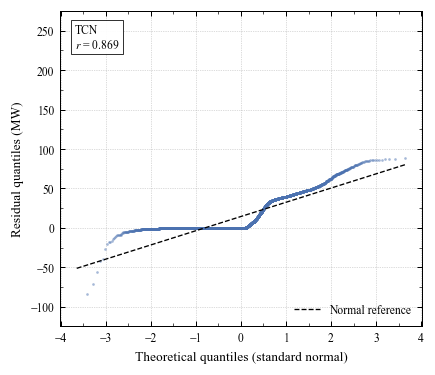

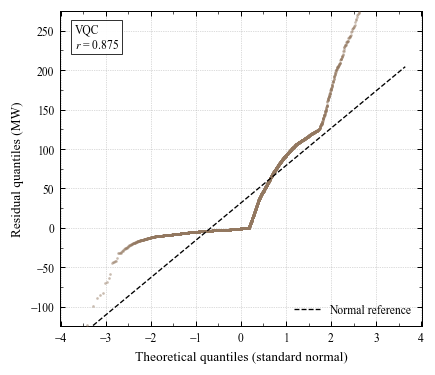

In [ ]:

import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from scipy import stats

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4, "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.minor.size": 1.8, "ytick.minor.size": 1.8,
    "xtick.top": True, "ytick.right": True,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

FIG_SIZE = (3.5, 3.0)                  # IEEE single column (3.5 in)
CLIP_AT_ZERO = True                    # PV power can't be negative (same as the other figures)
SHARED_Y = True                        # same y-range for every model, so the figures are comparable

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

# ---------- residuals and Q-Q quantiles for every model ----------
qq = {}
for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    y_true = np.asarray(y_true, float).ravel()
    y_pred = np.asarray(y_pred, float).ravel()
    if CLIP_AT_ZERO:
        y_pred = np.clip(y_pred, 0, None)
    resid = y_true - y_pred                                          # residual = Actual - Predicted
    (osm, osr), (slope, intercept, r) = stats.probplot(resid, dist="norm", fit=True)
    qq[name] = dict(osm=osm, osr=osr, slope=slope, intercept=intercept, r=r)

all_osr = np.concatenate([d["osr"] for d in qq.values()])
y_lo = np.floor(np.percentile(all_osr, 0.1) / 50) * 50 - 25          # robust limits: ignore a few extreme outliers
y_hi = np.ceil(np.percentile(all_osr, 99.9) / 50) * 50 + 25

with mpl.rc_context(IEEE_RC):
    for name, d in qq.items():
        fig, ax = plt.subplots(figsize=FIG_SIZE)

        ax.scatter(d["osm"], d["osr"], s=2.5, alpha=0.5, color=MODEL_COLORS[name],
                   linewidths=0, rasterized=True, zorder=3)          # rasterized: keeps the PDF small
        xl = np.array([d["osm"].min(), d["osm"].max()])
        ax.plot(xl, d["slope"] * xl + d["intercept"], color="black", linestyle="--",
                linewidth=0.8, zorder=4, label="Normal reference")

        if SHARED_Y:
            ax.set_ylim(y_lo, y_hi)
        ax.xaxis.set_minor_locator(AutoMinorLocator(2))
        ax.yaxis.set_minor_locator(AutoMinorLocator(2))
        ax.set_xlabel("Theoretical quantiles (standard normal)")
        ax.set_ylabel("Residual quantiles (MW)")
        ax.grid(True, which="major", linestyle=":", linewidth=0.4, color="0.7")

        # model name and correlation with the normal line in an in-axes box (replaces the title)
        ax.text(0.04, 0.96, f"{name}\n$r$ = {d['r']:.3f}",
                transform=ax.transAxes, ha="left", va="top", fontsize=7,
                bbox=dict(boxstyle="square,pad=0.3", facecolor="white", edgecolor="black",
                          linewidth=0.5, alpha=0.95), zorder=10)
        ax.legend(loc="lower right", frameon=False, handlelength=2.2)

        fig.tight_layout(pad=0.3)

        # ---------- save: 600 dpi PNG + vector PDF ----------
        fname = "qq_plot_" + name.replace(" ", "_")
        fig.savefig(os.path.join(out_dir, fname + ".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
        fig.savefig(os.path.join(out_dir, fname + ".pdf"), bbox_inches="tight", pad_inches=0.02, dpi=600)
        plt.show()
        plt.close(fig)

In [ ]:
# --- Infographic 20: KPI summary (IEEE Transactions style) ---
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

FIG_SIZE = (7.16, 2.6)                 # IEEE double-column width (7.16 in)
CARD_COLOR = "0.93"                    # light gray cards, neutral in print
EDGE_COLOR = "black"

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

# ---------- values ----------
best_name = RANKED_DF.iloc[0]["Model"]
best = RESULTS[best_name]
persistence = RESULTS["Persistence"]
improve_vs_persistence = (1 - best["RMSE"] / persistence["RMSE"]) * 100

cards = [
    ("Best model",        best_name),
    ("Test RMSE",         f"{best['RMSE']:.2f} MW"),
    ("Test MAPE",         f"{best['MAPE_%']:.2f} %"),
    ("Test $R^2$",        f"{best['R2']:.4f}"),
    ("RMSE vs. persistence", f"{improve_vs_persistence:.1f} % lower"),
    ("Trainable parameters", f"{int(best['Num_Params']):,}"),
]

with mpl.rc_context(IEEE_RC):
    fig, axes = plt.subplots(2, 3, figsize=FIG_SIZE)
    for ax, (label, value) in zip(axes.ravel(), cards):
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        ax.add_patch(Rectangle((0.02, 0.04), 0.96, 0.92, facecolor=CARD_COLOR,
                               edgecolor=EDGE_COLOR, linewidth=0.6))
        ax.text(0.5, 0.60, value, ha="center", va="center", fontsize=13, fontweight="bold")
        ax.text(0.5, 0.22, label, ha="center", va="center", fontsize=8)
    fig.tight_layout(pad=0.3)

    # ---------- save: 600 dpi PNG + vector PDF ----------
    fig.savefig(os.path.join(out_dir, "info20_kpi_summary.png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, "info20_kpi_summary.pdf"), bbox_inches="tight", pad_inches=0.02)
    plt.show()

# ---------- LaTeX table for the paper (recommended instead of the figure) ----------
tbl = pd.DataFrame({"Metric": [c[0].replace("$R^2$", "R2") for c in cards],
                    "Value":  [c[1].replace("$R^2$", "R2") for c in cards]})
print(f"Best model by RMSE ranking: {best_name}")
print(tbl.to_latex(index=False, escape=True))

NameError: name 'CFG' is not defined

# --- MAPE comparison: two separate IEEE-style figures (overall + per-month) ---

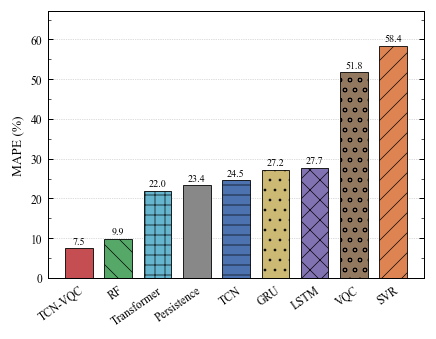

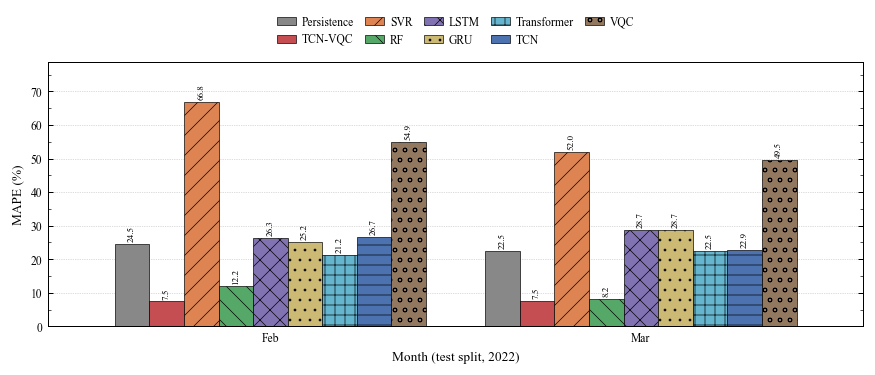

In [ ]:

import os
import calendar
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

IEEE_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "ytick.minor.width": 0.4,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "ytick.minor.size": 1.8,
    "ytick.right": True,
    "hatch.linewidth": 0.4,
    "pdf.fonttype": 42, "ps.fonttype": 42,           # embedded TrueType fonts (IEEE requirement)
    "savefig.dpi": 600,
}

# hatch per model, so bars stay distinguishable in grayscale print
HATCHES = {
    "Persistence": "", "TCN-VQC": "", "SVR": "//", "RF": "\\\\", "LSTM": "xx",
    "GRU": "..", "Transformer": "++", "TCN": "--", "VQC": "oo",
}

out_dir = os.path.join(CFG.out_dir, "plots")
os.makedirs(out_dir, exist_ok=True)

def save_both(fig, stem):
    fig.savefig(os.path.join(out_dir, stem + ".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
    fig.savefig(os.path.join(out_dir, stem + ".pdf"), bbox_inches="tight", pad_inches=0.02)

with mpl.rc_context(IEEE_RC):

    # ================= Figure A: overall test-set MAPE =================
    ordered = METRICS_DF[["Model", "MAPE_%"]].dropna().sort_values("MAPE_%", ascending=True)
    models = ordered["Model"].tolist()
    vals = ordered["MAPE_%"].values.astype(float)
    xa = np.arange(len(models))

    fig, ax = plt.subplots(figsize=(3.5, 2.7))                 # IEEE single column (3.5 in)
    bars = ax.bar(xa, vals, width=0.7, color=[MODEL_COLORS[m] for m in models],
                  edgecolor="black", linewidth=0.5, zorder=3)
    for b, m in zip(bars, models):
        b.set_hatch(HATCHES.get(m, ""))
    for xi, v in zip(xa, vals):
        ax.annotate(f"{v:.1f}", (xi, v), xytext=(0, 1.5), textcoords="offset points",
                    ha="center", va="bottom", fontsize=6)
    ax.set_xticks(xa)
    ax.set_xticklabels(models, rotation=35, ha="right", rotation_mode="anchor")
    ax.set_ylim(0, vals.max() * 1.15)
    ax.yaxis.set_major_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(5))
    ax.set_ylabel("MAPE (%)")
    ax.grid(True, axis="y", which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.set_axisbelow(True)
    fig.tight_layout(pad=0.3)
    save_both(fig, "mape_overall")
    plt.show()
    plt.close(fig)

    # ================= Figure B: per-month MAPE (grouped bars) =================
    months_sorted = sorted(int(m) for m in np.unique(DATA["test_months"]))     # float -> int
    month_labels = [calendar.month_abbr[m] for m in months_sorted]            # Feb, Mar
    x = np.arange(len(months_sorted))
    n_models = len(RESULTS)
    width = 0.84 / n_models

    fig, ax = plt.subplots(figsize=(7.16, 3.0))                # IEEE double-column width (7.16 in)
    ymax = 0.0
    for i, name in enumerate(RESULTS.keys()):
        df_month = PER_MONTH_TABLES[name].copy()
        df_month["Month"] = df_month["Month"].astype(int)
        v = df_month.set_index("Month").reindex(months_sorted)["MAPE_%"].values.astype(float)
        ymax = max(ymax, np.nanmax(v))
        xs = x + (i - (n_models - 1) / 2) * width              # group centred on the tick
        ax.bar(xs, v, width=width, color=MODEL_COLORS[name], edgecolor="black",
               linewidth=0.4, hatch=HATCHES.get(name, ""), label=name, zorder=3)
        for xi, vi in zip(xs, v):
            if np.isfinite(vi):
                ax.annotate(f"{vi:.1f}", (xi, vi), xytext=(0, 1.5), textcoords="offset points",
                            ha="center", va="bottom", fontsize=5.5, rotation=90)
    ax.set_xticks(x)
    ax.set_xticklabels(month_labels)
    ax.set_xlim(-0.6, len(x) - 0.4)
    ax.set_ylim(0, ymax * 1.18)
    ax.yaxis.set_major_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(5))
    ax.set_xlabel("Month (test split, 2022)")
    ax.set_ylabel("MAPE (%)")
    ax.grid(True, axis="y", which="major", linestyle=":", linewidth=0.4, color="0.7")
    ax.set_axisbelow(True)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=5, frameon=False,
              handlelength=1.6, columnspacing=1.0, handletextpad=0.5)
    fig.tight_layout(pad=0.3)
    save_both(fig, "mape_per_month")
    plt.show()
    plt.close(fig)

## 18. Exports

In [ ]:
# NEW (v4): export the predictions of EVERY horizon that was run, not only the active one
for _label, _preds in ALL_PREDICTIONS.items():
    _tag = _label.replace(" ", "")
    for _name, (_yt, _yp) in _preds.items():
        pd.DataFrame({"y_true": _yt, "y_pred": _yp}).to_csv(
            os.path.join(CFG.out_dir, "predictions", f"predictions_{_tag}_{_name.replace(' ', '_')}.csv"), index=False)
print("Exported predictions for horizons:", list(ALL_PREDICTIONS))

for name in RESULTS.keys():
    y_true, y_pred = PREDICTIONS[name]
    pd.DataFrame({"y_true": y_true, "y_pred": y_pred}).to_csv(
        os.path.join(CFG.out_dir, "predictions", f"predictions_{ACTIVE_TAG}_{name.replace(' ', '_')}.csv"), index=False
    )

with open(os.path.join(CFG.out_dir, "metrics", "config_used.json"), "w") as f:
    cfg_dict = {k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.__dict__.items()}
    cfg_dict["seq_len"] = CFG.seq_len
    json.dump(cfg_dict, f, indent=2)

print("All outputs written under:", os.path.abspath(CFG.out_dir))
for sub in ["predictions", "metrics", "plots"]:
    d = os.path.join(CFG.out_dir, sub)
    print(f"  {d}/  -> {len(os.listdir(d))} files")

Exported predictions for horizons: ['15 min', '30 min', '1 h', '2 h', '4 h']
All outputs written under: c:\Users\VICTUS\OneDrive\Desktop\TCN-VQC_Model\outputs_power
  ./outputs_power\predictions/  -> 54 files
  ./outputs_power\metrics/  -> 27 files
  ./outputs_power\plots/  -> 137 files


In [ ]:
# %% [markdown]
# ## 19. Paper tables (Tables I–V) for the TCN-VQC study
# 
# Run **after** Sections 13e–14 in the same kernel (needs `ALL_PREDICTIONS`, `RAW_DF`, `CFG`). Uses only the models and horizons your notebook already has — **no retraining** except Table V.
# 
# | Table | Source |
# |---|---|
# | I – models evaluated | static list of the notebook's models |
# | II – experimental configuration | read live from `CFG` and the circuit definition |
# | III – overall performance (MAE, RMSE, NMAE %, NRMSE %, R²) | recomputed from stored predictions |
# | IV – horizon-wise (NMAE, NRMSE, R²) | same predictions, every horizon you ran |
# | V – ablation | **5 new VQC trainings** (§19g) at one horizon — the only part that trains |
# 
# Normalised errors use `NORM_BASIS` (§19a) — set it to match your paper.

# %%
# ---- 19a. Settings for the paper tables (uses only models/horizons already in your notebook) ----
import time, math, itertools
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# (name in this notebook, short name printed in the tables, category for Table I)
PAPER_MODELS = [
    ("Persistence", "Pers.",   "Benchmark"),
    ("SVR",         "SVR",     "Machine learning"),
    ("RF",          "RF",      "Machine learning"),
    ("LSTM",        "LSTM",    "Deep learning"),
    ("GRU",         "GRU",     "Deep learning"),
    ("Transformer", "Trans.",  "Attention-based"),
    ("TCN",         "TCN",     "Deep learning"),
    ("VQC",         "VQC",     "Quantum"),
    ("TCN-VQC",     "TCN-VQC", "Quantum-enhanced"),      # proposed model
]
SHORT = {n: s for n, s, _ in PAPER_MODELS}
ORDER = [n for n, _, _ in PAPER_MODELS]

# horizons = whatever you already ran in Section 13e (no new training)
PAPER_HORIZONS = [(s, l) for s, l in CFG.horizons if l in ALL_PREDICTIONS]

# Normaliser for NMAE / NRMSE (%):  "peak" = max observed Actual power (MW) | "mean" = mean Actual | "value" = NORM_VALUE
# -> use the same definition as in your paper (e.g. plant rated capacity: NORM_BASIS="value"; NORM_VALUE=<MW>).
NORM_BASIS, NORM_VALUE = "peak", None

# Table III = average of the per-horizon metrics over these horizons (None -> all),
# or set e.g. OVERALL_HORIZONS = ["15 min"] for a single horizon.
OVERALL_HORIZONS = None

def get_norm() -> float:
    a = RAW_DF[CFG.target_col].values.astype(float)
    v = {"peak": a.max(), "mean": a.mean(), "value": NORM_VALUE}[NORM_BASIS]
    assert v and v > 0, "NORM_VALUE must be set (>0) when NORM_BASIS='value'"
    return float(v)

NORM = get_norm()
print(f"Normaliser for NMAE/NRMSE: {NORM_BASIS} = {NORM:.3f} (same units as `{CFG.target_col}`)")
print("Horizons:", [l for _, l in PAPER_HORIZONS])


# %%
# ---- 19b. Collect the predictions you already have: PAPER_PREDS[horizon][model] = (y_true, y_pred)  (no training) ----
PAPER_PREDS = {l: {m: ALL_PREDICTIONS[l][m] for m in ORDER} for _, l in PAPER_HORIZONS}
print({l: len(v) for l, v in PAPER_PREDS.items()}, "models per horizon")


# %%
# ---- 19c. Metrics for every (horizon, model): MAE, RMSE, NMAE %, NRMSE %, R2 ----
def paper_metrics(y_true, y_pred, norm=NORM) -> dict:
    mae = mean_absolute_error(y_true, y_pred)
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    return {"MAE": mae, "RMSE": rmse, "NMAE": 100 * mae / norm, "NRMSE": 100 * rmse / norm, "R2": r2_score(y_true, y_pred)}

PAPER_DF = pd.DataFrame([
    {"Horizon": h, "Model": m, **paper_metrics(*PAPER_PREDS[h][m])}
    for _, h in PAPER_HORIZONS for m in ORDER
])
H_ORDER = [l for _, l in PAPER_HORIZONS]
print(f"{len(PAPER_DF)} rows = {len(H_ORDER)} horizons x {len(ORDER)} models")


# %%
# ---- Table I: forecasting models evaluated ----
TABLE_I = pd.DataFrame([{"Category": c, "Model": ("Proposed TCN-VQC (hybrid)" if n == "TCN-VQC" else
                         {"RF": "Random Forest (RF)", "Persistence": "Persistence"}.get(n, n))}
                        for n, _, c in PAPER_MODELS])
print("TABLE I - Forecasting models evaluated in the experimental study")
display(TABLE_I)


# %%
# ---- Table II: experimental configuration (read live from CFG / the circuit definition) ----
_in_vars = ", ".join(CFG.raw_feature_cols) + ", " + ", ".join(CFG.engineered_cols)
TABLE_II = pd.DataFrame([
    ("Sampling interval",        f"{CFG.time_step_minutes} min"),
    ("Look-back window L",       f"{CFG.seq_len} steps ({CFG.lookback_hours:g} h) proposed; {CFG.baseline_seq_len} steps ({CFG.baseline_seq_len*CFG.time_step_minutes/60:g} h) baselines"),
    ("Forecast horizons",        f"{PAPER_HORIZONS[0][1]} - {PAPER_HORIZONS[-1][1]}  ({', '.join(l for _, l in PAPER_HORIZONS)})"),
    ("Input variables",          f"PV power + meteorological variables ({len(CFG.feature_cols)} proposed / {len(CFG.baseline_feature_cols)} baselines)"),
    ("Normalization",            "Min-max (fit on training split only)"),
    ("Quantum encoding",         "Angle encoding (R_y), inputs bounded to [-pi, pi] by tanh"),
    ("Qubits, n_q",              f"{CFG.n_qubits} (main); 4 / 6 / 8 in sensitivity study"),
    ("VQC depth, M",             f"{CFG.q_layers} (main); 1-4 in sensitivity study"),
    ("Single-qubit gates",       "Rot(phi, theta, omega) = R_z R_y R_z  (3 trainable angles / qubit / layer)"),
    ("Entanglement",             "CNOT, StronglyEntanglingLayers pattern (range r = (l mod (n_q-1)) + 1)"),
    ("Measurement",              "Pauli-Z expectation on every qubit"),
    ("Output layer",             "Linear regression on <Z>, added to last observed power (residual form)"),
    ("Loss",                     f"MSE + {CFG.mape_loss_weight:g} x masked MAPE (hybrid)"),
    ("Optimizer",                f"Adam (lr={CFG.lr:g}, weight decay={CFG.weight_decay:g}, grad-clip {CFG.grad_clip_norm:g}, ReduceLROnPlateau)"),
    ("Measurement shots S",      "Exact expectation values (analytic simulation, no shot noise)"),
    ("Random seeds",             f"{CFG.seed} (main run); see ABL_SEEDS in 19g for the ablation"),
    ("TCN backbone",             f"channels {CFG.tcn_channels}, kernel {CFG.tcn_kernel_size}, dropout {CFG.tcn_dropout}"),
    ("Data split",               f"Chronological {CFG.train_frac:.0%} / {CFG.val_frac:.0%} / {1-CFG.train_frac-CFG.val_frac:.0%}"),
], columns=["Parameter", "Configuration"])
print("TABLE II - Experimental configuration")
display(TABLE_II)


# %%
# ---- Table III: overall forecasting performance (mean over OVERALL_HORIZONS) ----
_hs = OVERALL_HORIZONS or H_ORDER
_ov = PAPER_DF[PAPER_DF.Horizon.isin(_hs)].groupby("Model")[["MAE", "RMSE", "NMAE", "NRMSE", "R2"]].mean().reindex(ORDER)
TABLE_III = _ov.rename(index=SHORT).rename(columns={"NMAE": "NMAE (%)", "NRMSE": "NRMSE (%)", "R2": "R²"}).reset_index()
print(f"TABLE III - Overall forecasting performance (average over horizons: {', '.join(_hs)})")
display(TABLE_III.round(4))
print("Best per metric:", {c: TABLE_III.loc[TABLE_III[c].idxmax() if c == "R²" else TABLE_III[c].idxmin(), "Model"]
                           for c in ["MAE", "RMSE", "NMAE (%)", "NRMSE (%)", "R²"]})


# %%
# ---- Table IV: horizon-wise performance (NMAE, NRMSE, R2 per horizon x model) ----
_rows = []
for h in H_ORDER:
    sub = PAPER_DF[PAPER_DF.Horizon == h].set_index("Model").reindex(ORDER)
    for key, nm in (("NMAE", "NMAE"), ("NRMSE", "NRMSE"), ("R2", "R²")):
        _rows.append({"H": h, "Metric": nm, **{SHORT[m]: sub.loc[m, key] for m in ORDER}})
TABLE_IV = pd.DataFrame(_rows)
print("TABLE IV - Horizon-wise forecasting performance")
display(TABLE_IV.set_index(["H", "Metric"]).round(4))


# %% [markdown]
# ### 19g. Ablation variants (Table V) — new training runs
# 
# Each variant changes **one** thing relative to the full TCN-VQC and is trained with the identical recipe (hybrid loss, Adam, scheduler, early stopping) on the identical data:
# 
# | Variant | Change |
# |---|---|
# | Full VQC | `Rot` layers + CNOT entanglers, `n_q`/`M` from `CFG` (rebuilt with the custom circuit below, which is the same as `StronglyEntanglingLayers`; a check against the main run is printed) |
# | Without entanglement | CNOTs removed — independent single-qubit rotations only |
# | Reduced depth | `M = ABL_REDUCED_DEPTH` layers (default 1) |
# | Without projection | the `pre_net` MLP is removed; the TCN's last channel width is set to `n_q`, so its pooled output feeds the angle embedding directly |
# | Reduced qubits | `n_q = ABL_REDUCED_QUBITS` (default 4) |
# 
# Cost: 5 variants × `len(ABL_SEEDS)` VQC trainings at one horizon. Add seeds to `ABL_SEEDS` for mean ± std (your Table II says "multiple seeds").

# %%
# ---- 19g. Ablation models ----
ABL_HORIZON = "15 min"
ABL_SEEDS = (CFG.seed,)                  # e.g. (42, 43, 44) for mean ± std
ABL_REDUCED_DEPTH, ABL_REDUCED_QUBITS = 1, 4


def make_vqc_layer_custom(n_qubits: int, q_layers: int, entangle: bool = True):
    """Same circuit as StronglyEntanglingLayers (Rot on every wire, CNOT range r=(l mod (n-1))+1),
    but with the CNOT block switchable so entanglement can be ablated in isolation."""
    dev = qml.device("default.qubit", wires=n_qubits)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="Y")
        for l in range(q_layers):
            for w in range(n_qubits):
                qml.Rot(weights[l, w, 0], weights[l, w, 1], weights[l, w, 2], wires=w)
            if entangle and n_qubits > 1:
                r = (l % (n_qubits - 1)) + 1
                for w in range(n_qubits):
                    qml.CNOT(wires=[w, (w + r) % n_qubits])
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

    return qml.qnn.TorchLayer(circuit, {"weights": (q_layers, n_qubits, 3)})


class TCN_VQC_Ablation(nn.Module):
    """TCN_VQC_Model with switches: entangle (CNOTs on/off) and project (pre_net MLP on/off)."""
    def __init__(self, n_features: int, cfg: Config, entangle: bool = True, project: bool = True):
        super().__init__()
        self.actual_idx = cfg.feature_cols.index("Actual")
        self.project = project
        channels = tuple(cfg.tcn_channels) if project else tuple(cfg.tcn_channels[:-1]) + (cfg.n_qubits,)
        self.tcn = TemporalConvNet(n_features, channels, cfg.tcn_kernel_size, cfg.tcn_dropout)
        if project:
            self.pre_net = nn.Sequential(nn.Linear(channels[-1], 16), nn.ReLU(), nn.Linear(16, cfg.n_qubits))
        self.qlayer = make_vqc_layer_custom(cfg.n_qubits, cfg.q_layers, entangle)
        self.post_net = nn.Linear(cfg.n_qubits, 1)
        nn.init.zeros_(self.post_net.bias)

    def forward(self, x):
        last_val = x[:, -1, self.actual_idx].unsqueeze(-1)
        pooled = self.tcn(x)[:, -1, :]
        z = self.pre_net(pooled) if self.project else pooled
        angles = torch.tanh(z) * math.pi
        return last_val + self.post_net(self.qlayer(angles))


ABL_VARIANTS = {   # name -> (Config overrides, model switches)
    "Full VQC":             ({}, {}),
    "Without entanglement": ({}, {"entangle": False}),
    "Reduced depth":        ({"q_layers": ABL_REDUCED_DEPTH}, {}),
    "Without projection":   ({}, {"project": False}),
    "Reduced qubits":       ({"n_qubits": ABL_REDUCED_QUBITS}, {}),
}


def train_eval_vqc_variant(data, loaders, hybrid_loss, cfg_v, **switches):
    set_seed(cfg_v.seed)
    model = TCN_VQC_Ablation(data["n_features"], cfg_v, **switches)
    tr, va, te = loaders
    model, hist, t_train = train_model(model, tr, va, cfg_v, verbose=False, criterion=hybrid_loss)
    y_true, y_pred, _ = evaluate_model(model, te, data["target_scaler"], cfg_v, clip=True)
    return {**paper_metrics(y_true, y_pred), "epochs": len(hist["train_loss"]), "train_s": t_train,
            "params": count_parameters(model)}


_steps = dict((l, s) for s, l in PAPER_HORIZONS)[ABL_HORIZON]
_cfg_h = replace(CFG, horizon_steps=_steps)
_data = prepare_data(RAW_DF, _cfg_h)
_loaders = make_loaders(_data, _cfg_h.batch_size)
_hybrid = make_hybrid_loss(_cfg_h.mape_loss_weight, _cfg_h.mape_eps_mw / _data["target_scaler"].data_max_[0])

try:
    ABL_RUNS
except NameError:
    ABL_RUNS = {}                          # (variant, seed) -> metrics ; resumable
for name, (cfg_over, switches) in ABL_VARIANTS.items():
    for seed in ABL_SEEDS:
        if (name, seed) in ABL_RUNS:
            continue
        t0 = time.time()
        ABL_RUNS[(name, seed)] = train_eval_vqc_variant(_data, _loaders, _hybrid,
                                                        replace(_cfg_h, seed=seed, **cfg_over), **switches)
        r = ABL_RUNS[(name, seed)]
        print(f"{name:<22} seed={seed}  MAE={r['MAE']:.4f}  NRMSE={r['NRMSE']:.3f}%  R2={r['R2']:.4f}  "
              f"epochs={r['epochs']}  params={r['params']}  ({time.time()-t0:.0f}s)")

# consistency check: 'Full VQC' (custom circuit) vs. the TCN-VQC from the main run at the same horizon/seed
if CFG.seed in ABL_SEEDS and ABL_HORIZON in PAPER_PREDS:
    _m = paper_metrics(*PAPER_PREDS[ABL_HORIZON]["TCN-VQC"])
    print(f"\nCheck vs main run ({ABL_HORIZON}): R2 main={_m['R2']:.4f}  ablation-'Full'={ABL_RUNS[('Full VQC', CFG.seed)]['R2']:.4f}")
del _data, _loaders
gc.collect()


# %%
# ---- Table V: ablation study ----
def _fmt(vals, nd):
    vals = np.asarray(vals, float)
    return f"{vals.mean():.{nd}f}" if len(vals) == 1 else f"{vals.mean():.{nd}f} ± {vals.std(ddof=1):.{nd}f}"

_rows = []
for name in ABL_VARIANTS:
    runs = [ABL_RUNS[(name, s)] for s in ABL_SEEDS if (name, s) in ABL_RUNS]
    _rows.append({"Configuration": name, "MAE": _fmt([r["MAE"] for r in runs], 4),
                  "NRMSE (%)": _fmt([r["NRMSE"] for r in runs], 3), "R²": _fmt([r["R2"] for r in runs], 4)})
TABLE_V = pd.DataFrame(_rows)
print(f"TABLE V - Ablation study of the proposed quantum forecasting framework  "
      f"(horizon {ABL_HORIZON}, {len(ABL_SEEDS)} seed{'s' if len(ABL_SEEDS) > 1 else ''})")
display(TABLE_V)


# %% [markdown]
# ### 19h. (Optional) Qubit × depth sensitivity — backs the "Qubits 4, 6, 8 / depth 1–4" rows of Table II
# 
# 12 VQC trainings per seed (3 qubit counts × 4 depths). Off by default; set `RUN_SENSITIVITY = True` to run it. Reuses the ablation model and data from 19g.

# %%
# ---- 19h. Optional sensitivity grid ----
RUN_SENSITIVITY = False
SENS_QUBITS, SENS_DEPTHS = (4, 6, 8), (1, 2, 3, 4)

if RUN_SENSITIVITY:
    _data = prepare_data(RAW_DF, _cfg_h)
    _loaders = make_loaders(_data, _cfg_h.batch_size)
    _hybrid = make_hybrid_loss(_cfg_h.mape_loss_weight, _cfg_h.mape_eps_mw / _data["target_scaler"].data_max_[0])
    SENS = {}
    for nq, M in itertools.product(SENS_QUBITS, SENS_DEPTHS):
        SENS[(nq, M)] = [train_eval_vqc_variant(_data, _loaders, _hybrid,
                                                replace(_cfg_h, seed=s, n_qubits=nq, q_layers=M)) for s in ABL_SEEDS]
        print(f"n_q={nq} M={M}: R2={np.mean([r['R2'] for r in SENS[(nq, M)]]):.4f}")
    for key, nd in (("NRMSE", 3), ("R2", 4)):
        print(f"\n=== {key}: rows = qubits, cols = depth M ===")
        display(pd.DataFrame({M: {nq: np.mean([r[key] for r in SENS[(nq, M)]]) for nq in SENS_QUBITS}
                              for M in SENS_DEPTHS}).round(nd))
    del _data, _loaders
    gc.collect()
else:
    print("Skipped (RUN_SENSITIVITY=False).")



_pt = os.path.join(CFG.out_dir, "metrics", "paper_tables")
os.makedirs(_pt, exist_ok=True)
_tables = {"table_I_models": TABLE_I, "table_II_config": TABLE_II, "table_III_overall": TABLE_III,
           "table_IV_horizon": TABLE_IV, "table_V_ablation": TABLE_V}
for name, df in _tables.items():
    df.to_csv(os.path.join(_pt, name + ".csv"), index=False)
    try:
        with open(os.path.join(_pt, name + ".tex"), "w", encoding="utf-8") as f:
            f.write(df.to_latex(index=False, float_format="%.3f", escape=True))
    except Exception as e:                      # to_latex needs jinja2 in recent pandas
        print(f"  (LaTeX skipped for {name}: {e})")
PAPER_DF.to_csv(os.path.join(_pt, "all_metrics_long.csv"), index=False)
print("Saved to", os.path.abspath(_pt), "->", sorted(os.listdir(_pt)))

NameError: name 'CFG' is not defined